# Bike-Sharing Challenge

1. Data Exploration and Preprocessing Task
2. Unsupervised Tasks: Bike Trip and Stations Profiles
   - Part A — Clustering Bike Trips
   - Part B — Clustering Bike-Sharing Stations
3. Supervised Task: Predict Station Availability

# 1. Data Exploration and Preprocessing Task

In [1]:
from pathlib import Path

# Project folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR = ROOT / "data_cleaned"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
print("Raw data folder:", ROOT)
print("Cleaned data folder:", CLEAN_DIR)

Raw data folder: /media/lucho/Data/IMT-26-27/machine_learning/challenge
Cleaned data folder: /media/lucho/Data/IMT-26-27/machine_learning/challenge/data_cleaned


## 1.1 Cities (`cities.csv`)

#### 1. Load the data

`pd.read_csv()` reads a CSV file into a pandas DataFrame, which is a table.
The project folder (`ROOT`) is defined once in the setup cell at the top of this notebook.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Project folder (ROOT is defined in the setup cell).
project_folder = str(ROOT)

cities = pd.read_csv(project_folder + "/cities.csv")
cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [3]:
# Show the number of rows and columns.
print("Rows:", cities.shape[0])
print("Columns:", cities.shape[1])

# Show column names, data types, and non-missing counts.
cities.info()

Rows: 267
Columns: 7
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 19.5 KB


#### 2. Check data quality

Check missing values before deciding how to handle them. Also check duplicate rows and duplicate IDs.
An ID should identify only one scheme.

In [4]:
# Count missing values in each column.
cities.isna().sum()

id                         0
name                       0
lat                        0
lon                        0
timezone                   0
country                    0
return_to_official_only    0
dtype: int64

In [5]:
print("Duplicate rows:", cities.duplicated().sum())
print("Duplicate IDs:", cities["id"].duplicated().sum())

# Count names with spaces at the beginning or end.
extra_spaces = cities["name"] != cities["name"].str.strip()
print("Names with extra spaces:", extra_spaces.sum())

cities.loc[extra_spaces, ["id", "name"]]

Duplicate rows: 0
Duplicate IDs: 0
Names with extra spaces: 2


,id,name
64,745,Stari Grad
143,617,Split


In [6]:
# Valid latitude is between -90 and 90.
# Valid longitude is between -180 and 180.
invalid_coordinates = cities[
    ~cities["lat"].between(-90, 90)
    | ~cities["lon"].between(-180, 180)
]

print("Rows with missing or out-of-range coordinates:", len(invalid_coordinates))
invalid_coordinates

Rows with missing or out-of-range coordinates: 0


,id,name,lat,lon,timezone,country,return_to_official_only


**Results:** The supplied data contains 267 rows and 7 columns. There are no missing values,
no duplicate rows, no duplicate IDs, and no missing or out-of-range coordinates.
Two scheme names have trailing spaces. No missing-value imputation is needed for this file.

#### 3. Clean the data

Make a copy so the original table stays available for comparison. Remove extra spaces,
standardize country codes to uppercase, and remove exact duplicate rows if any exist.
Do not delete different IDs just because they have the same location.

In [7]:
cities_clean = cities.copy()

# Remove spaces at the beginning and end of text values.
cities_clean["name"] = cities_clean["name"].str.strip()
cities_clean["country"] = cities_clean["country"].str.strip().str.upper()
cities_clean["timezone"] = cities_clean["timezone"].str.strip()

# Remove only completely identical rows.
cities_clean = cities_clean.drop_duplicates()

print("Rows after cleaning:", len(cities_clean))
cities_clean.head()

Rows after cleaning: 267


,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [8]:
# Compare the names that needed cleaning.
name_changes = pd.DataFrame({
    "id": cities.loc[extra_spaces, "id"],
    "before": cities.loc[extra_spaces, "name"],
    "after": cities_clean.loc[extra_spaces, "name"]
})
name_changes

,id,before,after
64,745,Stari Grad,Stari Grad
143,617,Split,Split


**Cleaning result:** Trailing spaces were removed from `Stari Grad` and `Split`.
All 267 scheme records are retained. Pandas already reads `id` as an integer,
coordinates as numbers, and `return_to_official_only` as a boolean for this CSV.

#### 4. Count schemes by country

`value_counts()` counts how often each value appears. These are counts of supplied schemes,
not counts of trips or measurements of country population.

In [9]:
country_counts = cities_clean["country"].value_counts()
print("Number of countries:", cities_clean["country"].nunique())
country_counts

Number of countries: 15


country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

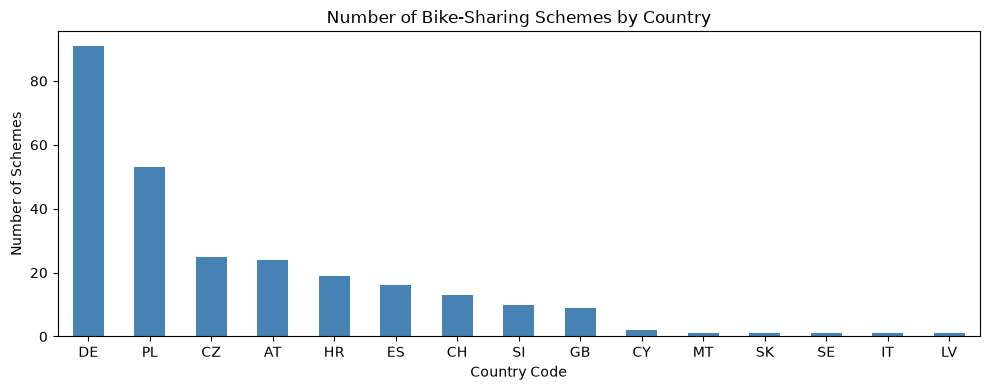

In [10]:
country_counts.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Number of Bike-Sharing Schemes by Country")
plt.xlabel("Country Code")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Calculate the share of schemes in Germany and Poland together.
top_two_share = (country_counts["DE"] + country_counts["PL"]) / len(cities_clean) * 100
print("Germany and Poland together:", round(top_two_share, 1), "%")

Germany and Poland together: 53.9 %


**Result:** The data covers 15 countries. Germany has 91 schemes and Poland has 53.
Together they account for 53.9% of the table, so pooled comparisons will be strongly
influenced by these two countries.

#### 5. Explore return rules

`True` means bikes must be returned to an official station. `False` means this particular
requirement does not apply; it does not mean the scheme has no stations.

In [12]:
return_counts = cities_clean["return_to_official_only"].value_counts()
return_counts

return_to_official_only
True     200
False     67
Name: count, dtype: int64

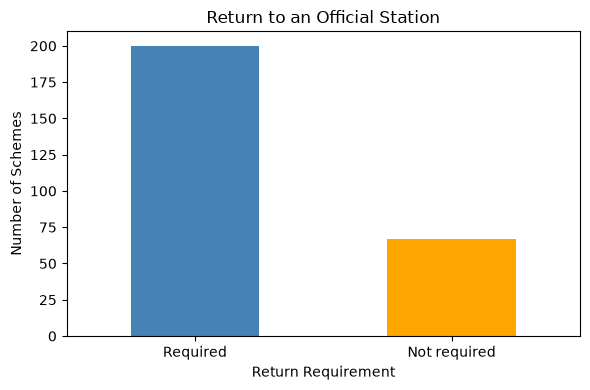

In [13]:
# Put the bars in a fixed order and give them readable labels.
return_counts = return_counts.reindex([True, False], fill_value=0)
return_counts.index = ["Required", "Not required"]

return_counts.plot(kind="bar", figsize=(6, 4), color=["steelblue", "orange"])
plt.title("Return to an Official Station")
plt.xlabel("Return Requirement")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# A cross-tabulation counts combinations of two columns.
return_by_country = pd.crosstab(
    cities_clean["country"],
    cities_clean["return_to_official_only"]
)
return_by_country = return_by_country.rename(columns={True: "Required", False: "Not required"})
return_by_country

return_to_official_only,Not required,Required
country,,
AT,14,10
CH,2,11
CY,1,1
CZ,20,5
DE,22,69
ES,1,15
GB,0,9
HR,0,19
IT,0,1


**Result:** 200 schemes (74.9%) require official-station returns; 67 do not.
The cross-tabulation shows differences across countries, but the number of schemes
per country varies. This field will be useful when interpreting missing station IDs in trip data.

#### 6. Explore locations

`describe()` summarizes the coordinates. The scatter plot shows approximate scheme centers.
It is a simple longitude/latitude plot, not a geographic map with distance-preserving axes.

In [15]:
cities_clean[["lat", "lon"]].describe()

,lat,lon
count,267.000000,267.000000
mean,49.067596,12.154192
std,4.155125,7.029840
min,27.815400,-15.518200
25%,47.827850,8.306550
50%,49.898000,13.744600
75%,51.589750,16.831200
max,57.690200,33.453500


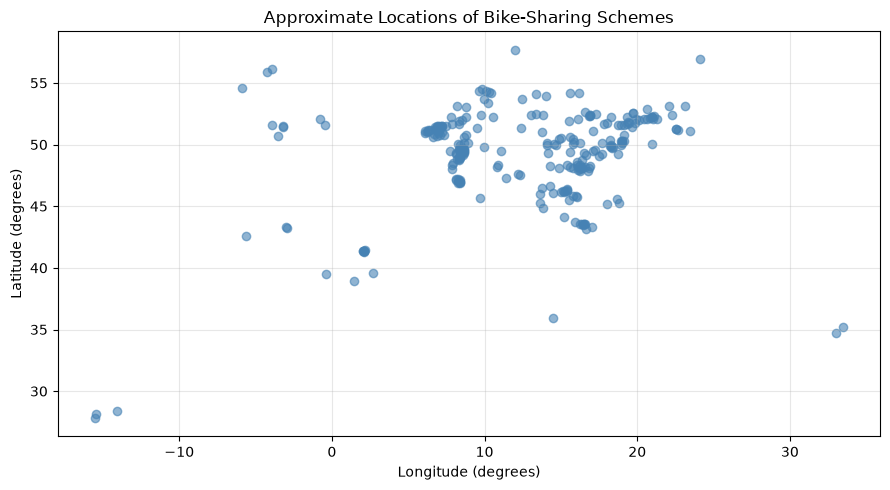

In [16]:
plt.figure(figsize=(9, 5))
plt.scatter(cities_clean["lon"], cities_clean["lat"], alpha=0.6, color="steelblue")
plt.title("Approximate Locations of Bike-Sharing Schemes")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# keep=False marks every row in a group with shared coordinates.
shared_locations = cities_clean[
    cities_clean.duplicated(subset=["lat", "lon"], keep=False)
]
shared_locations[["id", "name", "country", "lat", "lon"]]

,id,name,country,lat,lon
35,251,Lublin,PL,51.2469,22.5697
241,729,Stacje Sponsorskie Nextbike LRM,PL,51.2469,22.5697


**Result:** Lublin and Stacje Sponsorskie Nextbike LRM share the same coordinates but have
different IDs. Both are kept because shared approximate centers do not prove duplicate schemes.
The Canary Islands explain the group of points southwest of most other records.

#### 7. Explore timezone labels

Count the recorded timezone labels and compare them with country codes. A label naming
another country is a reason to inspect the metadata, not a reason to replace it automatically.

In [18]:
timezone_counts = cities_clean["timezone"].value_counts()
timezone_counts

timezone
Europe/Berlin        184
Europe/Warsaw         52
Europe/Brussels       14
Europe/London          9
Atlantic/Canary        3
Asia/Istanbul          2
Europe/Bratislava      1
Europe/Rome            1
Europe/Riga            1
Name: count, dtype: int64

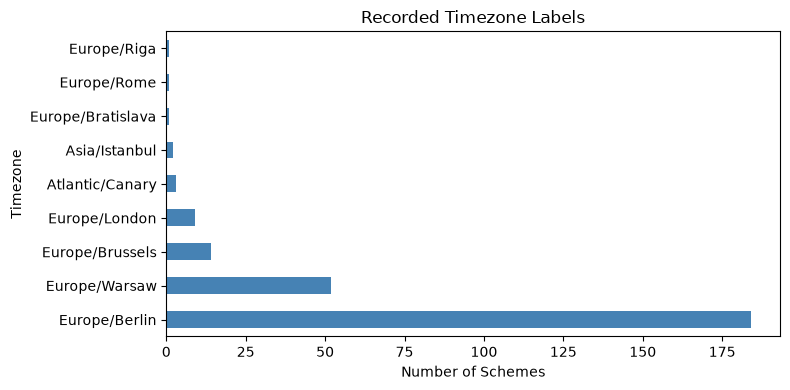

In [19]:
timezone_counts.plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.title("Recorded Timezone Labels")
plt.xlabel("Number of Schemes")
plt.ylabel("Timezone")
plt.tight_layout()
plt.show()

In [20]:
pd.crosstab(cities_clean["country"], cities_clean["timezone"])

timezone,Asia/Istanbul,Atlantic/Canary,Europe/Berlin,Europe/Bratislava,Europe/Brussels,Europe/London,Europe/Riga,Europe/Rome,Europe/Warsaw
country,,,,,,,,,
AT,0,0,24,0,0,0,0,0,0
CH,0,0,0,0,13,0,0,0,0
CY,2,0,0,0,0,0,0,0,0
CZ,0,0,25,0,0,0,0,0,0
DE,0,0,90,0,0,0,0,1,0
ES,0,3,12,0,1,0,0,0,0
GB,0,0,0,0,0,9,0,0,0
HR,0,0,19,0,0,0,0,0,0
IT,0,0,1,0,0,0,0,0,0


**Result:** There are 9 timezone labels. `Europe/Berlin` appears in 184 records across
several countries. Check timezone suitability before using it to create local-hour features.
Do not replace timezone labels based only on their names or use one fixed UTC offset for all dates.

#### 8. Save the cleaned data

Save to a new file so the raw CSV stays unchanged. The CSV contains data only;
when loading it again, pandas infers the column types.

In [21]:
output_folder = str(CLEAN_DIR)
os.makedirs(output_folder, exist_ok=True)

cities_clean.to_csv(output_folder + "/cities_clean.csv", index=False)
print("Cleaned data saved to data_cleaned/cities_clean.csv")
print("Final shape:", cities_clean.shape)

Cleaned data saved to data_cleaned/cities_clean.csv
Final shape: (267, 7)


#### Main findings

- The table contains 267 schemes across 15 countries.
- No missing values or duplicate IDs were found. Two names needed whitespace cleaning.
- Germany and Poland account for 53.9% of the supplied schemes.
- 74.9% of schemes require a return to an official station.
- Two different scheme IDs share the same coordinates and are retained.
- Timezone labels need review before creating local-time features.
- This table describes schemes. Trip and station-status data are needed to study usage and demand.

## 1.2 Bikes and bike types (`bikes.csv`, `bike_types.csv`)

### Bike types: understanding, statistics, cleaning

This section is about the datasets bike_types and bikes (`bikes.csv` only has 3 columns, so it is analysed through its join with `bike_types`).

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "figure.dpi": 110,
})
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"

In [23]:
bike_types = pd.read_csv(ROOT / "bike_types.csv")
bikes = pd.read_csv(ROOT / "bikes.csv")

print(bike_types.shape, bikes.shape)
bike_types.dtypes

(121, 9) (88436, 3)


id                    int64
vehicle_image           str
name                    str
description             str
form_factor             str
rider_capacity      float64
propulsion_type         str
max_range           float64
battery_capacity    float64
dtype: object

In [24]:
bike_types.sample(8, random_state=0)

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
48,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,electric_assist,60000.0,500.0
94,240,https://static.nextbike.net/app/biketypes/type/bf/240/h5...,e-Cargobike,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFANG M400 250...",cargo_bicycle,1.0,electric_assist,NaN,NaN
95,241,https://static.nextbike.net/app/biketypes/type/bf/241/h5...,e-Cargobike,"DOLLY BIKES ""e-Dolly"" MaxDrive\r\n\r\n - BAFANG M400 250...",cargo_bicycle,1.0,electric_assist,NaN,600.0
8,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97,85,https://static.nextbike.net/app/biketypes/type/gt/85/h50...,ebike [električni bicikl],NaN,bicycle,1.0,electric_assist,60000.0,500.0
22,205,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,92,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,159,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 1. Understanding the dataset


##### 1.1 Missing values

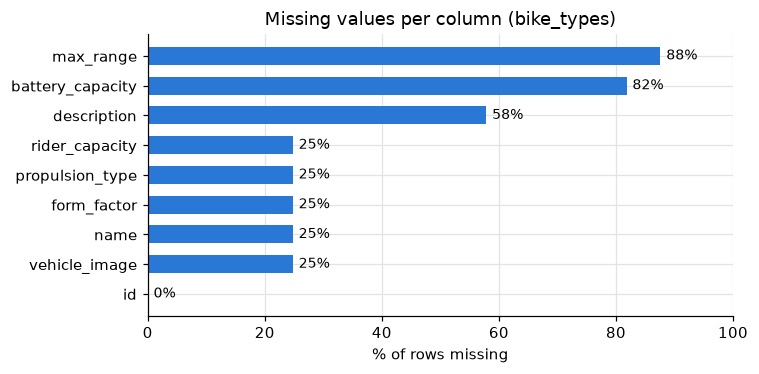

In [25]:
missing = bike_types.isna().mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for y, v in enumerate(missing.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column (bike_types)")
plt.tight_layout()

In [26]:
attr_cols = bike_types.columns.drop("id")
empty = bike_types[attr_cols].isna().all(axis=1)
print(f"{empty.sum()} rows have only an id and nothing else")

30 rows have only an id and nothing else


A lot of bike types don't have a "battery_capacity" and a "max_range". We can assume that some cities don't have electric bikes, so it's normal to not have these two columns filled.
We have also 30 rows with only an id and nothing else. 5 variables are missing for 25% of the bike types, we can think that they come from the same export.

In [27]:
bikes_per_type = bikes["bike_type_id"].value_counts()
bike_types["n_bikes"] = bike_types["id"].map(bikes_per_type).fillna(0).astype(int)

print("bike types never used by any bike:", (bike_types["n_bikes"] == 0).sum())
print("bikes whose type is missing from bike_types:", (~bikes["bike_type_id"].isin(bike_types["id"])).sum())
print(f"bikes pointing to an empty type: {bike_types.loc[empty, 'n_bikes'].sum()} / {len(bikes)}")
bike_types.loc[empty, ["id", "n_bikes"]].sort_values("n_bikes", ascending=False).head(10)

bike types never used by any bike: 0
bikes whose type is missing from bike_types: 0
bikes pointing to an empty type: 1050 / 88436


,id,n_bikes
0,152,778
4,37,120
14,60,24
3,34,19
2,35,19
20,219,14
22,205,10
9,53,7
7,92,7
6,214,7


##### 1.2 Keys and the image URL

In [28]:
print("id unique:", bike_types["id"].is_unique)

# URL format: https://static.nextbike.net/app/biketypes/type/<system>/<id>/h500.png
url_parts = bike_types["vehicle_image"].str.split("/")
system_code = url_parts.str[-3]
url_id = pd.to_numeric(url_parts.str[-2])

print("URL id == id:", (url_id == bike_types["id"]).sum(), "/", bike_types["vehicle_image"].notna().sum())
print("distinct system codes in URLs:", system_code.nunique())
system_code.value_counts().head(10)

id unique: True
URL id == id: 91 / 91
distinct system codes in URLs: 50


vehicle_image
pr    6
bf    5
dl    4
pd    3
bp    3
ur    3
pv    3
gt    3
gp    2
lv    2
Name: count, dtype: int64

We can see that all ids are unique, so it's great. 
Inside the url, there is a system code is the type of bike that belongs to a city or a network. The same bikes can appear in different cities but the system is different.

#### 2. Descriptive statistics

In [29]:
for col in ["form_factor", "propulsion_type", "rider_capacity"]:
    print(bike_types[col].value_counts(dropna=False), "\n")

form_factor
bicycle          71
NaN              30
cargo_bicycle    19
other             1
Name: count, dtype: int64 

propulsion_type
human              64
NaN                30
electric_assist    27
Name: count, dtype: int64 

rider_capacity
1.0    70
NaN    30
2.0    21
Name: count, dtype: int64 



In [30]:
pd.crosstab(bike_types["form_factor"], [bike_types["propulsion_type"], bike_types["rider_capacity"]], dropna=False)

propulsion_type electric_assist         human         nan        
rider_capacity              1.0 2.0 NaN   1.0 2.0 NaN 1.0 2.0 NaN
form_factor                                                      
bicycle                      15   0   0    35  21   0   0   0   0
cargo_bicycle                12   0   0     7   0   0   0   0   0
other                         0   0   0     1   0   0   0   0   0
NaN                           0   0   0     0   0   0   0   0  30

We can observe that there are 64 non-electric bike types and 27 electric bike types. 70 carry just one person and 21 can carry two people. 
30 are NaN but they come from the 30 lines that are just filled with an id.

##### 2.1 Counting types vs counting bikes


,% of types,% of bikes
other / human,0.8,0.0
cargo_bicycle / electric_assist,9.9,0.1
cargo_bicycle / human,5.8,0.2
unknown / unknown,24.8,1.2
bicycle / electric_assist,12.4,6.5
bicycle / human,46.3,92.0


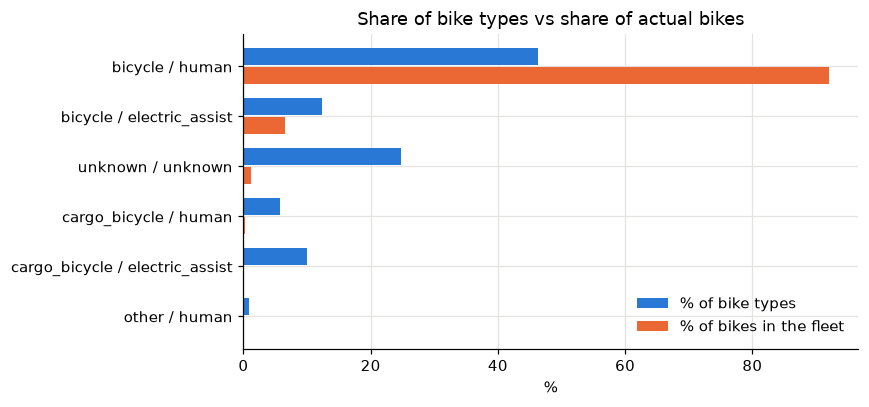

In [31]:
group = (
    bike_types["form_factor"].fillna("unknown") + " / " + bike_types["propulsion_type"].fillna("unknown")
)
share = pd.DataFrame({
    "% of types": group.value_counts(normalize=True) * 100,
    "% of bikes": bike_types.groupby(group)["n_bikes"].sum() / bike_types["n_bikes"].sum() * 100,
}).sort_values("% of bikes")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(share))
h = 0.38
ax.barh(y + h / 2, share["% of types"], height=h - 0.04, color=BLUE, label="% of bike types")
ax.barh(y - h / 2, share["% of bikes"], height=h - 0.04, color=ORANGE, label="% of bikes in the fleet")
ax.set_yticks(y, share.index)
ax.set_xlabel("%")
ax.set_title("Share of bike types vs share of actual bikes")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
share.round(1)

In this section we compare the two datasets "bike_types.csv" and "bikes.csv". 
We compare the number of bikes for each type and not just the types. For instance we saw before that there were 64 non-electric bikes vs 27 electric bikes. Electric bikes represent 30% of the bike types (excluding the NaN). But if we observe the number of bikes for each type, electric bikes represent just 7%, the vast majority are non-electric bikes. 
The same thing applies for cargo bikes. They represent 21% of the bike types (excluding the NaN) but just 0.3% of the bikes available.

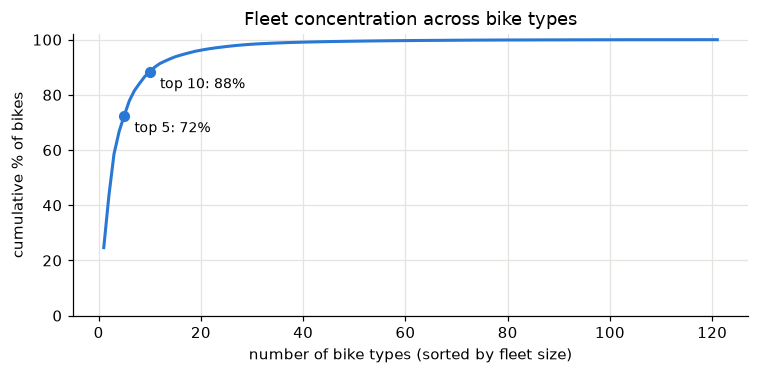

In [32]:
sorted_bikes = bike_types["n_bikes"].sort_values(ascending=False).to_numpy()
cum_share = sorted_bikes.cumsum() / sorted_bikes.sum() * 100

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(cum_share) + 1), cum_share, color=BLUE, lw=2)
for k in (5, 10):
    ax.scatter(k, cum_share[k - 1], color=BLUE, s=40, zorder=3)
    ax.text(k + 2, cum_share[k - 1] - 6, f"top {k}: {cum_share[k - 1]:.0f}%", fontsize=9)
ax.set_xlabel("number of bike types (sorted by fleet size)")
ax.set_ylabel("cumulative % of bikes")
ax.set_ylim(0, 102)
ax.set_title("Fleet concentration across bike types")
plt.tight_layout()

With this feature and graph we can observe that just 5 types cover 72% of the bikes and 10 types cover 88%. The rest (more than 100 other types) cover less than 12% of the bikes.

In [33]:
bike_types.sort_values("n_bikes", ascending=False)[
    ["id", "name", "form_factor", "propulsion_type", "rider_capacity", "battery_capacity", "n_bikes"]
].head(10)

,id,name,form_factor,propulsion_type,rider_capacity,battery_capacity,n_bikes
119,150,with Framelock,bicycle,human,1.0,NaN,21791
118,196,with Framelock,bicycle,human,1.0,NaN,16604
111,71,SMARTbike 2.0 (A) 2018,bicycle,human,1.0,NaN,13375
112,15,with Fork lock,bicycle,human,1.0,NaN,7227
108,4,CLASSICbike,bicycle,human,1.0,NaN,5108
24,174,Comfort,bicycle,human,1.0,NaN,4756
90,192,with Framelock,bicycle,human,1.0,NaN,3258
107,204,E-Bike,bicycle,electric_assist,1.0,500.0,2309
120,198,3-rychlostní SMARTbike 2.0.,bicycle,human,1.0,NaN,2165
113,14,Comfort 1 1/8 Zoll,bicycle,human,1.0,NaN,1607


If we print the types with the most bikes we observe that some models are represented in several cities like the "framelock", the "comfort" or "SMARTbike 2.0". Also the "Framelock" is the most represented bike in the dataset. 

##### 2.2 Electric bikes: range and battery

In [34]:
electric = bike_types[bike_types["propulsion_type"] == "electric_assist"]
print("electric types:", len(electric))
print("max_range values:", electric["max_range"].value_counts(dropna=False).to_dict())
print("battery_capacity values:", electric["battery_capacity"].value_counts(dropna=False).to_dict())
print("human types with a battery or range:", bike_types.loc[bike_types["propulsion_type"] == "human", ["max_range", "battery_capacity"]].notna().any(axis=1).sum())

electric types: 27
max_range values: {60000.0: 15, nan: 12}
battery_capacity values: {500.0: 13, 600.0: 6, nan: 5, 630.0: 2, 690.0: 1}
human types with a battery or range: 0


Regarding the range of the electric bikes, there is just one value "60000.0" so 60 km. But the value of the battery capacity differs from one bike to another. We can assume that "60000.0" is a default value and doesn't represent something true. 
Regarding the battery capacity, we notice 4 different batteries.

##### 2.3 Names and descriptions

In [35]:
bike_types["name"].value_counts().head(15)

name
Rower z fotelikiem dziecięcym    10
Tandem                            7
e-Cargobike                       7
e-CARGObike                       5
Rowerek dziecięcy 6+              5
E-Bike                            4
with Framelock                    4
Cargo                             4
3-rychlostní SMARTbike 2.0.       3
e-SMARTbike 2.0.                  3
7-rychlostní SMARTbike            2
CARGObike                         2
8-rychlostní SMARTbike            2
Comfort                           1
Elektricno kolo                   1
Name: count, dtype: int64

If we count how many types have the same name, we observe that several models of bikes are present in multiple cities or networks. For instance the model "Rower z fotelikiem dziecięcym" is present in 10 cities or networks. The name is the same, so it's probably cities in the same country or link to the same company that own the bikes.

In [36]:
print("types with a description:", bike_types["description"].notna().sum())
print(bike_types.loc[bike_types["description"].notna(), "description"].iloc[0])

types with a description: 51
- MountainBike Rahmen ALU
- Shimano 27-Gang-Schaltung
- RST-Federgabel
- Gepäckträger 


##### 2.4 Cross-check with trips: does `propulsion_type` match the battery data?


In [37]:
trips = pd.read_csv(ROOT / "trips_small.csv", usecols=["bike_id", "battery_start"])
trips = trips.merge(bikes[["id", "bike_type_id"]], left_on="bike_id", right_on="id", how="left")
trips = trips.merge(
    bike_types[["id", "propulsion_type"]].rename(columns={"id": "bike_type_id"}),
    on="bike_type_id", how="left",
)
trips["has_battery"] = trips["battery_start"].notna()

pd.crosstab(trips["propulsion_type"].fillna("unknown (empty type)"), trips["has_battery"], margins=True)

has_battery,False,True,All
propulsion_type,,,
electric_assist,11861,168230,180091
human,978637,302,978939
unknown (empty type),2346,0,2346
All,992844,168532,1161376


Electric bikes have a battery level in 93% of their trips. Human bikes almost never do (302 out of 979,000 trips, about 0.03%, probably sensor errors).
The variable "propulsion_type" can be trusted. The 2,346 trips made with bikes of an empty type never have a battery level, so these bikes are very likely normal bikes. 

In [38]:
battery_evidence = trips.groupby("bike_type_id").agg(
    n_trips=("has_battery", "size"),
    battery_share=("has_battery", "mean"),
)
battery_evidence.loc[battery_evidence.index.isin(bike_types.loc[empty, "id"])].sort_values("n_trips", ascending=False)

,n_trips,battery_share
bike_type_id,,
152,1468,0.0
60,179,0.0
205,168,0.0
219,144,0.0
218,97,0.0
72,59,0.0
53,56,0.0
149,44,0.0
17,32,0.0


30 bike types have no information. We don't know if they are electric or normal bikes. We look at their trips. Electric bikes report a battery level, normal bikes don't. If a type's trips never show a battery, it's probably a normal bike. We added a threshold to make sure that a bike with just 1 trip doesn't count. The threshold is 30.

#### 3. Cleaning

1. We keep the 30 empty rows. They have no information, but 1,050 real bikes use them. If we delete them, those bikes lose their type when we join the tables.
2. We remove 3 columns : "max_range", "vehicle_image" and "description". 
"max_range" is always 60km so it's not information.
"vehicle_image" is just a URL, we keep the system code and drop the rest that is not bringing information.
"description" is free text in many languages, and missing 58% of the time. We just keep a column that says yes/no description
3. We fill the empty types with information from the experiments with the trips. 
4. We treat missing battery values in 2 different ways.
human bikes : no battery we put 0
electric bikes : battery exist but the value is NaN = we put the median (500 Wh)
5. We replace missing text values with "unknown". "form_factor", "propulsion_type" and "name" get "unknown" instead of NaN. This way, "unknown" becomes a real category we can count and plot.
6. We add new useful columns :
- n_bikes: how many real bikes have this type
- system_code: the bike-sharing system, taken from the URL
- is_electric, is_cargo: simple yes/no columns, easy to use later
- name_group: groups the many names in different languages into a few categories (standard, child seat, tandem, cargo, kids bike, handbike, unknown)
- is_empty_type: marks the 30 rows that were empty


In [39]:
clean = bike_types.copy()

clean["system_code"] = system_code
clean["has_description"] = clean["description"].notna()
clean = clean.drop(columns=["vehicle_image", "description", "max_range"])

clean["is_empty_type"] = empty
MIN_TRIPS = 30
battery_share = clean["id"].map(battery_evidence["battery_share"])
n_trips = clean["id"].map(battery_evidence["n_trips"])
human_by_trips = empty & (battery_share == 0) & (n_trips >= MIN_TRIPS)
clean.loc[human_by_trips, "propulsion_type"] = "human"
clean["propulsion_imputed"] = human_by_trips

clean["form_factor"] = clean["form_factor"].fillna("unknown")
clean["propulsion_type"] = clean["propulsion_type"].fillna("unknown")
clean["name"] = clean["name"].fillna("Unknown")

is_electric = clean["propulsion_type"] == "electric_assist"
battery_median = clean.loc[is_electric, "battery_capacity"].median()
clean["battery_imputed"] = is_electric & clean["battery_capacity"].isna()
clean.loc[clean["battery_imputed"], "battery_capacity"] = battery_median
clean.loc[clean["propulsion_type"] == "human", "battery_capacity"] = 0

clean["is_electric"] = is_electric
clean["is_cargo"] = clean["form_factor"] == "cargo_bicycle"

In [40]:
def name_group(name):
    name = name.lower()
    if name == "unknown":
        return "unknown"
    if "fotelik" in name or "child" in name or "sjedalica" in name:
        return "child_seat"
    if "rowerek" in name or "kinderfahrrad" in name:
        return "kids_bike"
    if "tandem" in name:
        return "tandem"
    if "cargo" in name or "trójkołowy" in name:
        return "cargo"
    if "handbike" in name:
        return "handbike"
    return "standard"

clean["name_group"] = clean["name"].apply(name_group)

clean["name_group"].value_counts()

name_group
standard      42
unknown       31
cargo         20
child_seat    13
tandem         7
kids_bike      7
handbike       1
Name: count, dtype: int64

In [41]:
for col in ["form_factor", "propulsion_type", "name_group", "system_code"]:
    clean[col] = clean[col].astype("category")
clean.isna().sum()

id                     0
name                   0
form_factor            0
rider_capacity        30
propulsion_type        0
battery_capacity      21
n_bikes                0
system_code           30
has_description        0
is_empty_type          0
propulsion_imputed     0
battery_imputed        0
is_electric            0
is_cargo               0
name_group             0
dtype: int64

In [42]:
assert clean["id"].is_unique
assert bikes["bike_type_id"].isin(clean["id"]).all()
assert (clean.loc[clean["is_electric"], "battery_capacity"] > 0).all()

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
clean.to_parquet(CLEAN_DIR / "bike_types.parquet", index=False)
clean.to_csv(CLEAN_DIR / "bike_types.csv", index=False)
clean.head()

,id,name,form_factor,rider_capacity,propulsion_type,battery_capacity,n_bikes,system_code,has_description,is_empty_type,propulsion_imputed,battery_imputed,is_electric,is_cargo,name_group
0,152,Unknown,unknown,NaN,human,0.0,778,NaN,False,True,True,False,False,False,unknown
1,31,Unknown,unknown,NaN,unknown,NaN,2,NaN,False,True,False,False,False,False,unknown
2,35,Unknown,unknown,NaN,unknown,NaN,19,NaN,False,True,False,False,False,False,unknown
3,34,Unknown,unknown,NaN,unknown,NaN,19,NaN,False,True,False,False,False,False,unknown
4,37,Unknown,unknown,NaN,unknown,NaN,120,NaN,False,True,False,False,False,False,unknown


## 1.3 Stations (`stations.csv`)

### Exploration Preprocessing of stations data 

#### Importing dependencises

Overview: This notebook covers the data cleaning, validation, and spatial preprocessing steps for the station dataset.

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx
from matplotlib.colors import LinearSegmentedColormap

plt.rcdefaults()  # start from matplotlib defaults, as in the original stations notebook


In [44]:
# Set global seaborn style - clean background without grid
sns.set_style("white", {
    "axes.grid": False,           # Remove grid lines
    "axes.spines.left": True,     # Keep left spine
    "axes.spines.bottom": True,   # Keep bottom spine
    "axes.spines.top": False,     # Remove top spine
    "axes.spines.right": False,   # Remove right spine
    "axes.linewidth": 1.2,        # Slightly thicker axis lines
})

# Set inclusive and colorblind-friendly palette
# Using 'colorblind' palette which is accessible to colorblind users
sns.set_palette("colorblind")

#### Data Exploration

In [45]:
df_stations=pd.read_csv(ROOT / "stations.csv")
dim=df_stations.shape
print(dim)
print((df_stations).info())


(2932, 11)
<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 326.9 KB
None


In [46]:
df_stations.describe()

,id,city_id,app_number,place_type,bike_racks,special_racks,rack_locks,lon,lat
count,2.932000e+03,2932.000000,2932.000000,2932.000000,2932.000000,2932.000000,0.0,2932.000000,2932.000000
mean,4.116020e+07,480.171555,29985.929400,3.760914,6.033424,-0.011255,NaN,13.172182,49.272772
std,4.773764e+07,242.781001,61868.290176,6.894175,6.495116,0.486820,NaN,6.914270,4.342509
min,9.400000e+01,7.000000,0.000000,0.000000,0.000000,-10.000000,NaN,-15.758277,7.745476
25%,3.604443e+06,251.000000,4918.750000,0.000000,0.000000,0.000000,NaN,8.156823,47.955417
50%,2.531790e+07,527.000000,7907.500000,0.000000,6.000000,0.000000,NaN,14.314387,50.290478
75%,5.661078e+07,702.000000,48798.250000,0.000000,10.000000,0.000000,NaN,17.488668,51.602447
max,2.192360e+08,858.000000,999574.000000,27.000000,70.000000,12.000000,NaN,33.413632,57.005195


##### missing values

In [47]:
def check_miss(df):  
    dim=df.shape
    n_miss = df.shape[0]-df.count()
    p_miss = (n_miss/dim[0])*100
    s_type = df.dtypes 
    n_values = df.nunique(dropna=True) 
    miss_df=pd.DataFrame()
    miss_df["n_missing"]=n_miss
    miss_df["p_missing"]=p_miss
    miss_df["feat_type"]=s_type
    miss_df["nu_unique"]=n_values
    return miss_df


In [48]:
display(check_miss(df_stations))

,n_missing,p_missing,feat_type,nu_unique
id,0,0.000000,int64,2932
city_id,0,0.000000,int64,185
name,0,0.000000,str,2855
app_number,0,0.000000,int64,2914
terminal_type,587,20.020464,str,10
place_type,0,0.000000,int64,16
bike_racks,0,0.000000,int64,33
special_racks,0,0.000000,int64,11
rack_locks,2932,100.000000,float64,0
lon,0,0.000000,float64,2912


we can see clearly that all the value of `rack_locks` column are missing making removing it the best choice for our cleaning process
`name`,`app_number` are dropped likewise, the columns were dropped as they provide no analytical value and are not used as a join key with any other dataset.

In [49]:
cleaned_df=df_stations.drop(["rack_locks","name","app_number"],axis=1)
display(check_miss(cleaned_df))


,n_missing,p_missing,feat_type,nu_unique
id,0,0.000000,int64,2932
city_id,0,0.000000,int64,185
terminal_type,587,20.020464,str,10
place_type,0,0.000000,int64,16
bike_racks,0,0.000000,int64,33
special_racks,0,0.000000,int64,11
lon,0,0.000000,float64,2912
lat,0,0.000000,float64,2911


##### Dealing with terminal type feature 

terminal_type feature  has more than 20% missing values with 10 unique values missing two types, (compared to the 12 expected types outlined in the dataset description in the challenge document).
for that missing entries are explicitly imputed with the string "Missing" to retain structural records without biasing distribution metrics.


<Axes: xlabel='terminal_type'>

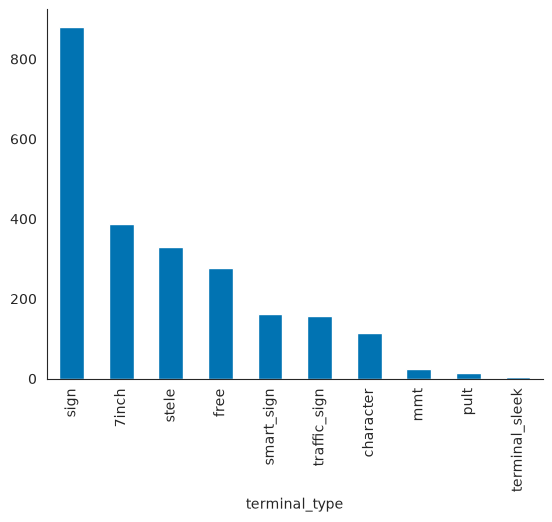

In [50]:
((cleaned_df.terminal_type.value_counts())).plot(kind="bar")


In [51]:
cleaned_df.terminal_type=cleaned_df.terminal_type.fillna("Missing")
cleaned_df

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
0,142186362,135,Missing,12,0,0,7.821669,51.677449
1,940986,176,Missing,0,6,0,13.868973,54.090538
2,93646685,176,stele,0,15,0,13.918970,54.073088
3,111365509,243,smart_sign,0,20,0,-3.936120,56.119272
4,405835,302,sign,0,6,0,14.481456,35.906836
...,...,...,...,...,...,...,...,...
2927,294352,128,Missing,0,11,0,24.156725,57.005195
2928,20729102,527,7inch,0,10,0,21.249210,52.121370
2929,9575430,530,Missing,0,9,0,6.440451,51.163646
2930,18599421,675,7inch,14,4,0,-13.864890,28.384953


##### duplicated values


In [52]:
print("the number of duplicated values are :",cleaned_df.duplicated().sum())
print("the number of duplicated values are :",cleaned_df.duplicated().sum())


the number of duplicated values are : 0
the number of duplicated values are : 0


##### Data Validation

in this section we will to check the validity of the data in case of odd values

In [53]:
print("number of false values in bike_racks", (cleaned_df.bike_racks<0).sum() ," \n values", cleaned_df.iloc[cleaned_df.bike_racks<0])
print("number of false values in special_racks", (cleaned_df.special_racks<0).sum()," \n values \n ", cleaned_df.iloc[cleaned_df.special_racks<0].to_string())
neg_points= cleaned_df.iloc[cleaned_df.special_racks<0]
neg_ids=neg_points.id


number of false values in bike_racks 0  
 values Empty DataFrame
Columns: [id, city_id, terminal_type, place_type, bike_racks, special_racks, lon, lat]
Index: []
number of false values in special_racks 32  
 values 
               id  city_id terminal_type  place_type  bike_racks  special_racks        lon        lat
455    19772006      643         7inch          14           6             -2  15.382405  46.380096
974    21257660      220         7inch          14           6             -2  16.043296  45.818237
982    60833931      220         7inch          14          10             -4  16.012638  45.796928
1202   16852569      327         7inch          14           2             -1  15.235639  44.104679
1311   40538270      415         7inch          14          10             -4  16.048545  45.718726
1326    3561904      429         7inch          14          20            -10  13.595022  45.214403
1329    3562085      429         7inch          14          10             -5  13.

we can see that all negative value have  the same place type and same terminal type

Negative values observed in special_racks share identical `place_type` and `terminal_type` attributes, suggesting a systematic data recording error.

To cross-examine these invalid entries, we evaluate status snapshots from `stations_status.csv` to compare observed historical maximum capacities against reported values.

In [54]:
stat_s=pd.read_csv(ROOT / "stations_status.csv")

<Axes: xlabel='id'>

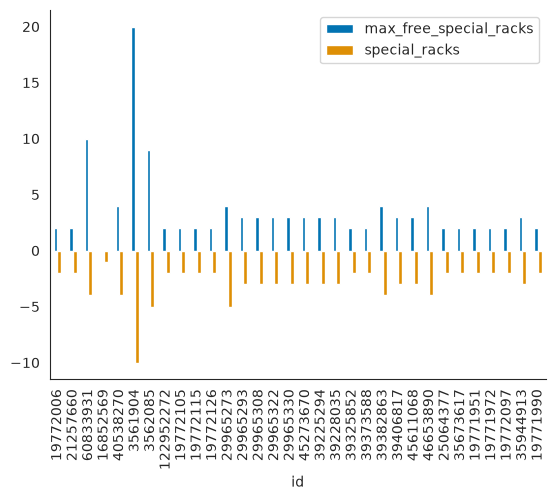

In [55]:

stat_s=stat_s.loc[stat_s.maintenance == False]
grouped_by_id=stat_s[["station_id","free_special_racks"]].groupby("station_id",as_index=False).max()
grouped_by_id.columns=["id","max_free_special_racks"]

join= grouped_by_id.merge(cleaned_df[["id","special_racks"]],on="id")
join.index=join.id
join[["max_free_special_racks","special_racks"]].loc[neg_ids].plot.bar(rot=90)

we can see that some values are not the same so the best choice is to remove the row with negativve values and keep them in seprated , givn the possibility that time time of count in stations.csv may differe than the max of stations.status.csv we choose not to consider in our anlaysis but impute them for our machine learning algorithms

In [56]:
removed_values=cleaned_df.iloc[cleaned_df.special_racks<0]
cleaned_df=cleaned_df.iloc[~cleaned_df.special_racks<0]

/tmp/ipykernel_639613/1929283515.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


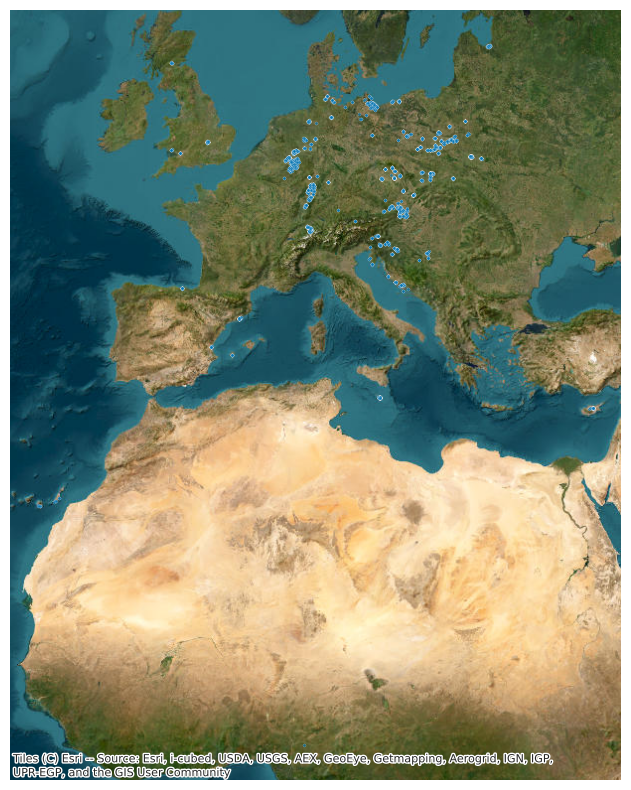

In [57]:
gdf = gpd.GeoDataFrame(
    cleaned_df,
    geometry=gpd.points_from_xy(cleaned_df.lon, cleaned_df.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=5,           
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

We can see some geospatial outliers Coordinates are evaluated against geographic bounding constraints for Europe ($\text{Latitude} \in [34^\circ, 71^\circ]$, $\text{Longitude} \in [-25^\circ, 60^\circ]$). points Outside these regions is either european small isolated territories  or utterly  falling outside european soil.

In [58]:
filter_lat=(~cleaned_df.lat.between(34,71))
filter_lon=(~cleaned_df.lon.between(-25,60))
filter_out=filter_lat | filter_lon
points_outside=cleaned_df.loc[filter_out]
points_outside

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
1658,18598248,638,7inch,14,4,0,-15.758277,27.824618
1659,18598681,638,7inch,14,4,0,-15.579987,27.762925
1660,18599537,638,7inch,14,6,0,-15.605667,27.742972
1661,18599596,638,7inch,14,6,0,-15.600083,27.740583
1662,18599750,638,7inch,14,4,0,-15.572444,27.756972
1663,18599772,638,7inch,14,4,0,-15.709750,27.781222
1664,18599901,638,7inch,14,6,0,-15.649778,27.782611
1665,18599488,675,7inch,14,4,0,-13.863219,28.390124
1666,18599628,675,7inch,14,6,0,-14.233111,28.150222
2486,205113328,858,free,0,0,0,7.801357,7.745476


/tmp/ipykernel_639613/2485667503.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


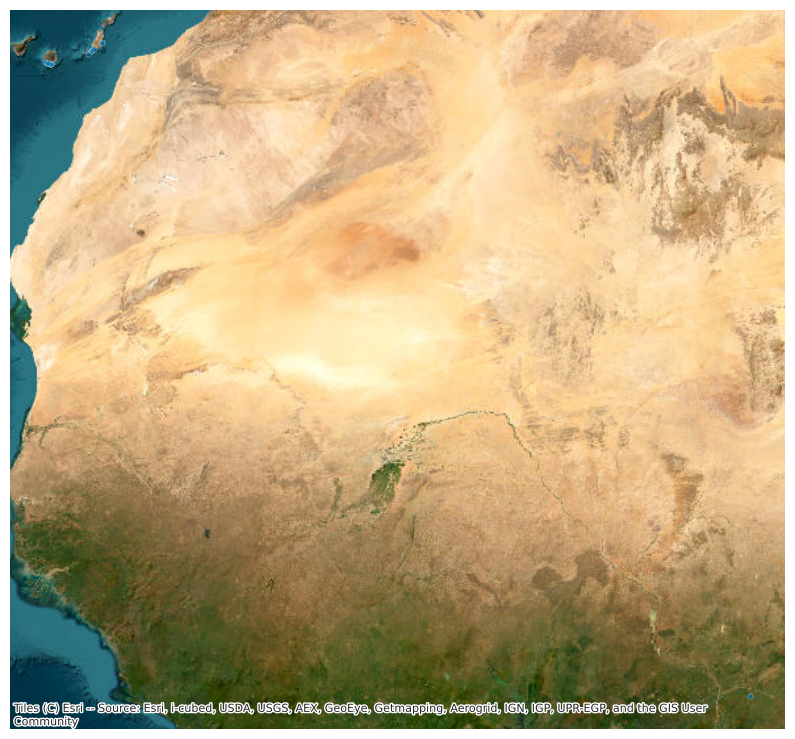

In [59]:
gdf = gpd.GeoDataFrame(
    points_outside,
    geometry=gpd.points_from_xy(points_outside.lon, points_outside.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=15,             
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

we can see clearly that these stations except the ones in canary islands are not in europe. 

In [60]:
canary_island_cityids=(638,675)
filter_cis=~((cleaned_df.city_id == canary_island_cityids[0]) | (cleaned_df.city_id == canary_island_cityids[1]))
new_filter = filter_cis & filter_out
cleaned_df.iloc[new_filter]

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
2486,205113328,858,free,0,0,0,7.801357,7.745476


after checking the station id in bike_types we determined the correct values which  are 
7.803989,52.188201

In [61]:
cleaned_df.loc[new_filter,"lat"] = 52.188201
cleaned_df.loc[new_filter,"lon"] = 7.803989
cleaned_df[new_filter]

,id,city_id,terminal_type,place_type,bike_racks,special_racks,lon,lat
2486,205113328,858,free,0,0,0,7.803989,52.188201


/tmp/ipykernel_639613/2665358396.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


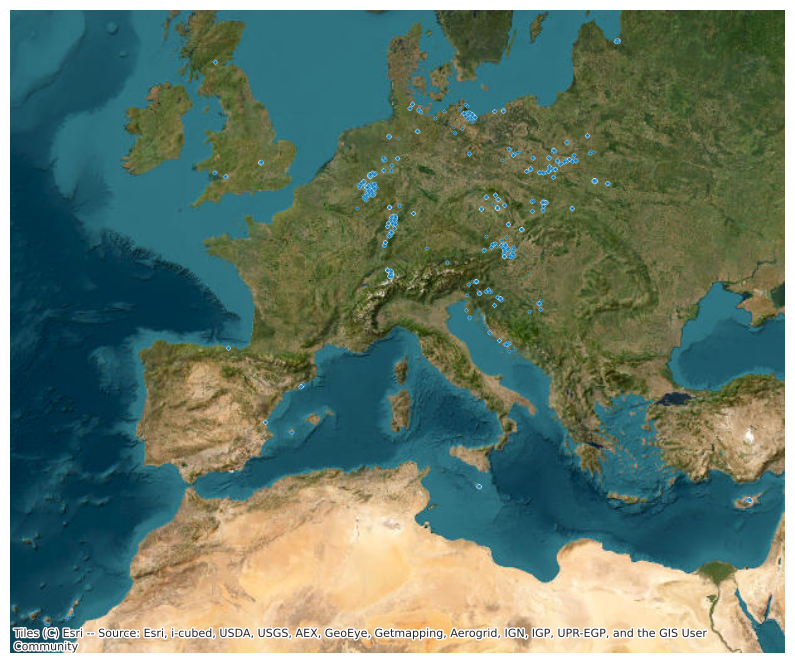

In [62]:
gdf = gpd.GeoDataFrame(
    cleaned_df,
    geometry=gpd.points_from_xy(cleaned_df.lon, cleaned_df.lat),
    crs="EPSG:4326",
)

gdf_wm = gdf.to_crs(epsg=3857)

gdf_wm["x"] = gdf_wm.geometry.x
gdf_wm["y"] = gdf_wm.geometry.y

fig, ax = plt.subplots(figsize=(10, 10))

sns.scatterplot(
    data=gdf_wm,
    x="x",
    y="y",
    s=5,            
    alpha=0.6,
    palette="viridis",
    ax=ax,
)

ax.set_aspect("equal")
cx.add_basemap(ax, source=cx.providers.Esri.WorldImagery)

ax.set_axis_off()
plt.show()

### Statistical analysis

In [63]:
matrix_correlation = cleaned_df.drop(["terminal_type","id","city_id"],axis=1).corr()
matrix_correlation

,place_type,bike_racks,special_racks,lon,lat
place_type,1.000000,-0.182787,0.083849,-0.354395,-0.057479
bike_racks,-0.182787,1.000000,0.012018,0.180057,0.167060
special_racks,0.083849,0.012018,1.000000,-0.007656,-0.006036
lon,-0.354395,0.180057,-0.007656,1.000000,-0.002151
lat,-0.057479,0.167060,-0.006036,-0.002151,1.000000


In [64]:
import folium
from folium.plugins import HeatMap
import pandas as pd

df_clean = cleaned_df.dropna(subset=['lat', 'lon'])

heat_data = df_clean[['lat', 'lon']].values.tolist()

center_lat = df_clean['lat'].mean()
center_lon = df_clean['lon'].mean()

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=11, 
    tiles="OpenStreetMap"
)

HeatMap(
    data=heat_data,
    radius=15,
    blur=10,
    min_opacity=0.4
).add_to(m)

m.save(str(ROOT / "assets" / "carte_robuste.html"))
print(f"Map generated with {len(heat_data)} points. Open the file 'assets/carte_robuste.html' in your browser.")


Map generated with 2900 points. Open the file 'assets/carte_robuste.html' in your browser.


![img](../assets/Screenshot%202026-10-16%20172624.png)

<Axes: xlabel='bike_racks'>

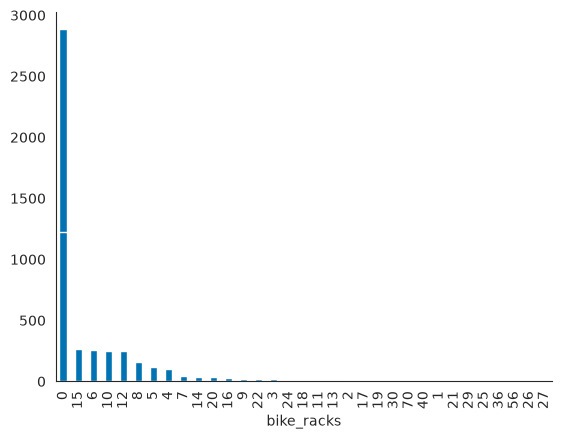

In [65]:
((cleaned_df.special_racks.value_counts())).plot.bar()
((cleaned_df.bike_racks.value_counts())).plot.bar()



<Axes: xlabel='terminal_type'>

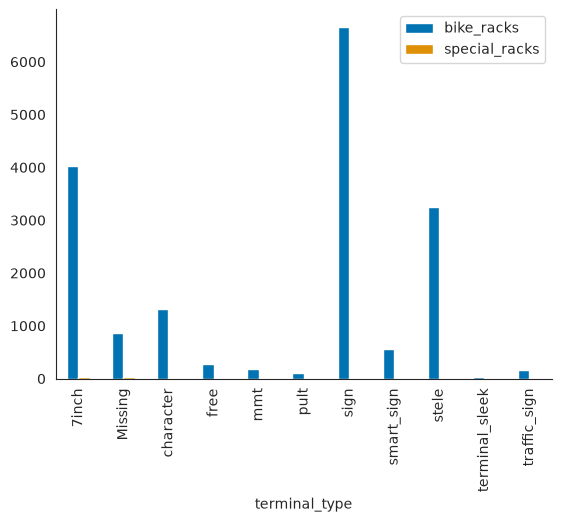

In [66]:

n_rack_pert=cleaned_df[["terminal_type","bike_racks","special_racks"]].groupby("terminal_type").sum()
n_rack_pert.plot.bar(rot=90)

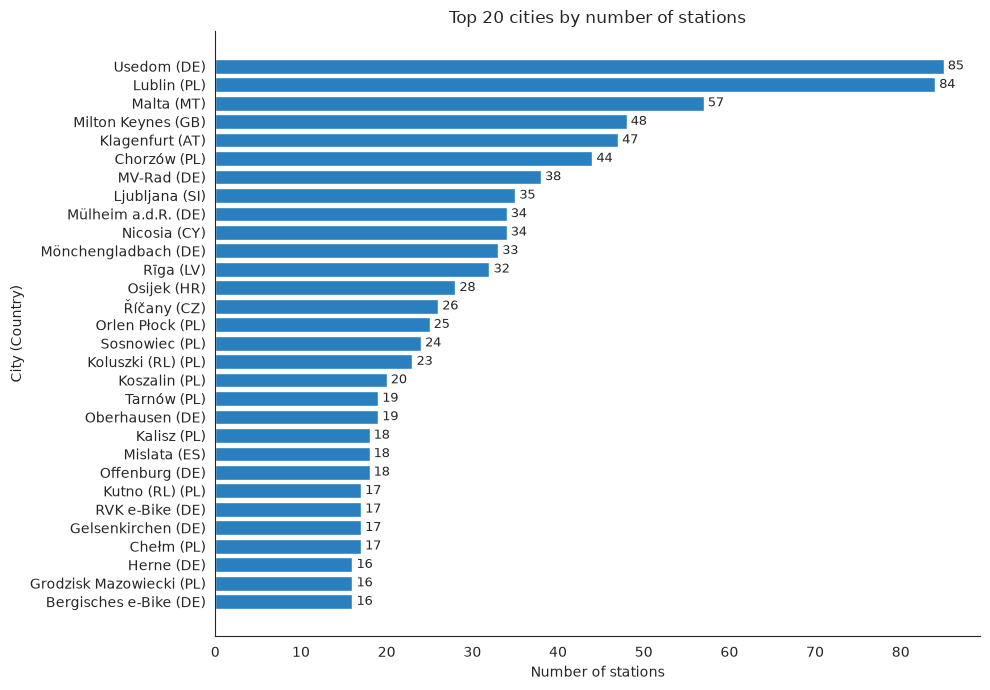

In [67]:
cities = pd.read_csv(ROOT / "cities.csv")   
info = cities.set_index('id')

df_st = cleaned_df[cleaned_df['bike_racks'] > 0]
top = df_st['city_id'].value_counts().head(30)      

labels = [
    f"{info.at[i, 'name']} ({info.at[i, 'country']})" if i in info.index else str(i)
    for i in top.index
]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(labels, top.values, color='#2a7fbf')
ax.invert_yaxis()                                   
ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title('Top 20 cities by number of stations')
ax.set_xlabel('Number of stations')
ax.set_ylabel('City (Country)')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(ROOT / "assets" / "top20_cities.png", dpi=150)
plt.show()

##### Save the cleaned stations

In [68]:
cleaned_df.to_csv(CLEAN_DIR / "cleaned_stations.csv", index=False)
print("Cleaned data saved to data_cleaned/cleaned_stations.csv")
print("Final shape:", cleaned_df.shape)

Cleaned data saved to data_cleaned/cleaned_stations.csv
Final shape: (2900, 8)


## 1.4 Station status (`stations_status.csv`)

In [69]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcdefaults()  # start from matplotlib defaults, as in the original notebook

df = pd.read_csv(ROOT / "stations_status.csv")
print(df.shape)
df.head()

(2925967, 8)


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


#### Problem 1 : missing values

station_id                 0
time                       0
bikes                      0
booked_bikes               0
bikes_available_to_rent    0
free_racks                 0
free_special_racks         0
maintenance                0
dtype: int64
station_id                 0.0
time                       0.0
bikes                      0.0
booked_bikes               0.0
bikes_available_to_rent    0.0
free_racks                 0.0
free_special_racks         0.0
maintenance                0.0
dtype: float64 %


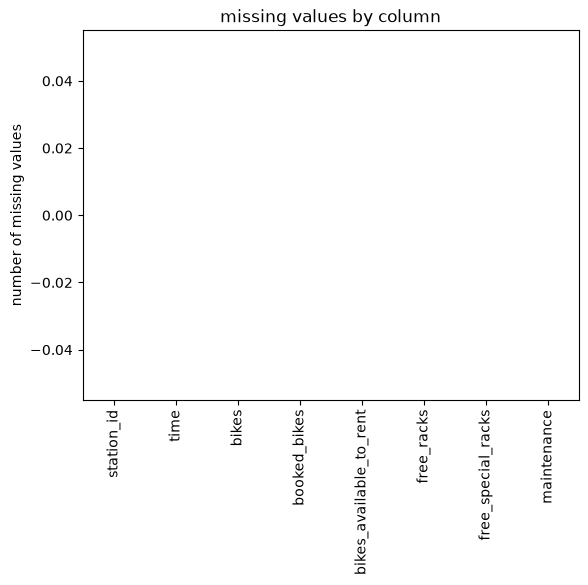

In [70]:

na_count = df.isna().sum()
print(na_count)
print((na_count / len(df) * 100).round(3), "%")

na_count.plot(kind="bar", title="missing values by column")
plt.ylabel("number of missing values")
plt.show()


We can see that there is no missing values in this dataset.



#### Problem 2 : types incorrects

In [71]:

print(df.dtypes)

# conversion of time column to datetime
df["time"] = pd.to_datetime(df["time"], unit="s",  utc=True)
print("Start :", df["time"].min())
print("End   :", df["time"].max())

station_id                   int64
time                       float64
bikes                        int64
booked_bikes                 int64
bikes_available_to_rent      int64
free_racks                   int64
free_special_racks           int64
maintenance                   bool
dtype: object


Start : 2022-08-26 14:48:01+00:00
End   : 2023-07-15 21:59:01+00:00


We can see that there is no issu of time too.

#### Problem 3 : duplicates

In [72]:
nb_dup = df.duplicated().sum()
print("duplicates in station_status :", nb_dup)



duplicates in station_status : 0


There is no duplicates neither.


#### Problem 4 : nagative values and extreme values

negative values by column :
bikes                        0
booked_bikes               160
bikes_available_to_rent      0
free_racks                   0
free_special_racks           0
dtype: int64

Statistics :


            bikes  booked_bikes  bikes_available_to_rent  free_racks  \
count  2925967.00    2925967.00               2925967.00  2925967.00   
mean         6.19          0.05                     6.14        5.03   
std          6.09          0.40                     6.10        5.30   
min          0.00         -4.00                     0.00        0.00   
25%          3.00          0.00                     2.00        0.00   
50%          5.00          0.00                     5.00        4.00   
75%          8.00          0.00                     8.00        8.00   
max        189.00         38.00                   189.00       70.00   

       free_special_racks  
count          2925967.00  
mean                 2.22  
std                  4.34  
min                  0.00  
25%                  0.00  
50%                  0.00  
75%                  3.00  
max                 37.00  


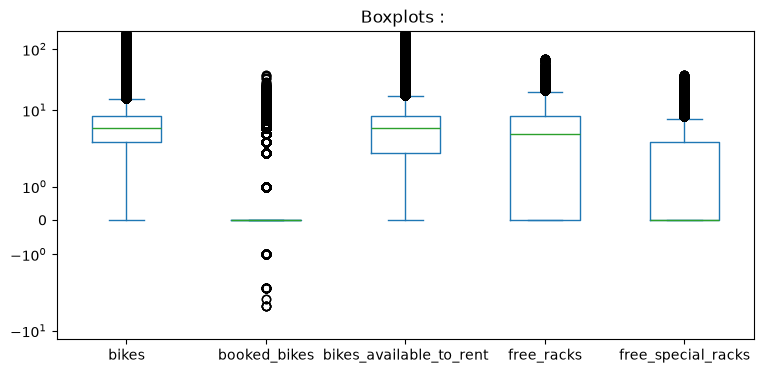

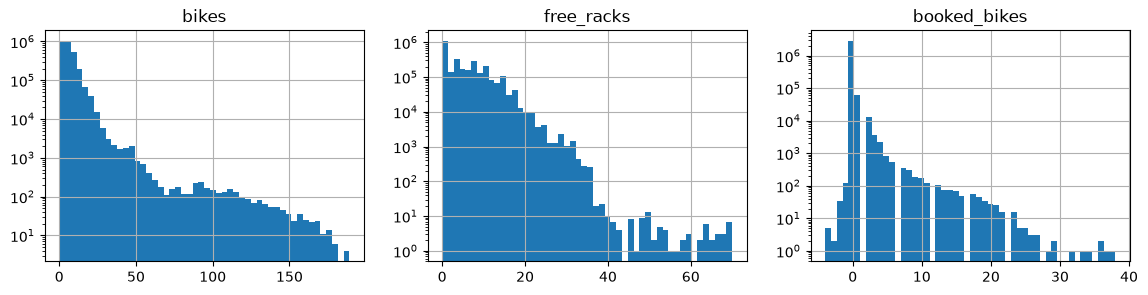

In [73]:
# negative values in columns that should be positive
cols = ["bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks"]

print("negative values by column :")
print((df[cols] < 0).sum())

print("\nStatistics :")
print(df[cols].describe().round(2))

# extreme values in columns 

df[cols].plot(kind="box", figsize=(9, 4), title="Boxplots : ")
plt.yscale("symlog")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
df["bikes"].hist(bins=50, ax=axes[0]);        axes[0].set_title("bikes")
df["free_racks"].hist(bins=50, ax=axes[1]);   axes[1].set_title("free_racks")
df["booked_bikes"].hist(bins=50, ax=axes[2]); axes[2].set_title("booked_bikes")
for a in axes:
    a.set_yscale("log")
plt.show()


Only booked_bikes has impossible values, 160 negatives ( at min −4) out of 2.9M rows, which represent 0.005%, so those rows can be safely removed.
All other columns are non-negative but heavily right-skewed (up to 189 bikes), so these extremes are likely large hubs and should be kept, not removed as outliers.


#### Problem 5 : logical inconsistencies 

In [74]:
#a) more bikes available than bikes 
print("\n\na) Problem a : more bikes available than bikes")
pb_a = df["bikes_available_to_rent"] > df["bikes"] 
df_pb_a = df[ df["bikes_available_to_rent"] > df["bikes"] ]
print("lines with more bikes available than bikes :", len(df_pb_a), "so", round(len(df_pb_a)/len(df)*100, 2), "%")

# Is it the same lines as negative booked_bikes?
neg = df["booked_bikes"] < 0
print((neg & pb_a).sum(), "shared lines out of 160")

# b) available = bikes - booked
print("\n\nb) Problem b : available = bikes - booked")  
pb_b = df["bikes_available_to_rent"] != (df["bikes"] - df["booked_bikes"])
df_pb_b = df[pb_b]
print("lines with available != bikes - booked :", len(df_pb_b), "so", round(len(df_pb_b)/len(df)*100, 2), "%")

ecart = df.loc[pb_b, "bikes_available_to_rent"] - (df.loc[pb_b, "bikes"] - df.loc[pb_b, "booked_bikes"])
print(ecart.value_counts().head(10))

print((neg & pb_b).sum(), "shared lines out of 160")


# c) maintenance but show available bikes
print("\n\nc) Problem c : maintenance but show available bikes")
pb_c = (df["maintenance"] == True) & (df["bikes_available_to_rent"] > 0)


maint = df[df["maintenance"] == True]
print("rows under maintenance :", len(maint), "so", round(len(maint)/len(df)*100, 2), "%")
print("part of bikes_available_to_rent in those one :", round((maint["bikes_available_to_rent"] > 0).mean()*100, 1), "%")

par_station = maint.groupby("station_id").size()
print(par_station.size, "stations affected")

# change in maintenance status ?
df["maint_change"] = df.groupby("station_id")["maintenance"].diff().abs()
print(df["maint_change"].sum(), "change in maintenance status.")




a) Problem a : more bikes available than bikes
lines with more bikes available than bikes : 160 so 0.01 %
160 shared lines out of 160


b) Problem b : available = bikes - booked
lines with available != bikes - booked : 2336 so 0.08 %
1    1869
2     305
3      79
4      60
5      12
6       8
7       2
8       1
Name: count, dtype: int64
0 shared lines out of 160


c) Problem c : maintenance but show available bikes
rows under maintenance : 130542 so 4.46 %
part of bikes_available_to_rent in those one : 95.8 %
86 stations affected


10 change in maintenance status.


160 rows have negative booked_bikes (also causing available > bikes), which will be removed. Another 2,336 rows (0.08%) break available = bikes − booked due to small update lags, and will be kept.

The maintenance flag covers 4.46% of rows across 86 stations, but 95.8% of those still show available bikes and the flag almost never changes. It is therefore not a reliable “offline” indicator, so no rows will be dropped; it will be kept as a feature pending a check on whether those stations are frozen.

#### Problem 6 : issus in time

In [75]:
print(df.columns.tolist())

['station_id', 'time', 'bikes', 'booked_bikes', 'bikes_available_to_rent', 'free_racks', 'free_special_racks', 'maintenance', 'maint_change']


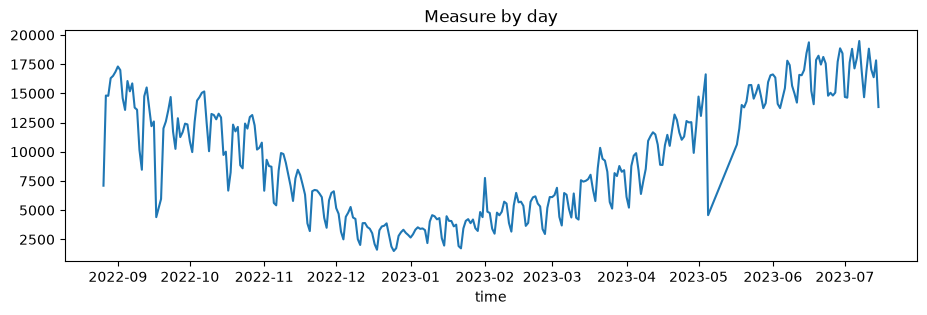

0 rows with missing timezone


['station_id', 'time', 'bikes', 'booked_bikes', 'bikes_available_to_rent', 'free_racks', 'free_special_racks', 'maintenance', 'maint_change', 'ecart_s', 'timezone', 'local_time', 'hour']
                       time       timezone          local_time  hour
0 2022-08-29 13:12:01+00:00  Europe/Berlin 2022-08-29 15:12:01    15
1 2022-08-29 13:13:01+00:00  Europe/Berlin 2022-08-29 15:13:01    15
2 2022-08-30 13:30:01+00:00  Europe/Berlin 2022-08-30 15:30:01    15
3 2022-08-31 17:57:01+00:00  Europe/Berlin 2022-08-31 19:57:01    19
4 2022-08-31 18:05:01+00:00  Europe/Berlin 2022-08-31 20:05:01    20
5 2022-09-04 15:38:01+00:00  Europe/Berlin 2022-09-04 17:38:01    17
6 2022-09-04 15:39:01+00:00  Europe/Berlin 2022-09-04 17:39:01    17
7 2022-09-05 08:32:01+00:00  Europe/Berlin 2022-09-05 10:32:01    10
8 2022-09-05 08:34:01+00:00  Europe/Berlin 2022-09-05 10:34:01    10
9 2022-09-05 08:59:01+00:00  Europe/Berlin 2022-09-05 10:59:01    10


In [76]:
df = df.sort_values(["station_id", "time"])
df["ecart_s"] = df.groupby("station_id")["time"].diff().dt.total_seconds()


# lack of measures per day
by_day = df.groupby(df["time"].dt.date).size()
by_day.plot(figsize=(11, 3), title="Measure by day")
plt.show()

# local time and timezone
stations = pd.read_csv(ROOT / "stations.csv").rename(columns={"id": "station_id"})
cities = pd.read_csv(ROOT / "cities.csv").rename(columns={"id": "city_id"})


df = df.drop(columns=["timezone", "timezone_x", "timezone_y", "local_time", "hour"], errors="ignore")


info = stations.merge(cities[["city_id", "timezone"]], on="city_id", how="left")
info = info.drop_duplicates("station_id")
df = df.merge(info[["station_id", "timezone"]], on="station_id", how="left")
print(df["timezone"].isna().sum(), "rows with missing timezone")


df["local_time"] = pd.NaT
for tz in df["timezone"].dropna().unique():
    masque = df["timezone"] == tz
    df.loc[masque, "local_time"] = df.loc[masque, "time"].dt.tz_convert(tz).dt.tz_localize(None)

df["hour"] = df["local_time"].dt.hour


print(df.columns.tolist())

print(df[["time", "timezone", "local_time", "hour"]].head(10))


All the rows have a clean time according to timezone  

In [77]:

etapes = {"begining": len(df)}
 

 
df = df[(df[cols] >= 0).all(axis=1)]
etapes["after negatives"] = len(df)
 
df = df[df["bikes_available_to_rent"] <= df["bikes"]]
etapes["after avaibility <= bikes"] = len(df)
 
# indicate if the available bikes is not equal to bikes - booked
df["availability_mismatch"] = df["bikes_available_to_rent"] != (df["bikes"] - df["booked_bikes"])

 

df = df.drop(columns=["ecart_s"])
 
print(pd.Series(etapes))
 

begining                     2925967
after negatives              2925807
after avaibility <= bikes    2925807
dtype: int64


In [78]:
df.to_csv(CLEAN_DIR / "stations_status_clean.csv", index=False)
print(df.shape)

(2925807, 13)


## 1.5 Trips (`trips_small.csv`)

ts2 is the cleaned trips_small table. This section explains how to get to it; if you run the whole section you get ts2 at the end.

In [79]:
import pandas as pd

In [80]:
ts = pd.read_csv(ROOT / "trips_small.csv")
ts

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161371,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,96.0,1320.0,3061.891906
1161372,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,97.0,780.0,2178.941052
1161373,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,95.0,900.0,3061.891906
1161374,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,75.0,1020.0,4260.899309


In [81]:
ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681836
station_id_end      10.496514
battery_start       85.488593
battery_end         85.479207
duration             0.000000
distance             0.000000
dtype: float64

There are 4 columns with missing values:
* station_id_start with 7.68%
* station_id_end with 10.49%
* battery_start with 85.48%
* battery_end with 85.47%

The first thing to do is to check whether the missing battery values belong to electric or classic bikes.

In [82]:
ts.drop(columns=["bike_id","city_id","time_start","station_id_start","station_id_end"]).describe()

,lon_start,lat_start,lon_end,lat_end,battery_start,battery_end,duration,distance
count,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,168532.000000,168641.000000,1.161376e+06,1.161376e+06
mean,1.143184e+01,4.941432e+01,1.143162e+01,4.941407e+01,80.988697,76.688996,1.256241e+03,1.791774e+03
std,7.320269e+00,3.707710e+00,7.320443e+00,3.708131e+00,21.384192,22.615122,1.980838e+03,1.495191e+03
min,-1.560567e+01,2.774058e+01,-1.560567e+01,2.774058e+01,0.000000,0.000000,1.210000e+02,5.001365e+01
25%,7.165686e+00,4.717771e+01,7.165686e+00,4.717771e+01,66.000000,61.000000,4.800000e+02,8.851685e+02
50%,1.019364e+01,5.027373e+01,1.018726e+01,5.026997e+01,89.000000,83.000000,7.200000e+02,1.346711e+03
75%,1.745811e+01,5.174006e+01,1.745811e+01,5.173991e+01,100.000000,97.000000,1.200000e+03,2.238540e+03
max,3.398531e+01,5.708158e+01,3.398632e+01,5.708158e+01,100.000000,100.000000,2.874000e+04,1.999946e+04


In [83]:
bt = pd.read_csv(ROOT / "bike_types.csv")

In [84]:
b = pd.read_csv(ROOT / "bikes.csv")

In [85]:
bikes_info = b.merge(bt,how="left",left_on="bike_type_id",right_on="id",suffixes=["_bike","_bike_type"])
bikes_info.isna().mean() * 100
columns = ["computer_id","id_bike_type","vehicle_image","name","description","form_factor","rider_capacity","max_range","battery_capacity"]
bikes_info.drop(columns=columns)

,id_bike,bike_type_id,propulsion_type
0,400481,196,human
1,374044,204,electric_assist
2,373778,204,electric_assist
3,34749,14,human
4,88359,143,electric_assist
...,...,...,...
88431,372994,204,electric_assist
88432,372649,204,electric_assist
88433,372951,204,electric_assist
88434,374346,204,electric_assist


In [86]:
new_ts = ts.merge(bikes_info,how="left",left_on="bike_id",right_on="id_bike")
new_ts["propulsion_type"].value_counts(normalize=True) * 100

propulsion_type
human              84.461921
electric_assist    15.538079
Name: proportion, dtype: float64

* We can see that 84% of values in propulsion_type is human which is almost equal to 85% missing values of battery status
* We need to check if human propulsion values correspond to the missing values of the battery status

In [87]:
import numpy as np

* We convert the "human" values of the propulsion_type column to NaN

In [88]:
new_ts["propulsion_type"] = new_ts["propulsion_type"].map({"human": np.nan, "electric_assist": 1})
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681836
station_id_end      10.496514
battery_start       85.488593
battery_end         85.479207
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202002
name                 0.202002
description         48.552923
form_factor          0.202002
rider_capacity       0.202002
propulsion_type     84.493308
max_range           84.501488
battery_capacity    84.493308
dtype: float64

* How many rows have only one missing value in the pair (battery_start, battery_end)?

In [89]:
one = new_ts[new_ts["battery_start"].notna() ^ new_ts["battery_end"].notna()]
one

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,...,computer_id,id_bike_type,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
201998,42622,676,1.670701e+09,7.219444,51.144028,7.122056,51.058917,30240427.0,32135341.0,NaN,...,7551060064,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202097,42623,676,1.684534e+09,7.197056,50.929000,7.196167,50.914278,49442475.0,32136150.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202098,42623,676,1.684598e+09,7.196167,50.914278,7.182677,50.900797,32136150.0,30240394.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202101,42623,676,1.684673e+09,7.182677,50.900797,7.176250,50.924389,30240394.0,32136249.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
202104,42623,676,1.685276e+09,7.184889,50.959278,7.161333,50.963972,32134268.0,30239595.0,NaN,...,7551059755,143,https://static.nextbike.net/app/biketypes/type/dl/143/h5...,e-SMARTbike 2.0 RFID,- e-eco B frame with Framelock\r\n- aluminum basket with...,bicycle,1.0,1.0,60000.0,500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1158625,826043,679,1.684855e+09,-3.174022,51.438833,-3.179619,51.477280,30005988.0,60694214.0,NaN,...,7551094076,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0
1158645,826044,679,1.663164e+09,-3.206055,51.403857,-3.179534,51.484449,58569525.0,52962132.0,NaN,...,7551092436,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0
1158936,825564,679,1.685463e+09,-3.181851,51.448645,-3.166644,51.446057,53040980.0,6270602.0,NaN,...,7551059021,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0
1159834,825613,679,1.673042e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,NaN,...,7551063848,182,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0


* These battery status values are missing completely at random (MCAR) and it represents 0.01% of table rows, so we decide too delete them

In [90]:
partial = new_ts["battery_start"].isna() ^ new_ts["battery_end"].isna()
new_ts = new_ts[~partial]
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681967
station_id_end      10.496978
battery_start       85.488086
battery_end         85.488086
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202026
name                 0.202026
description         48.558565
form_factor          0.202026
rider_capacity       0.202026
propulsion_type     84.503276
max_range           84.511457
battery_capacity    84.503276
dtype: float64

In [91]:
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681967
station_id_end      10.496978
battery_start       85.488086
battery_end         85.488086
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202026
name                 0.202026
description         48.558565
form_factor          0.202026
rider_capacity       0.202026
propulsion_type     84.503276
max_range           84.511457
battery_capacity    84.503276
dtype: float64

* Now that we are sure that the missing values correspond to human propulsion we will replace missing values by 0 which is coherent
* The 1% more values that are missing in battery status will be considered as MCAR because we don't see any logical reason why they are missing.

In [92]:
new_ts[["battery_start", "battery_end"]] = new_ts[["battery_start", "battery_end"]].fillna(0)
new_ts.isna().mean() * 100

bike_id              0.000000
city_id              0.000000
time_start           0.000000
lon_start            0.000000
lat_start            0.000000
lon_end              0.000000
lat_end              0.000000
station_id_start     7.681967
station_id_end      10.496978
battery_start        0.000000
battery_end          0.000000
duration             0.000000
distance             0.000000
id_bike              0.000000
bike_type_id         0.000000
computer_id          0.000000
id_bike_type         0.000000
vehicle_image        0.202026
name                 0.202026
description         48.558565
form_factor          0.202026
rider_capacity       0.202026
propulsion_type     84.503276
max_range           84.511457
battery_capacity    84.503276
dtype: float64

* For the station_ids that are missing we need to check whether the city allows the bikes to be returned away from stations

In [93]:
c = pd.read_csv(ROOT / "cities.csv")
c

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False
...,...,...,...,...,...,...,...
262,853,Sant Just Desvern,41.3807,2.07496,Europe/Berlin,ES,True
263,856,Sant Boi de Llobregat,41.3458,2.03404,Europe/Berlin,ES,True
264,831,Wolsztyn,52.1120,16.10560,Europe/Warsaw,PL,True
265,143,Tulln,48.3269,16.05690,Europe/Berlin,AT,False


In [94]:
c = c.rename(columns={"id": "city_id", "name": "city_name"})
ts2 = new_ts.merge(c[["city_id", "city_name", "return_to_official_only"]],
                   on="city_id", how="left", validate="m:1")

In [95]:
ts2

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,...,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity,city_name,return_to_official_only
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,0.0,...,https://static.nextbike.net/app/biketypes/type/as/15/h50...,with Fork lock,- Comfort frame typ 21 with FVM\r\n- CFC fork with CSI l...,bicycle,1.0,NaN,NaN,NaN,Wiesbaden,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161234,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True
1161235,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True
1161236,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True
1161237,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,...,https://static.nextbike.net/app/biketypes/type/uc/182/h5...,e-SMARTbike 2.0 with RFID,- e-eco B frame with Framelock\r\n - e-CFC coded fork w...,bicycle,1.0,1.0,60000.0,500.0,Penarth,True


In [96]:
ts2.isna().mean() * 100

bike_id                     0.000000
city_id                     0.000000
time_start                  0.000000
lon_start                   0.000000
lat_start                   0.000000
lon_end                     0.000000
lat_end                     0.000000
station_id_start            7.681967
station_id_end             10.496978
battery_start               0.000000
battery_end                 0.000000
duration                    0.000000
distance                    0.000000
id_bike                     0.000000
bike_type_id                0.000000
computer_id                 0.000000
id_bike_type                0.000000
vehicle_image               0.202026
name                        0.202026
description                48.558565
form_factor                 0.202026
rider_capacity              0.202026
propulsion_type            84.503276
max_range                  84.511457
battery_capacity           84.503276
city_name                   0.000000
return_to_official_only     0.000000
d

In [97]:
ts2["any_station_missing"] = ts2["station_id_start"].isna() | ts2["station_id_end"].isna()

base = ts2["return_to_official_only"].value_counts(normalize=True) * 100
miss = ts2.loc[ts2["any_station_missing"], "return_to_official_only"].value_counts(normalize=True) * 100
print(pd.concat([base, miss], axis=1, keys=["all trips", "station missing"]))

                         all trips  station missing
return_to_official_only                            
True                     82.706402        74.682314
False                    17.293598        25.317686


* 75% of trips with station_id that are missing require return to official station only which reject our hypothesis.
* Station ids are almost MCAR so we will delete them

In [98]:
rows = ts2["station_id_start"].isna() | ts2["station_id_end"].isna()
ts2 = ts2[~rows]
ts2.isna().mean()

bike_id                    0.000000
city_id                    0.000000
time_start                 0.000000
lon_start                  0.000000
lat_start                  0.000000
lon_end                    0.000000
lat_end                    0.000000
station_id_start           0.000000
station_id_end             0.000000
battery_start              0.000000
battery_end                0.000000
duration                   0.000000
distance                   0.000000
id_bike                    0.000000
bike_type_id               0.000000
computer_id                0.000000
id_bike_type               0.000000
vehicle_image              0.002303
name                       0.002303
description                0.452042
form_factor                0.002303
rider_capacity             0.002303
propulsion_type            0.835443
max_range                  0.835486
battery_capacity           0.835443
city_name                  0.000000
return_to_official_only    0.000000
any_station_missing        0

In [99]:

columns = ["bike_id","city_id","time_start","lon_start","lat_start","lon_end","lat_end","station_id_start","station_id_end","battery_start","battery_end","duration","distance"]
ts2 = ts2[columns]
ts2

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,0.0,0.0,1920.0,3301.514764
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,0.0,0.0,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,0.0,0.0,4680.0,897.351993
5,11463,7,1.662315e+09,8.218090,50.080828,8.242628,50.071337,4728239.0,87796472.0,0.0,0.0,600.0,2044.510274
6,11463,7,1.662542e+09,8.242628,50.071337,8.252207,50.071756,87796472.0,87797085.0,0.0,0.0,1020.0,685.223644
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161234,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,96.0,1320.0,3061.891906
1161235,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,97.0,780.0,2178.941052
1161236,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,95.0,900.0,3061.891906
1161237,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,75.0,1020.0,4260.899309


In [100]:
ts2.to_csv(CLEAN_DIR / "trips_small_cleaned.csv", index=False)
print("Cleaned data saved to data_cleaned/trips_small_cleaned.csv")
print("Final shape:", ts2.shape)

Cleaned data saved to data_cleaned/trips_small_cleaned.csv
Final shape: (993542, 13)


## 1.6 Summary of the cleaned datasets

`bikes.csv` needs no cleaning (3 columns, no missing values, every `bike_type_id` exists in `bike_types`),
so it is copied unchanged next to the other cleaned files.

In [101]:
import shutil

shutil.copy(ROOT / "bikes.csv", CLEAN_DIR / "bikes.csv")

files = ["cities_clean.csv", "bike_types.csv", "bikes.csv", "cleaned_stations.csv",
         "stations_status_clean.csv", "trips_small_cleaned.csv"]
summary = pd.DataFrame([
    {"file": f, "rows": len(pd.read_csv(CLEAN_DIR / f, usecols=[0])), "columns": len(pd.read_csv(CLEAN_DIR / f, nrows=0).columns)}
    for f in files
])
summary

,file,rows,columns
0,cities_clean.csv,267,7
1,bike_types.csv,121,15
2,bikes.csv,88436,3
3,cleaned_stations.csv,2900,8
4,stations_status_clean.csv,2925807,13
5,trips_small_cleaned.csv,993542,13


# 2. Unsupervised Tasks: Bike Trip and Stations Profiles

In [102]:
# Start this part with a clean memory and the default plot style, as if it was its own notebook
%reset -f
import matplotlib.pyplot as plt
plt.rcdefaults()

## Part A — Clustering Bike Trips
Goal: find groups of trips that are ridden in the same way, then explain what each group means.

Data: `trips_small_cleaned.csv`, `cities_clean.csv`, `cleaned_stations.csv`, `bikes.csv`, `cleaned_bike_types.csv`.

In [103]:
import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from folium.plugins import HeatMap
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestCentroid
from sklearn.preprocessing import StandardScaler

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]   # one colour per cluster
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0"})

### 1. Load the data and build the trip information

In [104]:
trips = pd.read_csv("../data_cleaned/trips_small_cleaned.csv")
cities = pd.read_csv("../data_cleaned/cities_clean.csv").rename(columns={"id": "city_id", "name": "city"})
bikes = pd.read_csv("../data_cleaned/bikes.csv")
bike_types = pd.read_csv("../data_cleaned/bike_types.csv")
stations = pd.read_csv("../data_cleaned/cleaned_stations.csv")


def km_between(lat1, lon1, lat2, lon2):
    """Distance in km between two points (latitude / longitude in degrees)."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


# time: time_start is in UTC seconds -> local time of the city
trips = trips.merge(cities[["city_id", "city", "country", "timezone"]], on="city_id")
utc = pd.to_datetime(trips["time_start"], unit="s", utc=True)
trips["local_time"] = pd.concat([utc[g.index].dt.tz_convert(tz).dt.tz_localize(None)
                                 for tz, g in trips.groupby("timezone")])
trips["hour"] = trips["local_time"].dt.hour + trips["local_time"].dt.minute / 60
trips["weekend"] = trips["local_time"].dt.dayofweek >= 5
trips["summer"] = trips["local_time"].dt.month.isin([5, 6, 7, 8])

# trip shape: distance is a straight line, so speed = how direct the trip is
trips["speed_kmh"] = trips["distance"] / trips["duration"] * 3.6

# position in the city: the centre is the median start point of the city's trips
centre = trips.groupby("city_id")[["lat_start", "lon_start"]].transform("median")
trips["start_to_centre_km"] = km_between(trips["lat_start"], trips["lon_start"], centre["lat_start"], centre["lon_start"])
trips["end_to_centre_km"] = km_between(trips["lat_end"], trips["lon_end"], centre["lat_start"], centre["lon_start"])
trips["away_from_centre_km"] = trips["end_to_centre_km"] - trips["start_to_centre_km"]   # < 0: goes towards the centre

# bike type: e-bike, cargo bike
bike_info = bikes.merge(bike_types, left_on="bike_type_id", right_on="id", suffixes=("", "_type")).set_index("id")
trips["electric"] = trips["bike_id"].map(bike_info["is_electric"]).fillna(False).astype(bool)
trips["cargo"] = trips["bike_id"].map(bike_info["is_cargo"]).fillna(False).astype(bool)

# station size = number of racks (station not in the table -> unknown, not 0; 0 racks may be a virtual station)
racks = stations.set_index("id")[["bike_racks", "special_racks"]].fillna(0).sum(axis=1)
trips["start_racks"] = trips["station_id_start"].map(racks)
trips["start_no_racks"] = trips["start_racks"] == 0

# bike history: previous trip of the same bike
trips = trips.sort_values(["bike_id", "time_start"]).reset_index(drop=True)
before = trips.groupby("bike_id").shift()
trips["parked_hours"] = (trips["time_start"] - before["time_start"] - before["duration"]) / 3600
trips["moved_by_operator"] = km_between(before["lat_end"], before["lon_end"], trips["lat_start"], trips["lon_start"]) > 0.2

print(f"{len(trips):,} trips in {trips['city_id'].nunique()} cities and {trips['country'].nunique()} countries, "
      f"{trips['local_time'].min():%Y-%m-%d} to {trips['local_time'].max():%Y-%m-%d}")
print(f"start station known: {trips['start_racks'].notna().mean():.1%} | start at a place with 0 racks: "
      f"{trips['start_no_racks'].mean():.1%} | cargo bikes: {trips['cargo'].mean():.2%} of trips")

993,542 trips in 184 cities and 12 countries, 2022-08-26 to 2023-07-15
start station known: 97.9% | start at a place with 0 racks: 26.6% | cargo bikes: 0.06% of trips


### 2. Features used for clustering
We only use how the trip is ridden. Time of year, city and bike type are kept for later, to explain the groups.

| feature | meaning |
|---|---|
| `duration_min` | how long the trip takes (minutes) |
| `distance_km` | straight-line distance from start to end (km) |
| `speed_kmh` | distance / duration: low = slow trip with stops, high = direct trip |
| `hour_sin`, `hour_cos` | time of day on a circle (23 h is next to 0 h) |
| `start_to_centre` | distance from the start to the city centre, divided by the city size (1 = edge of the city) |
| `away_from_centre_km` | change of distance to the centre (km): > 0 the trip goes away from the centre, < 0 towards it |

City size = distance to the centre that 90 % of the trips start within (at least 0.5 km).
The 1 % most extreme values of duration, distance and `away_from_centre_km` are cut, so a few very long trips do not
pull the groups. Then every feature is put on the same scale (mean 0, standard deviation 1).

In [105]:
def cut_extremes(s):
    return s.clip(*s.quantile([0.01, 0.99]))


city_size = trips.groupby("city_id")["start_to_centre_km"].transform(lambda s: s.quantile(0.9)).clip(lower=0.5)
features = pd.DataFrame({
    "duration_min": cut_extremes(trips["duration"] / 60),
    "distance_km": cut_extremes(trips["distance"] / 1000),
    "speed_kmh": trips["speed_kmh"],
    "hour_sin": np.sin(2 * np.pi * trips["hour"] / 24),
    "hour_cos": np.cos(2 * np.pi * trips["hour"] / 24),
    "start_to_centre": (trips["start_to_centre_km"] / city_size).clip(0, 3),
    "away_from_centre_km": cut_extremes(trips["away_from_centre_km"]),
})
X = StandardScaler().fit_transform(features)
X[:, 3:5] /= np.sqrt(2)   # hour uses 2 columns: give each one less weight so hour counts as ONE feature

rng = np.random.default_rng(42)
score_idx = rng.choice(len(X), 10_000, replace=False)   # same 10 000 trips to score every model
X_score = X[score_idx]
features.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
duration_min,993542.0,19.93,25.02,4.00,8.00,12.00,20.00,166.01
distance_km,993542.0,1.78,1.27,0.32,0.94,1.37,2.27,7.13
speed_kmh,993542.0,7.43,3.29,0.25,5.31,7.65,9.70,15.05
hour_sin,993542.0,-0.29,0.68,-1.00,-0.90,-0.54,0.28,1.00
hour_cos,993542.0,-0.26,0.62,-1.00,-0.81,-0.41,0.20,1.00
start_to_centre,993542.0,0.54,0.43,0.00,0.23,0.45,0.76,3.00
away_from_centre_km,993542.0,0.20,1.49,-4.01,-0.68,0.13,0.94,5.24


#### Check the scaling: variance of each feature, and PCA eigenvalues
Before scaling, the features have very different variances (duration in minutes varies much more than `hour_sin`),
so they would not count the same in the distances between trips. After scaling, every feature has variance 1
(`hour_sin` and `hour_cos` 0.5 each, so the hour counts as one feature).
The PCA eigenvalues show how much of the total variance each new direction carries.

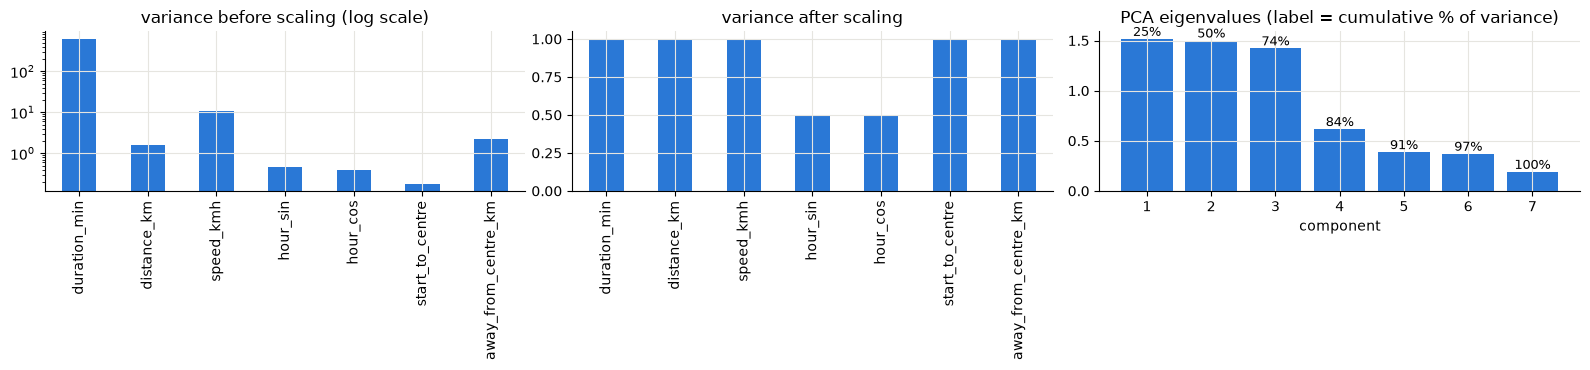

,variance before,variance after
duration_min,626.222,1.0
distance_km,1.602,1.0
speed_kmh,10.794,1.0
hour_sin,0.464,0.5
hour_cos,0.383,0.5
start_to_centre,0.181,1.0
away_from_centre_km,2.225,1.0


In [106]:
eigen = PCA().fit(X)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
features.var().plot.bar(ax=ax[0], color=COLORS[0], logy=True, title="variance before scaling (log scale)")
pd.Series(X.var(axis=0), index=features.columns).plot.bar(ax=ax[1], color=COLORS[0], title="variance after scaling")
ax[2].bar(range(1, X.shape[1] + 1), eigen.explained_variance_, color=COLORS[0])
for i, (value, total) in enumerate(zip(eigen.explained_variance_, eigen.explained_variance_ratio_.cumsum())):
    ax[2].text(i + 1, value, f"{total:.0%}", ha="center", va="bottom", fontsize=9)
ax[2].set(title="PCA eigenvalues (label = cumulative % of variance)", xlabel="component")
plt.tight_layout()
plt.show()
pd.DataFrame({"variance before": features.var(), "variance after": X.var(axis=0)}).round(3)

#### Check the correlation between the features
K-Means and Ward use distances between trips: if two features carry the same information, it counts twice.
We look at the correlation between features and at the VIF (variance inflation factor: how well a feature can be
predicted from the others; above 5 means strong redundancy).

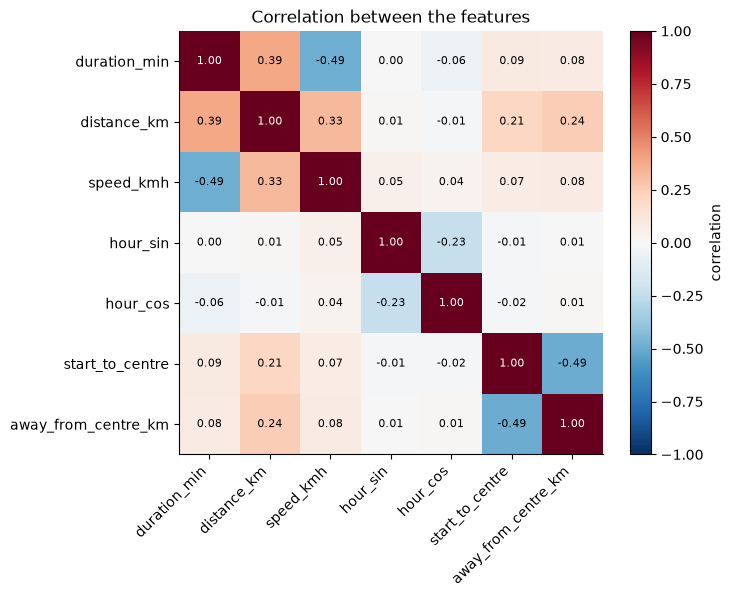

duration_min           2.35
distance_km            2.24
speed_kmh              2.23
hour_sin               1.06
hour_cos               1.06
start_to_centre        1.56
away_from_centre_km    1.58
Name: VIF, dtype: float64

In [107]:
corr = features.corr()
plt.figure(figsize=(7, 5.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for (i, j), v in np.ndenumerate(corr.to_numpy()):
    plt.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
plt.colorbar(label="correlation")
plt.grid(False)
plt.title("Correlation between the features")
plt.show()
pd.Series(np.diag(np.linalg.inv(corr)), index=corr.columns, name="VIF").round(2)

The strongest links are duration – speed (−0.49), start position – direction (−0.49: trips that start far out can
mostly only go inwards) and duration – distance (0.39). All VIF values are below 2.5, far from 5: the features are
linked but each one still brings its own information, so we keep all of them.

### 3. The two models
- **K-Means**: puts `k` centres in the data, gives each trip to the nearest centre, moves each centre to the middle of
  its trips, and repeats. Fast, so it is fitted on 200 000 trips; then every trip goes to its nearest centre.
- **Ward**: starts with each trip alone and joins, step by step, the two groups that stay the most compact.
  It needs the distance between every pair of trips, so it is fitted on 20 000 trips (about 3 GB of memory).
  Ward has no rule for new trips: every trip outside the sample goes to the nearest Ward group centre.

In [108]:
def fit_kmeans(idx, k, seed=0):
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X[idx])


def fit_ward(idx, k, seed=0):
    labels = fcluster(linkage(X[idx], method="ward"), t=k, criterion="maxclust") - 1
    return NearestCentroid().fit(X[idx], labels)   # new trips go to the nearest group centre


def sample(size, seed):
    return np.random.default_rng(seed).choice(len(X), size, replace=False)

#### Choosing the number of groups `k` for K-Means
For each `k`, K-Means is fitted on 5 different random samples of 100 000 trips. We look at:
- **inertia** (elbow): how tight the groups are, look for the bend of the curve;
- **silhouette** (higher = groups better separated) and **Davies–Bouldin** (lower = better);
- **stability**: do the 5 samples give the same groups? (adjusted Rand index, 1 = identical).

Rule: among the stable `k` (stability ≥ 0.95), keep the one with the lowest Davies–Bouldin.

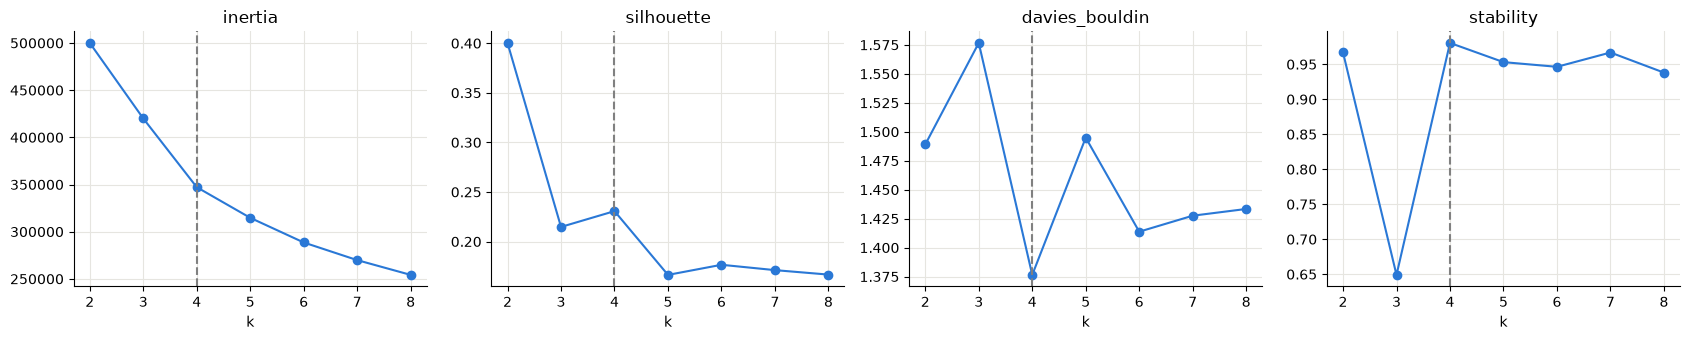

chosen k = 4


,inertia,silhouette,davies_bouldin,stability
k,,,,
2,500068.139,0.400,1.489,0.967
3,420017.033,0.215,1.577,0.649
4,347167.374,0.231,1.376,0.981
5,314706.914,0.166,1.495,0.953
6,288570.974,0.177,1.414,0.946
7,269857.932,0.171,1.428,0.967
8,254206.779,0.167,1.433,0.938


In [109]:
rows = []
for k in range(2, 9):
    runs = [fit_kmeans(sample(100_000, 100 + s), k, s) for s in range(5)]
    groups = [m.predict(X_score) for m in runs]
    rows.append({"k": k, "inertia": runs[0].inertia_,
                 "silhouette": np.mean([silhouette_score(X_score, g) for g in groups]),
                 "davies_bouldin": np.mean([davies_bouldin_score(X_score, g) for g in groups]),
                 "stability": np.mean([adjusted_rand_score(a, b) for i, a in enumerate(groups) for b in groups[i + 1:]])})
k_scores = pd.DataFrame(rows).set_index("k")
K = int(k_scores.loc[k_scores["stability"] >= 0.95, "davies_bouldin"].idxmin())

fig, ax = plt.subplots(1, 4, figsize=(17, 3.5))
for a, col in zip(ax, k_scores.columns):
    a.plot(k_scores.index, k_scores[col], marker="o", color=COLORS[0])
    a.axvline(K, color="grey", ls="--")
    a.set(title=col, xlabel="k")
plt.tight_layout()
plt.show()
print("chosen k =", K)
k_scores.round(3)

#### Fit the two models
K-Means groups are numbered by size (group 0 = the biggest). Ward groups get the number of the K-Means group they
share the most trips with, so the colours match.

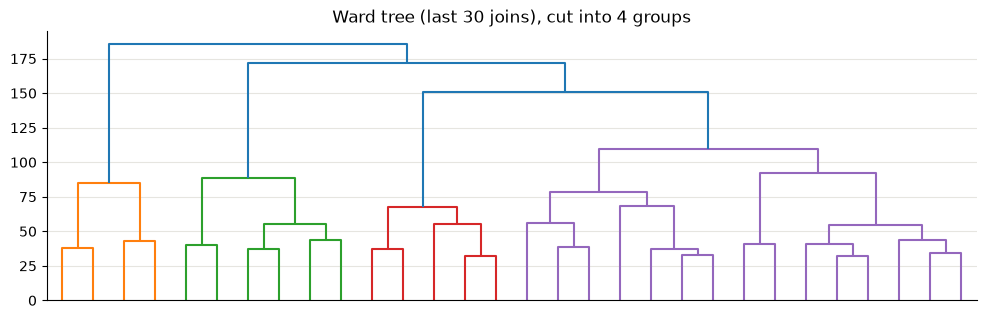

kmeans {0: 0.56, 1: 0.24, 2: 0.14, 3: 0.06}
ward {0: 0.67, 1: 0.09, 2: 0.17, 3: 0.07}


In [110]:
kmeans = fit_kmeans(sample(200_000, 1), K)
order = np.argsort(np.argsort(-np.bincount(kmeans.predict(X))))     # new number of each group, by size
trips["kmeans"] = order[kmeans.predict(X)]

ward_idx = sample(20_000, 3)
tree = linkage(X[ward_idx], method="ward")
trips["ward"] = NearestCentroid().fit(X[ward_idx], fcluster(tree, t=K, criterion="maxclust") - 1).predict(X)
rows_, cols_ = linear_sum_assignment(-pd.crosstab(trips["ward"], trips["kmeans"]).to_numpy())
trips["ward"] = trips["ward"].map(dict(zip(rows_, cols_)))

plt.figure(figsize=(12, 3.5))
dendrogram(tree, truncate_mode="lastp", p=30, no_labels=True, color_threshold=tree[-K + 1, 2])
plt.title(f"Ward tree (last 30 joins), cut into {K} groups")
plt.show()

for model in ["kmeans", "ward"]:
    print(model, trips[model].value_counts(normalize=True).sort_index().round(2).to_dict())

#### Compare the models
- **silhouette** and **Davies–Bouldin** on the same 10 000 trips;
- **agreement**: adjusted Rand index between two models (1 = same groups, 0 = no link);
- **stability**: each model is fitted again on other random samples, to check whether the groups stay the same.

In [111]:
models = {"K-Means": ("kmeans", fit_kmeans, 200_000, 5), "Ward": ("ward", fit_ward, 20_000, 5)}
labels = {name: trips[col].to_numpy()[score_idx] for name, (col, *_) in models.items()}

summary = []
for name, (col, fit, size, n_runs) in models.items():
    groups = [fit(sample(size, 200 + s), K, s).predict(X_score) for s in range(n_runs)]
    summary.append({"model": name, "silhouette": silhouette_score(X_score, labels[name]),
                    "davies_bouldin": davies_bouldin_score(X_score, labels[name]),
                    "stability": np.mean([adjusted_rand_score(a, b) for i, a in enumerate(groups) for b in groups[i + 1:]])})
print("agreement between K-Means and Ward:", round(adjusted_rand_score(labels["K-Means"], labels["Ward"]), 2))
pd.DataFrame(summary).set_index("model").round(3)

agreement between K-Means and Ward: 0.55


,silhouette,davies_bouldin,stability
model,,,
K-Means,0.230,1.378,0.991
Ward,0.265,1.312,0.626


#### 2D picture of the trips (PCA)
PCA finds the 2 directions where the trips differ the most. Each axis is a mix of features; the label shows the
3 biggest weights (for example `+0.7·duration_min` = longer trips are further right).

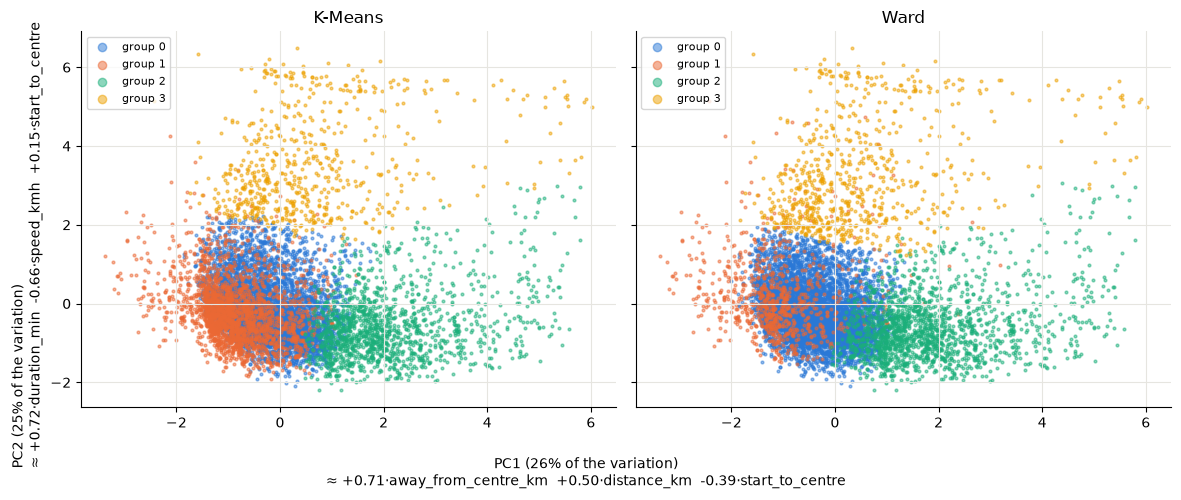

,PC1,PC2
duration_min,0.25,0.72
distance_km,0.50,0.10
speed_kmh,0.16,-0.66
hour_sin,0.03,-0.02
hour_cos,-0.00,-0.04
start_to_centre,-0.39,0.15
away_from_centre_km,0.71,-0.09


In [112]:
pca = PCA(n_components=2).fit(X_score)
points = pca.transform(X_score)
weights = pd.DataFrame(pca.components_.T, index=features.columns, columns=["PC1", "PC2"])


def axis_name(i):
    top = weights.iloc[:, i].abs().sort_values(ascending=False).index[:3]
    mix = "  ".join(f"{weights.iloc[:, i][f]:+.2f}·{f}" for f in top)
    return f"PC{i + 1} ({pca.explained_variance_ratio_[i]:.0%} of the variation)\n≈ {mix}"


fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, (name, lab) in zip(ax, labels.items()):
    for g in np.unique(lab):
        a.scatter(*points[lab == g].T, s=4, alpha=0.5, color=COLORS[g], label=f"group {g}")
    a.set_title(name)
    a.legend(markerscale=3, fontsize=8)
fig.supxlabel(axis_name(0), fontsize=10)
fig.supylabel(axis_name(1), fontsize=10)
plt.tight_layout()
plt.show()
weights.round(2)

**Comparison of the models**
- **K-Means** gives the same groups on every sample (stability ≈ 0.99), with medium separation (silhouette ≈ 0.23).
- **Ward** has slightly better separation scores (silhouette ≈ 0.27, Davies–Bouldin ≈ 1.31) and partly agrees with
  K-Means (agreement ≈ 0.55). But its groups still change between samples (stability ≈ 0.63) and one group holds about
  two thirds of the trips, so it describes the trips in less detail.
- Both models only reach medium separation (silhouette 0.23–0.27). This suggests that the trips do not form
  well-separated clouds: the groups are more like zones of one continuous cloud.
- The 2D picture agrees: the first direction is mostly *where the trip goes* (away from / towards the centre, distance),
  the second mostly *how long and how slow* it is.

We use K-Means for the interpretation because its groups are the most reproducible and more balanced. The choice of k is not certain:
k = 2 is also stable and has a better silhouette, so 4 groups is a useful level of detail rather than a definitive number.

### 4. Description of the K-Means groups
Typical trip of each group (median), with information that was **not** used for clustering.
Rush hours = weekdays 7:00–9:30 and 16:00–19:00. Summer = May to August. The last column is all trips together.

In [113]:
weekday = ~trips["weekend"]
trips["morning_rush"] = weekday & trips["hour"].between(7, 9.5)
trips["evening_rush"] = weekday & trips["hour"].between(16, 19)
describe = dict(
    share=("kmeans", "size"),
    duration_min=("duration", lambda s: s.median() / 60),
    distance_km=("distance", lambda s: s.median() / 1000),
    speed_kmh=("speed_kmh", "median"),
    start_to_centre_km=("start_to_centre_km", "median"),
    away_from_centre_km=("away_from_centre_km", "median"),
    weekend=("weekend", "mean"),
    morning_rush=("morning_rush", "mean"),
    evening_rush=("evening_rush", "mean"),
    summer=("summer", "mean"),
    electric=("electric", "mean"),
    parked_hours=("parked_hours", "median"),
    moved_by_operator=("moved_by_operator", "mean"),
    start_no_racks=("start_no_racks", "mean"),
)
profile = pd.concat([trips.groupby("kmeans").agg(**describe), trips.assign(kmeans="all trips").groupby("kmeans").agg(**describe)])
profile["share"] /= len(trips)
profile.round(2).T

kmeans,0,1,2,3,all trips
share,0.56,0.24,0.14,0.06,1.00
duration_min,9.00,13.00,19.00,92.00,12.00
distance_km,1.04,2.05,3.07,1.84,1.37
speed_kmh,6.80,9.31,10.45,1.11,7.65
start_to_centre_km,0.68,2.11,0.65,1.29,0.96
away_from_centre_km,0.25,-1.09,2.30,0.09,0.13
weekend,0.22,0.23,0.25,0.29,0.23
morning_rush,0.11,0.11,0.12,0.11,0.11
evening_rush,0.18,0.18,0.17,0.15,0.18
summer,0.37,0.38,0.40,0.41,0.38


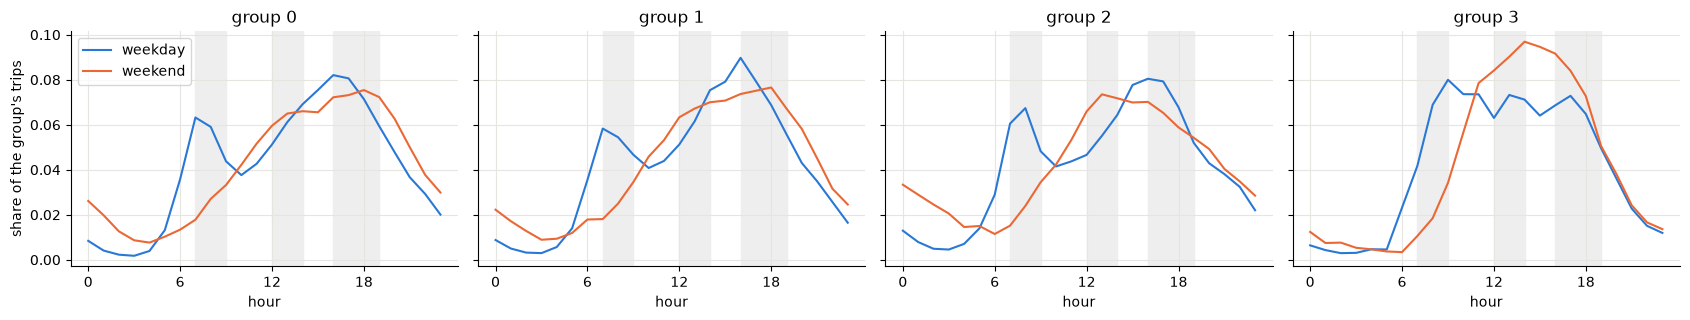

In [114]:
fig, ax = plt.subplots(1, K, figsize=(17, 3.3), sharey=True)
for g, a in enumerate(ax):
    for start, end in [(7, 9), (12, 14), (16, 19)]:    # morning, lunch, end of the school / work day
        a.axvspan(start, end, color="#eeeeee", zorder=0)
    for weekend, color in [(False, COLORS[0]), (True, COLORS[1])]:
        hours = trips.loc[(trips["kmeans"] == g) & (trips["weekend"] == weekend), "local_time"].dt.hour
        a.plot(hours.value_counts(normalize=True).sort_index(), color=color, label="weekend" if weekend else "weekday")
    a.set(title=f"group {g}", xlabel="hour", xticks=[0, 6, 12, 18])
ax[0].set_ylabel("share of the group's trips")
ax[0].legend()
plt.tight_layout()
plt.show()

**Hourly patterns** (grey bands: 7–9 h, 12–14 h, 16–19 h). The reasons for riding are not observed, so the explanations below are hypotheses.
- 7–8 h on weekdays: a clear peak for groups 0, 1 and 2; people may be going to work or to school.
- 12–14 h: no clear lunch peak; trips rise slowly during the day, so lunch-break trips, if any, do not stand out.
- 16–17 h on weekdays: the biggest peak, a bit before 18 h; it may be the end of the school day and of work.
- After 18 h: weekday trips fall, but weekend trips stay higher in the evening, possibly for evening outings.
- Weekends: no morning peak, a smooth rise up to 13–18 h, more like free time.
- Group 3 (long slow rides) starts later (about 9 h), stays high all day, and peaks at 14 h on weekends.

**Interpretation of the groups.** These are hypotheses: the data contain no rider identifier and no trip purpose.
- **Group 0 (56 %)**: short (9 min, 1.0 km) trips that start close to the centre (0.7 km) and stay there.
  Weekday peaks at about 7 h and 16 h. They look like everyday short trips in the city centre.
- **Group 1 (24 %)**: medium trips (13 min, 2.1 km) that start further out (2.1 km) and end about 1.1 km closer to the
  centre. Weekday peaks at about 7 h and, stronger, at 16 h. They look like trips towards the centre.
- **Group 2 (14 %)**: the longest direct trips (19 min, 3.1 km, 10.5 km/h). They start near the centre and end about
  2.3 km further out. More e-bikes (29 % vs 16 % for all trips) and more bikes moved by the operator before the trip
  (24 % vs 16 %). They look like trips away from the centre.
- **Group 3 (6 %)**: very long rentals (92 min) that end only 1.8 km from where they started (about 1 km/h). A bit more
  frequent at weekends (29 % vs 23 %) and in summer (41 % vs 38 %), with a weekend peak in the afternoon. They may be
  leisure rides with stops or loops, but some could also be bikes kept a long time for other reasons; the data cannot
  tell these cases apart.

#### Names of the groups
The names follow from the interpretation above. The assertions check that each name still matches its group if the data change.

In [115]:
NAMES = {0: "Short trip near the centre", 1: "Trip towards the centre", 2: "Trip away from the centre",
         3: "Long slow ride"}
groups_only = profile.drop("all trips")
assert groups_only["duration_min"].idxmax() == 3
assert groups_only["away_from_centre_km"].idxmin() == 1
assert groups_only["away_from_centre_km"].idxmax() == 2

PROFILES = [NAMES[g] for g in range(K)]
COLOR_OF = dict(zip(PROFILES, COLORS))
trips["profile"] = pd.Categorical(trips["kmeans"].map(NAMES), categories=PROFILES)
profile.rename(index=NAMES)[["share", "duration_min", "distance_km", "speed_kmh", "away_from_centre_km", "weekend", "electric"]].round(2)

,share,duration_min,distance_km,speed_kmh,away_from_centre_km,weekend,electric
kmeans,,,,,,,
Short trip near the centre,0.56,9.0,1.04,6.80,0.25,0.22,0.13
Trip towards the centre,0.24,13.0,2.05,9.31,-1.09,0.23,0.16
Trip away from the centre,0.14,19.0,3.07,10.45,2.30,0.25,0.29
Long slow ride,0.06,92.0,1.84,1.11,0.09,0.29,0.16
all trips,1.00,12.0,1.37,7.65,0.13,0.23,0.16


### 5. Profiles by context, place and bike type
**Lift** = share of a profile in a group of trips ÷ its share in all trips. 1 = normal, 1.5 = 50 % more often than normal.

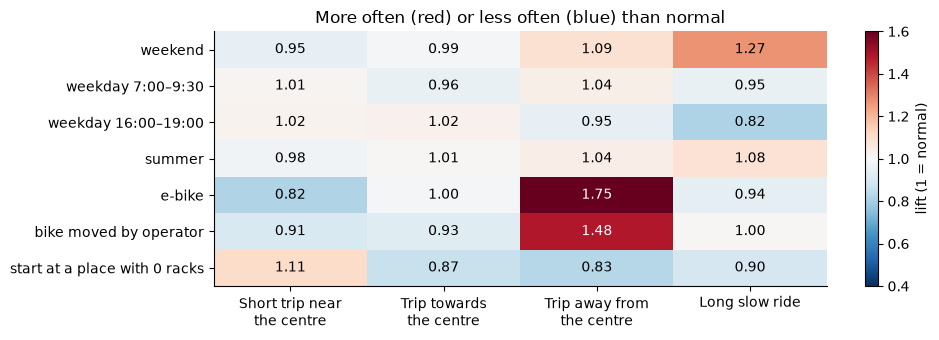

In [116]:
groups = {"weekend": trips["weekend"], "weekday 7:00–9:30": trips["morning_rush"],
          "weekday 16:00–19:00": trips["evening_rush"], "summer": trips["summer"], "e-bike": trips["electric"],
          "bike moved by operator": trips["moved_by_operator"], "start at a place with 0 racks": trips["start_no_racks"]}
normal = trips["profile"].value_counts(normalize=True)
lift = pd.DataFrame({g: trips.loc[m, "profile"].value_counts(normalize=True) / normal for g, m in groups.items()}).T[PROFILES]

fig, a = plt.subplots(figsize=(10, 3.5))
image = a.imshow(lift.to_numpy(float), cmap="RdBu_r", vmin=0.4, vmax=1.6, aspect="auto")
a.set(xticks=range(K), xticklabels=[p.replace(" the ", "\nthe ") for p in PROFILES],
      yticks=range(len(lift)), yticklabels=lift.index)
a.grid(False)
for (i, j), v in np.ndenumerate(lift.to_numpy(float)):
    a.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v - 1) > 0.35 else "black")
plt.colorbar(image, label="lift (1 = normal)")
plt.title("More often (red) or less often (blue) than normal")
plt.tight_layout()
plt.show()

#### Map of trip start points by profile
Heat map of start points on an OpenStreetMap background, centred on the city with the most trips. Each profile is a
layer that can be shown or hidden in the top-right box. The map is saved to `assets/trip_profiles_map.html`.

In [117]:
top_city = trips["city"].value_counts().index[0]
in_city = trips[trips["city"] == top_city]
m = folium.Map(location=[in_city["lat_start"].median(), in_city["lon_start"].median()], zoom_start=11, tiles="OpenStreetMap")
for i, p in enumerate(PROFILES):
    starts = trips.loc[trips["profile"] == p, ["lat_start", "lon_start"]]
    layer = folium.FeatureGroup(name=p, show=i == 0)
    HeatMap(starts.sample(min(len(starts), 20_000), random_state=0).values.tolist(),
            radius=15, blur=10, min_opacity=0.4).add_to(layer)
    layer.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save("../assets/trip_profiles_map.html")
m

#### Profiles in the 15 cities with the most trips

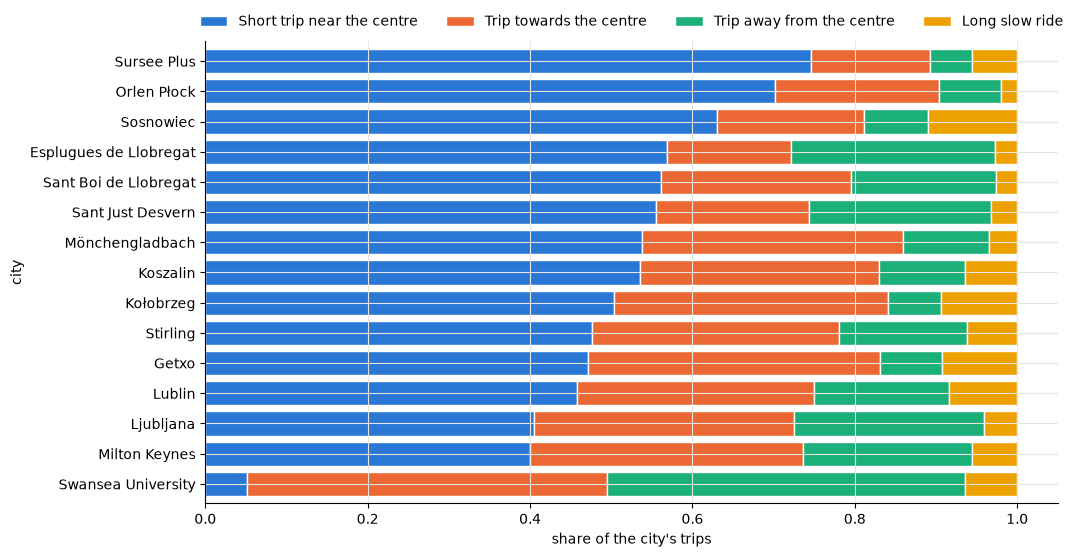

profile,Short trip near the centre,Trip towards the centre,Trip away from the centre,Long slow ride
city,,,,
Swansea University,0.05,0.44,0.44,0.06
Milton Keynes,0.40,0.34,0.21,0.06
Ljubljana,0.40,0.32,0.23,0.04
Lublin,0.46,0.29,0.17,0.08
Getxo,0.47,0.36,0.08,0.09
Stirling,0.48,0.31,0.16,0.06
Kołobrzeg,0.50,0.34,0.07,0.09
Koszalin,0.54,0.29,0.11,0.06
Mönchengladbach,0.54,0.32,0.11,0.03


In [118]:
top15 = trips["city"].value_counts().index[:15]
by_city = pd.crosstab(trips["city"], trips["profile"], normalize="index").loc[top15].sort_values(PROFILES[0])
by_city.plot.barh(stacked=True, color=COLORS[:K], width=0.8, edgecolor="white", figsize=(11, 6))
plt.xlabel("share of the city's trips")
plt.legend(ncol=K, loc="lower center", bbox_to_anchor=(0.5, 1), frameon=False)
plt.show()
by_city.round(2)

### 6. Trips by country
How many trips and cities each country has, a few simple indicators, and the mix of profiles.
A country with only one or a few cities mostly shows those cities, not the whole country.

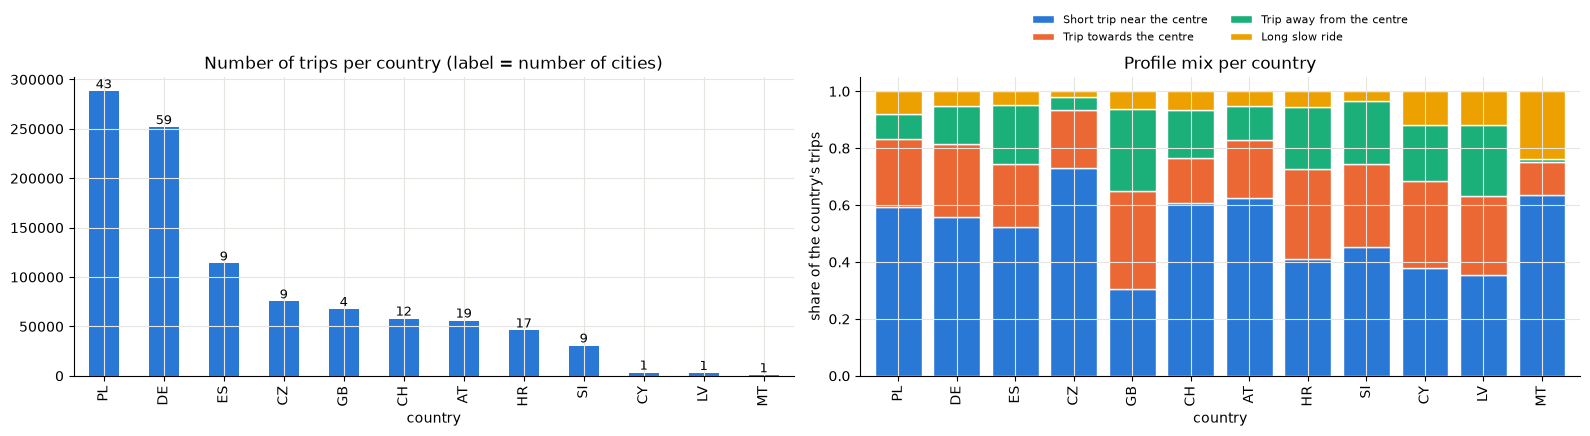

,trips,cities,duration_min,weekend,electric,no_racks,share,Short trip near the centre,Trip towards the centre,Trip away from the centre,Long slow ride
country,,,,,,,,,,,
PL,288027,43,14.0,0.28,0.01,0.02,0.29,0.59,0.24,0.09,0.08
DE,251650,59,10.0,0.19,0.08,0.37,0.25,0.56,0.26,0.13,0.05
ES,113710,9,12.0,0.20,0.78,0.01,0.11,0.52,0.22,0.21,0.05
CZ,75299,9,8.0,0.22,0.00,0.73,0.08,0.73,0.20,0.05,0.02
GB,67609,4,18.0,0.25,0.04,0.00,0.07,0.31,0.34,0.29,0.06
CH,57950,12,9.0,0.21,0.00,0.99,0.06,0.61,0.16,0.17,0.06
AT,55907,19,12.0,0.22,0.00,0.75,0.06,0.63,0.20,0.12,0.05
HR,45952,17,16.0,0.22,0.46,0.20,0.05,0.41,0.31,0.22,0.05
SI,30653,9,13.0,0.18,0.91,0.00,0.03,0.45,0.29,0.22,0.03


In [119]:
by_country = trips.groupby("country").agg(
    trips=("city", "size"), cities=("city", "nunique"), duration_min=("duration", lambda s: s.median() / 60),
    weekend=("weekend", "mean"), electric=("electric", "mean"), no_racks=("start_no_racks", "mean"),
).sort_values("trips", ascending=False)
by_country["share"] = by_country["trips"] / len(trips)
mix = pd.crosstab(trips["country"], trips["profile"], normalize="index").loc[by_country.index]

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
by_country["trips"].plot.bar(ax=ax[0], color=COLORS[0], title="Number of trips per country (label = number of cities)")
for i, (n, c) in enumerate(zip(by_country["trips"], by_country["cities"])):
    ax[0].text(i, n, c, ha="center", va="bottom", fontsize=9)
mix.plot.bar(stacked=True, ax=ax[1], color=COLORS[:K], width=0.8, edgecolor="white", title="Profile mix per country")
ax[1].legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=2, frameon=False)
ax[1].set(ylabel="share of the country's trips")
plt.tight_layout()
plt.show()
pd.concat([by_country.round(2), mix.round(2)], axis=1)

**Observations**

- Trips are concentrated in two countries: Poland (29 %, 43 cities) and Germany (25 %, 59 cities) hold more
  than half of the trips. Cyprus, Latvia and Malta have one city each and less than 0.3 % of the trips, so their
  numbers only describe that one city.
- The bike fleet changes a lot between countries: e-bikes are 91 % of the trips in Slovenia and 78 % in Spain,
  46 % in Croatia, but almost none in Czechia, Switzerland, Austria and Poland. This most likely reflects the bikes
  each system offers, not a choice of the riders.
- Places with 0 racks (maybe virtual stations) are almost all the start places in Switzerland (99 %), and most of
  them in Austria (75 %) and Czechia (73 %), but almost none in the UK, Spain or Slovenia: again a difference between
  systems.
- The profile mix also differs: in Czechia 73 % of the trips are short trips near the centre (median 8 min),
  while in the UK only 31 % are, with many trips towards (34 %) or away from (29 %) the centre and longer trips
  (median 18 min). The UK data come from only 4 cities, one of them a university network, which may explain part of
  this. Spain, Croatia and Slovenia have more trips away from the centre (21–22 %) and also many e-bikes; with this
  data we cannot say whether the country or the e-bikes explain it.
- Poland has the most weekend trips (28 % vs 19 % in Germany) and the most long slow rides among the big countries
  (8 %).

These differences mix several effects (city size, bike fleet, type of stations, number of cities per country), so
they describe the data we have rather than general habits of each country.

### 7. Conclusions

| profile | share | typical trip |
|---|---|---|
| Short trip near the centre | 56 % | 9 min, 1.0 km, starts and ends near the centre |
| Trip towards the centre | 24 % | 13 min, 2.1 km, from the outskirts to about 1.1 km closer to the centre |
| Trip away from the centre | 14 % | 19 min, 3.1 km, from the centre to about 2.3 km further out |
| Long slow ride | 6 % | 92 min, 1.8 km from start to end |

The results suggest the following:
- Most trips seem to be short, direct trips from one point to another with weekday rush-hour peaks; long slow rides are a small part.
- The direction of the trip (towards or away from the centre) separates the trips more than the time of day.
- E-bikes appear more often in the longest direct trips (away from the centre), which could mean they are used to go
  further.
- Trips away from the centre more often start on a bike moved by the operator; this fits with bikes being brought
  back to the centre, but we cannot check it directly.
- The mix of profiles changes a lot between cities and countries, and so do the bike fleet (e-bikes) and the type
  of stations; these system differences probably explain part of the profile differences.

**Limitations**
- Only trips with a station at both ends are in the cleaned data (free-floating trips were removed), so the profiles
  describe station-based use only.
- There is no rider id: we group trips, not people, and the purpose of a trip (work, leisure…) is only a guess.
- Distance is a straight line between start and end, so loops and trips with stops look short and slow.
- The city centre is estimated as the median start point; for regional networks this may be far from the real centre.
- Some cities have few trips, and some countries only one or a few cities, so their profile mix is less reliable.
- Cargo bikes are only 0.06 % of the trips: too few to say anything about them.
- The data cover one year (Aug 2022 – Jul 2023) without weather or holidays, which could explain part of the patterns.
- The groups overlap (medium silhouette): they show tendencies, not strict types.

In [120]:
# Start this part with a clean memory and the default plot style, as if it was its own notebook
%reset -f
import matplotlib.pyplot as plt
plt.rcdefaults()

## Part B — Clustering Bike-Sharing Stations

Trip and status records are aggregated into six station-level features covering activity, trip characteristics, and bike availability. The analysis validates records, selects stations, standardizes features, and applies Principal Component Analysis (PCA) to prepare inputs for clustering. The final table preserves original measurements alongside PC scores for group interpretation.

### 1. Data Sources

**Purpose.** Identify the input tables and their analytical roles.

| Table | Unit of observation | Analytical role |
|---|---|---|
| `stations` | One station | Station and system identifiers, location |
| `cities` | One bike-sharing system | System name and country |
| `trips` | One trip | Departures, arrivals, duration, and distance |
| `station_status` | A station at a recorded time | Available bikes and record-quality indicators |

In [121]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

OUT_DIR = Path("../output/part_b")
OUT_DIR.mkdir(parents=True, exist_ok=True)

stations = pd.read_csv("../data_cleaned/cleaned_stations.csv")
cities = pd.read_csv("../data_cleaned/cities_clean.csv")
trips = pd.read_csv("../data_cleaned/trips_small_cleaned.csv")
station_status = pd.read_csv("../data_cleaned/stations_status_clean.csv")

input_summary = pd.DataFrame({
    "table": ["stations", "cities", "trips", "station_status"],
    "rows": [len(stations), len(cities), len(trips), len(station_status)],
    "columns": [stations.shape[1], cities.shape[1], trips.shape[1], station_status.shape[1]],
})
display(input_summary)

,table,rows,columns
0,stations,2900,8
1,cities,267,7
2,trips,993542,13
3,station_status,2925807,13


**Results.** The input contains 2,900 stations, 267 systems, 993,542 trips, and 2,925,807 status records.

### 2. Station Reference Table

**Purpose.** Assign each station to one system without duplicating records during joins.

Station and system IDs must be unique, and each station's system must exist. A left join on `city_id` retains all stations and adds system information. Here, a bike-sharing system does not necessarily correspond to one geographical city.

Country and coordinates are retained for interpretation and mapping, not as PCA inputs.

In [122]:
assert stations["id"].is_unique, "Station IDs are not unique."
assert cities["id"].is_unique, "System IDs are not unique."
assert stations["city_id"].isin(cities["id"]).all(), "Some stations have no matching system."

station_meta = stations[["id", "city_id", "lon", "lat"]].rename(columns={"id": "station_id"})
systems = cities[["id", "name", "country"]].rename(columns={"id": "city_id", "name": "system_name"})
station_meta = station_meta.merge(systems, on="city_id", how="left", validate="many_to_one")
display(station_meta.head())

,station_id,city_id,lon,lat,system_name,country
0,142186362,135,7.821669,51.677449,Hamm,DE
1,940986,176,13.868973,54.090538,Usedom,DE
2,93646685,176,13.918970,54.073088,Usedom,DE
3,111365509,243,-3.936120,56.119272,Stirling,GB
4,405835,302,14.481456,35.906836,Malta,MT


**Results.** Both ID uniqueness checks pass, and every station has a matching system.

### 3. Time and Value Validation

**Purpose.** Verify the times and measurements used to construct features.

Trip start timestamps are converted from seconds to UTC. Arrival time equals start time plus duration. Status timestamps are also converted to UTC.

Trips require valid start and arrival times, finite positive duration, and finite non-negative distance. Status records require valid times and unique station-and-time pairs. UTC dates define the sample windows.

In [123]:
trips["start_utc"] = pd.to_datetime(trips["time_start"], unit="s", utc=True, errors="coerce")
trips["end_utc"] = trips["start_utc"] + pd.to_timedelta(trips["duration"], unit="s")
station_status["utc_time"] = pd.to_datetime(station_status["time"], utc=True, errors="coerce")

valid_trips = (
    trips["start_utc"].notna() & trips["end_utc"].notna()
    & np.isfinite(trips["duration"]) & (trips["duration"] > 0)
    & np.isfinite(trips["distance"]) & (trips["distance"] >= 0)
)
valid_status_time = station_status["utc_time"].notna()
cleaning_summary = pd.DataFrame({
    "check": ["Invalid trip time or value", "Invalid status time"],
    "removed_records": [(~valid_trips).sum(), (~valid_status_time).sum()],
})
display(cleaning_summary)

trips = trips.loc[valid_trips].copy()
station_status = station_status.loc[valid_status_time].copy()
assert not station_status.duplicated(["station_id", "utc_time"]).any(), "Repeated station and time records exist."

,check,removed_records
0,Invalid trip time or value,0
1,Invalid status time,0


**Results.** No records fail the time or trip-value checks, and no duplicate station-and-time pairs are found.

### 4. Trip Features and Observation Windows

**Purpose.** Measure station activity and trip characteristics while accounting for different system sample lengths.

Departures and arrivals are assigned to their respective station endpoints. Only known endpoints are retained; an unknown endpoint does not remove the other valid endpoint. System membership follows the station reference table.

Departure trips provide average duration in minutes and average endpoint distance in kilometres. Distance measures geographical separation, not the route travelled.

Each system's window runs from its first to last matched event date, inclusive. All stations in that system use the same denominator:

`daily activity = matched event count / system window days`

This reduces differences caused by sample length. It does not establish complete daily recording or continuous station operation.

In [124]:
departures = trips[["station_id_start", "start_utc", "duration", "distance"]].rename(
    columns={"station_id_start": "station_id", "start_utc": "utc_time"}
)
arrivals = trips[["station_id_end", "end_utc"]].rename(
    columns={"station_id_end": "station_id", "end_utc": "utc_time"}
)

known_departures = departures["station_id"].isin(station_meta["station_id"])
known_arrivals = arrivals["station_id"].isin(station_meta["station_id"])
endpoint_summary = pd.DataFrame({
    "endpoint": ["Departure", "Arrival"],
    "matched": [known_departures.sum(), known_arrivals.sum()],
    "unknown_or_missing": [(~known_departures).sum(), (~known_arrivals).sum()],
})
display(endpoint_summary)

departures = departures.loc[known_departures].copy()
arrivals = arrivals.loc[known_arrivals].copy()
departures["station_id"] = departures["station_id"].astype("int64")
arrivals["station_id"] = arrivals["station_id"].astype("int64")
departures["duration_min"] = departures["duration"] / 60
departures["distance_km"] = departures["distance"] / 1000

departure_summary = departures.groupby("station_id").agg(
    departure_count=("utc_time", "size"),
    avg_duration_min=("duration_min", "mean"),
    avg_distance_km=("distance_km", "mean"),
)
arrival_counts = arrivals.groupby("station_id").size().rename("arrival_count")

# This small event table is only used to find each system's sample window.
events = pd.concat([departures[["station_id", "utc_time"]], arrivals], ignore_index=True)
events = events.merge(station_meta[["station_id", "city_id"]], on="station_id", validate="many_to_one")
events["date"] = events["utc_time"].dt.normalize()
system_windows = events.groupby("city_id").agg(first_date=("date", "min"), last_date=("date", "max"))
system_windows["sample_days"] = (system_windows["last_date"] - system_windows["first_date"]).dt.days + 1

station_features = station_meta.set_index("station_id").join(departure_summary)
station_features = station_features.join(arrival_counts)
station_features = station_features.join(system_windows["sample_days"], on="city_id")
station_features[["departure_count", "arrival_count"]] = station_features[["departure_count", "arrival_count"]].fillna(0)
station_features["departures_per_day"] = station_features["departure_count"] / station_features["sample_days"]
station_features["arrivals_per_day"] = station_features["arrival_count"] / station_features["sample_days"]
display(station_features.head())

,endpoint,matched,unknown_or_missing
0,Departure,972199,21343
1,Arrival,913829,79713


,city_id,lon,lat,system_name,country,departure_count,avg_duration_min,avg_distance_km,arrival_count,sample_days,departures_per_day,arrivals_per_day
station_id,,,,,,,,,,,,
142186362,135,7.821669,51.677449,Hamm,DE,0.0,NaN,NaN,0.0,324.0,0.000000,0.000000
940986,176,13.868973,54.090538,Usedom,DE,11.0,34.272727,3.195451,4.0,81.0,0.135802,0.049383
93646685,176,13.918970,54.073088,Usedom,DE,3.0,42.666667,3.500575,3.0,81.0,0.037037,0.037037
111365509,243,-3.936120,56.119272,Stirling,GB,2.0,95.000000,2.476699,0.0,324.0,0.006173,0.000000
405835,302,14.481456,35.906836,Malta,MT,27.0,14.333333,1.720082,21.0,132.0,0.204545,0.159091


**Results.** There are 972,199 matched departures and 913,829 matched arrivals. Unknown or missing endpoints account for 21,343 starts and 79,713 ends. Matched events cover 181 systems, with windows of 1-324 calendar days.

The unequal endpoint coverage may affect the observed borrowing-return balance.

### 5. Bike Availability Features

**Purpose.** Describe recorded supply and the frequency of empty observations.

Accepted status records belong to known stations, have no maintenance or availability-mismatch flag, and contain non-negative bike counts. Their mean available-bike count and share of zero-bike records form the two supply features.

Records receive equal weight despite unequal recording intervals. The empty-record share therefore measures observations, not the proportion of time without bikes.

In [125]:
known_status = station_status["station_id"].isin(station_meta["station_id"])
accepted_status = (
    known_status & ~station_status["maintenance"] & ~station_status["availability_mismatch"]
    & (station_status["bikes_available_to_rent"] >= 0)
)
online = station_status.loc[accepted_status, ["station_id", "bikes_available_to_rent"]].copy()
online["is_empty"] = online["bikes_available_to_rent"] == 0

status_summary = online.groupby("station_id").agg(
    status_count=("is_empty", "size"),
    avg_available_bikes=("bikes_available_to_rent", "mean"),
    empty_record_share=("is_empty", "mean"),
)
station_features = station_features.join(status_summary)
station_features["status_count"] = station_features["status_count"].fillna(0)

status_check = pd.DataFrame({
    "record_type": ["Valid time", "Known station", "Accepted for availability"],
    "records": [len(station_status), known_status.sum(), accepted_status.sum()],
})
display(status_check)
display(status_summary.head())

,record_type,records
0,Valid time,2925807
1,Known station,2903613
2,Accepted for availability,2770776


,status_count,avg_available_bikes,empty_record_share
station_id,,,
94,89,3.707865,0.044944
522,268,3.246269,0.022388
556,303,4.016502,0.006601
568,132,2.863636,0.098485
572,61,3.950820,0.016393


**Results.** Of 2,903,613 status records from known stations, 2,770,776 satisfy the availability conditions.

### 6. Station Selection and Feature Set

**Purpose.** Retain stations with enough observations to estimate trip and availability features.

Stations require at least 20 matched departures, 20 matched arrivals, and 50 accepted status records. These thresholds are analytical choices. Exclusion counts can overlap because a station may fail several rules. Missing trip averages are not replaced with zero.

| Feature | Definition | Unit |
|---|---|---|
| `departures_per_day` | Matched departures / system window days | Departures/day |
| `arrivals_per_day` | Matched arrivals / system window days | Arrivals/day |
| `avg_duration_min` | Mean duration of departure trips | Minutes |
| `avg_distance_km` | Mean endpoint distance of departure trips | Kilometres |
| `avg_available_bikes` | Mean available-bike count in accepted records | Bikes |
| `empty_record_share` | Accepted zero-bike records / accepted records | 0 to 1 |

In [126]:
MIN_DEPARTURES = 20
MIN_ARRIVALS = 20
MIN_STATUS_RECORDS = 50

enough_data = (
    (station_features["departure_count"] >= MIN_DEPARTURES)
    & (station_features["arrival_count"] >= MIN_ARRIVALS)
    & (station_features["status_count"] >= MIN_STATUS_RECORDS)
)
selection_summary = pd.DataFrame({
    "rule": ["Fewer than 20 departures", "Fewer than 20 arrivals", "Fewer than 50 status records"],
    "stations_failing": [
        (station_features["departure_count"] < MIN_DEPARTURES).sum(),
        (station_features["arrival_count"] < MIN_ARRIVALS).sum(),
        (station_features["status_count"] < MIN_STATUS_RECORDS).sum(),
    ],
})
display(selection_summary)

analysis_stations = station_features.loc[enough_data].copy()
FEATURES = [
    "departures_per_day", "arrivals_per_day", "avg_duration_min",
    "avg_distance_km", "avg_available_bikes", "empty_record_share",
]
X = analysis_stations[FEATURES].copy()
assert len(X) > len(FEATURES), "Too few stations for this analysis."
assert np.isfinite(X.to_numpy()).all(), "The feature table contains missing or infinite values."
assert (X.std() > 0).all(), "A feature has no variation."
display(X.describe().T)

,rule,stations_failing
0,Fewer than 20 departures,546
1,Fewer than 20 arrivals,552
2,Fewer than 50 status records,396


,count,mean,std,min,25%,50%,75%,max
departures_per_day,2235.0,1.621681,2.792087,0.061728,0.279751,0.758514,1.751543,34.203593
arrivals_per_day,2235.0,1.481529,2.353913,0.061728,0.273148,0.722222,1.657062,28.281437
avg_duration_min,2235.0,25.727645,16.464256,4.916426,15.845311,21.907837,30.204011,209.135135
avg_distance_km,2235.0,2.154453,1.234841,0.386022,1.343601,1.860236,2.566634,13.594652
avg_available_bikes,2235.0,4.836540,3.834621,0.577778,2.796998,4.126829,6.204391,102.818898
empty_record_share,2235.0,0.072784,0.081126,0.000000,0.016438,0.045061,0.101797,0.504036


**Results.** The selection retains 2,235 stations (77.1%) and excludes 665. All six feature columns contain finite values and non-zero variation.

#### 6.1. Descriptive Feature Relationships

**Purpose.** Identify activity patterns, overlapping features, and system differences.

The tables report feature distributions, Pearson correlations, and system medians. System comparisons require at least 10 selected stations per system. These summaries do not change the model inputs.

,mean,10%,50%,90%,max
departures_per_day,1.622,0.145,0.759,3.816,34.204
arrivals_per_day,1.482,0.138,0.722,3.619,28.281
avg_duration_min,25.728,11.862,21.908,42.219,209.135
avg_distance_km,2.154,1.043,1.860,3.594,13.595
avg_available_bikes,4.837,2.005,4.127,8.223,102.819
empty_record_share,0.073,0.004,0.045,0.172,0.504


,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share
departures_per_day,1.000,0.958,-0.171,-0.156,0.211,-0.114
arrivals_per_day,0.958,1.000,-0.183,-0.175,0.217,-0.134
avg_duration_min,-0.171,-0.183,1.000,0.760,0.236,-0.002
avg_distance_km,-0.156,-0.175,0.760,1.000,0.079,0.031
avg_available_bikes,0.211,0.217,0.236,0.079,1.000,-0.476
empty_record_share,-0.114,-0.134,-0.002,0.031,-0.476,1.000


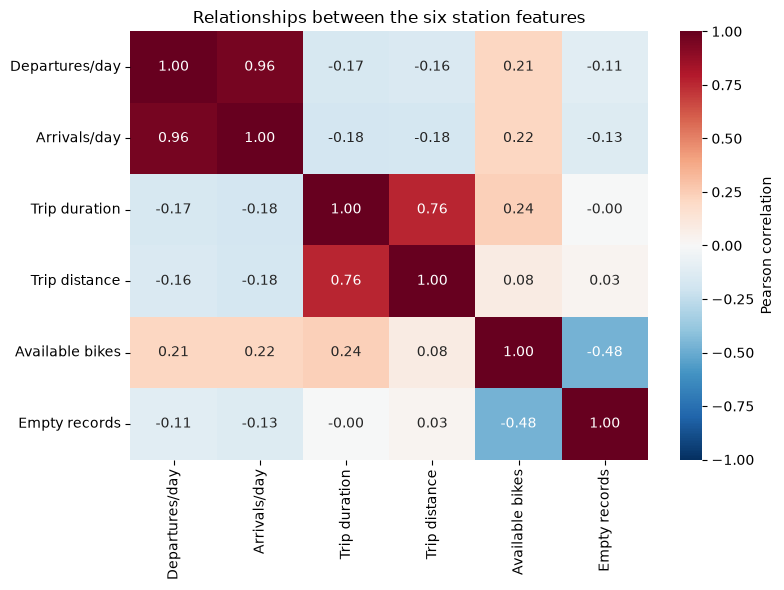

,,station_count,median_departures_per_day,median_duration_min,median_available_bikes,median_empty_share
city_id,system_name,,,,,
856,Sant Boi de Llobregat,10,15.722,15.702,5.112,0.065
848,Esplugues de Llobregat,11,12.910,16.274,4.086,0.109
639,Orlen Płock,19,9.464,14.144,6.842,0.040
422,Kołobrzeg,12,5.290,25.631,8.569,0.016
523,Ciechanów,10,3.992,19.229,6.942,0.026
431,Kalisz,16,3.575,23.065,7.633,0.000
496,Koszalin,20,3.387,23.209,8.107,0.009
710,Rendsburg,11,2.760,12.921,4.153,0.076
497,Sosnowiec,24,2.576,27.692,6.605,0.022


In [127]:
FEATURE_LABELS = {
    "departures_per_day": "Departures/day",
    "arrivals_per_day": "Arrivals/day",
    "avg_duration_min": "Trip duration",
    "avg_distance_km": "Trip distance",
    "avg_available_bikes": "Available bikes",
    "empty_record_share": "Empty records",
}
feature_summary = X.describe(percentiles=[0.10, 0.50, 0.90]).T
display(feature_summary[["mean", "10%", "50%", "90%", "max"]].round(3))

feature_correlations = X.corr()
display(feature_correlations.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    feature_correlations.rename(index=FEATURE_LABELS, columns=FEATURE_LABELS),
    annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="RdBu_r", ax=ax,
    cbar_kws={"label": "Pearson correlation"},
)
ax.set_title("Relationships between the six station features")
fig.tight_layout()
plt.show()

system_summary = analysis_stations.groupby(["city_id", "system_name"]).agg(
    station_count=("departures_per_day", "size"),
    median_departures_per_day=("departures_per_day", "median"),
    median_duration_min=("avg_duration_min", "median"),
    median_available_bikes=("avg_available_bikes", "median"),
    median_empty_share=("empty_record_share", "median"),
)
larger_systems = system_summary.loc[system_summary["station_count"] >= 10]
display(larger_systems.sort_values("median_departures_per_day", ascending=False).head(10).round(3))

**Results.** Median activity is 0.76 departures and 0.72 arrivals per day. The departure-rate 90th percentile is 3.82, five times the median. Departure and arrival rates have r = 0.958; average duration and distance have r = 0.760.

Median average-bike availability is 4.13, with a maximum of 102.82. The median empty-record share is 4.5%, increasing to 17.2% at the 90th percentile. Availability and empty-record share have r = -0.476.

The selected sample covers 168 systems and 12 countries. Among 83 systems with at least 10 stations, median daily departures range from 0.12 to 15.72.

**Insights.** Borrowing and return rates contain substantial overlapping activity information. Supply and activity are uneven across stations, and system differences may contribute to later clusters.

### 7. Feature Standardization

**Purpose.** Prevent different measurement units from determining PCA contributions.

`StandardScaler` transforms each feature using:

`standardized value = (value - mean) / population standard deviation`

The check uses `ddof=0`, matching the scaler. Original-unit values remain available for interpretation. Standardization changes scale but does not remove outlier influence.

In [128]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=FEATURES)
scale_check = pd.DataFrame({
    "mean": X_scaled.mean(),
    "population_std": X_scaled.std(ddof=0),
})
display(scale_check.round(6))

,mean,population_std
departures_per_day,-0.0,1.0
arrivals_per_day,0.0,1.0
avg_duration_min,0.0,1.0
avg_distance_km,0.0,1.0
avg_available_bikes,-0.0,1.0
empty_record_share,0.0,1.0


**Results.** Column means are effectively zero and population standard deviations are one. Maximum numerical deviations are 1.24e-16 and 2.22e-16, respectively.

### 8. Principal Component Analysis

**Purpose.** Summarize related features while retaining most of their variation.

PCA forms weighted combinations of the standardized features. The smallest number of components reaching 90% cumulative explained variance is retained. This criterion measures feature variation, not clustering quality.

,component,explained_share,cumulative_share
0,PC1,0.377818,0.377818
1,PC2,0.298822,0.676641
2,PC3,0.197017,0.873658
3,PC4,0.083440,0.957098


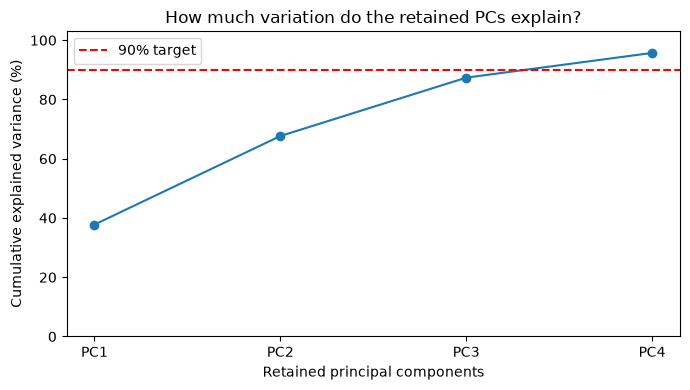

In [129]:
pca = PCA(n_components=0.90, svd_solver="full")
scores = pca.fit_transform(X_scaled)
pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
pca_scores = pd.DataFrame(scores, index=X.index, columns=pc_names)

explained_variance = pd.DataFrame({
    "component": pc_names,
    "explained_share": pca.explained_variance_ratio_,
    "cumulative_share": np.cumsum(pca.explained_variance_ratio_),
})
display(explained_variance)

plt.figure(figsize=(7, 4))
plt.plot(pc_names, explained_variance["cumulative_share"] * 100, marker="o")
plt.axhline(90, color="red", linestyle="--", label="90% target")
plt.xlabel("Retained principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("How much variation do the retained PCs explain?")
plt.ylim(0, 103)
plt.legend()
plt.tight_layout()
plt.show()

**Results.** Four components explain 95.71% of standardized feature variation. PC1 and PC2 explain 67.66%, leaving 32.34% outside the two-dimensional view. All four components are retained, including the supply differences represented by PC3 and PC4.

### 9. Component Weights and Feature Associations

**Purpose.** Relate component scores to the station measurements.

Weights define each PC's formula; larger absolute weights indicate larger contributions. Feature-score correlations describe linear associations across stations and are reported separately. Reversing a component's sign leaves the PCA solution unchanged, so score signs do not indicate performance quality.

,PC1,PC2,PC3,PC4
departures_per_day,0.584,0.173,0.356,-0.068
arrivals_per_day,0.591,0.170,0.334,-0.078
avg_duration_min,-0.339,0.556,0.249,0.058
avg_distance_km,-0.350,0.499,0.347,-0.287
avg_available_bikes,0.186,0.514,-0.404,0.697
empty_record_share,-0.193,-0.344,0.645,0.646


,PC1,PC2,PC3,PC4
departures_per_day,0.879,0.232,0.387,-0.048
arrivals_per_day,0.890,0.227,0.363,-0.055
avg_duration_min,-0.511,0.744,0.270,0.041
avg_distance_km,-0.527,0.668,0.377,-0.203
avg_available_bikes,0.280,0.689,-0.439,0.493
empty_record_share,-0.290,-0.461,0.701,0.457


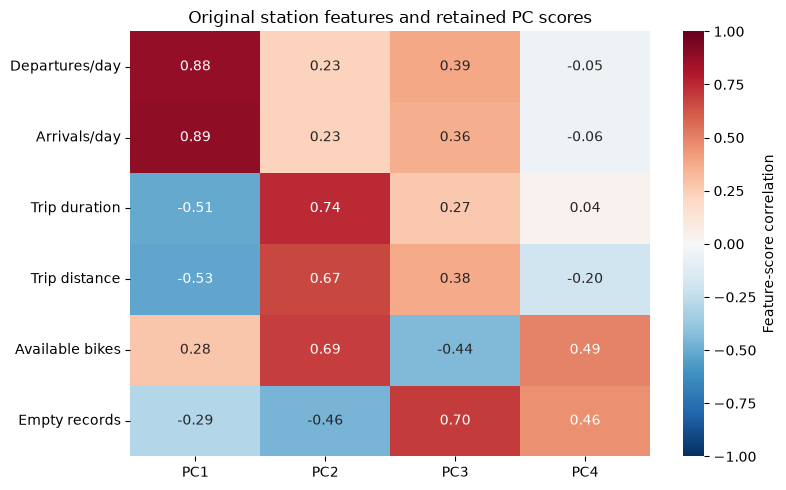

In [130]:
weights = pd.DataFrame(pca.components_.T, index=FEATURES, columns=pc_names)
display(weights.round(3))
feature_pc_correlations = pd.DataFrame({
    pc: X_scaled.corrwith(pca_scores[pc]) for pc in pc_names
})
display(feature_pc_correlations.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    feature_pc_correlations.rename(index=FEATURE_LABELS),
    annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="RdBu_r", ax=ax,
    cbar_kws={"label": "Feature-score correlation"},
)
ax.set_title("Original station features and retained PC scores")
fig.tight_layout()
plt.show()

**Results.** The strongest feature-score associations are:

| Component | Two strongest associations |
|---|---|
| PC1 | `arrivals_per_day` (+0.890); `departures_per_day` (+0.879) |
| PC2 | `avg_duration_min` (+0.744); `avg_available_bikes` (+0.689) |
| PC3 | `empty_record_share` (+0.701); `avg_available_bikes` (-0.439) |
| PC4 | `avg_available_bikes` (+0.493); `empty_record_share` (+0.457) |

Values are Pearson correlations. PC1 contrasts activity with trip length; PC2 combines trip length and supply. PC3 and PC4 retain further supply differences, examined in Section 10.

### 10. Quantitative Profiles Along the Components

**Purpose.** Interpret component directions in original feature units.

For each PC, feature medians are compared between the bottom and top score quartiles. These groups describe the fitted directions, not clusters or changes over time. They are derived from the PCA inputs and therefore do not independently validate station classes.

A separate PC4 table compares supply means, medians, and maxima to assess within-group variation.

In [131]:
profile_rows = []
for pc in pc_names:
    lower = pca_scores[pc] <= pca_scores[pc].quantile(0.25)
    upper = pca_scores[pc] >= pca_scores[pc].quantile(0.75)
    for group_name, mask in [("Bottom 25%", lower), ("Top 25%", upper)]:
        row = {"component": pc, "score_group": group_name, "stations": int(mask.sum())}
        row.update(X.loc[mask].median().to_dict())
        profile_rows.append(row)
component_profiles = pd.DataFrame(profile_rows)
display(component_profiles.round(3))

pc4_supply_rows = []
for group_name, mask in [
    ("Bottom 25%", pca_scores["PC4"] <= pca_scores["PC4"].quantile(0.25)),
    ("Top 25%", pca_scores["PC4"] >= pca_scores["PC4"].quantile(0.75)),
]:
    bikes = X.loc[mask, "avg_available_bikes"]
    pc4_supply_rows.append({
        "PC4 score group": group_name,
        "stations": len(bikes),
        "mean_available_bikes": bikes.mean(),
        "median_available_bikes": bikes.median(),
        "maximum_available_bikes": bikes.max(),
    })
pc4_supply_check = pd.DataFrame(pc4_supply_rows)
display(pc4_supply_check.round(3))

,component,score_group,stations,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share
0,PC1,Bottom 25%,559,0.222,0.216,37.098,3.216,3.000,0.083
1,PC1,Top 25%,559,3.179,3.025,17.181,1.475,6.162,0.028
2,PC2,Bottom 25%,559,0.494,0.500,13.964,1.241,2.436,0.123
3,PC2,Top 25%,559,0.818,0.746,34.265,2.920,6.677,0.017
4,PC3,Bottom 25%,559,0.784,0.769,19.324,1.531,6.694,0.010
5,PC3,Top 25%,559,0.590,0.531,24.291,2.267,2.558,0.136
6,PC4,Bottom 25%,559,0.414,0.398,27.788,2.720,4.017,0.033
7,PC4,Top 25%,559,0.684,0.654,18.613,1.592,2.575,0.139


,PC4 score group,stations,mean_available_bikes,median_available_bikes,maximum_available_bikes
0,Bottom 25%,559,4.251,4.017,11.520
1,Top 25%,559,5.428,2.575,102.819


**Results.** Feature medians in the bottom and top score quartiles are:

| Component | Bottom quartile to top quartile |
|---|---|
| PC1 | Departures/day: 0.22 to 3.18; duration: 37.10 to 17.18 min; distance: 3.22 to 1.47 km |
| PC2 | Duration: 13.96 to 34.26 min; distance: 1.24 to 2.92 km; available bikes: 2.44 to 6.68 |
| PC3 | Empty-record share: 1.0% to 13.6%; available bikes: 6.69 to 2.56; departures/day: 0.78 to 0.59 |
| PC4 | Available bikes: 4.02 to 2.57; empty-record share: 3.3% to 13.9% |

**Insights.** PC3's upper quartile has more empty observations despite lower median daily departures. Activity alone does not capture recorded supply differences.

PC4's upper quartile has a higher mean available-bike count (5.43 versus 4.25), but a lower median (2.57 versus 4.02) and a larger maximum (102.82 versus 11.52). A higher PC4 score therefore does not imply uniformly greater supply. Group descriptions require medians or distributions alongside means.

### 11. Final Dataset and Clustering Interface

**Purpose.** Support clustering and original-unit interpretation through one station-level table.

| Role | Columns | Use |
|---|---|---|
| Reference | `station_id`, `city_id`, `system_name`, `country`, `lon`, `lat` | Link records, compare systems, and map results |
| Observation | `sample_days`, `departure_count`, `arrival_count`, `status_count` | Assess data support |
| Original features | Six features from Section 6 | Interpret station groups |
| Model input | `PC1`, `PC2`, `PC3`, `PC4` | Fit clustering models |

Clustering uses only the PC columns, without further standardization. Labels are joined by unique `station_id`, with one label per selected station. Original features support group summaries; reference and observation fields support contextual checks.

Export checks cover station uniqueness, row alignment, finite values, and the retained variance target. The final table is saved to `output/part_b/station_pca_scores.csv`.

In [132]:
assert pca_scores.index.is_unique
assert pca_scores.index.equals(X.index)
assert analysis_stations.index.equals(pca_scores.index)
assert np.isfinite(pca_scores.to_numpy()).all()
assert explained_variance["cumulative_share"].iloc[-1] >= 0.90
if len(pc_names) > 1:
    assert explained_variance["cumulative_share"].iloc[-2] < 0.90

REFERENCE_COLUMNS = ["city_id", "system_name", "country", "lon", "lat"]
OBSERVATION_COLUMNS = ["sample_days", "departure_count", "arrival_count", "status_count"]
final_table = analysis_stations[REFERENCE_COLUMNS + OBSERVATION_COLUMNS + FEATURES].join(pca_scores)
final_table = final_table.rename_axis("station_id").reset_index()
assert final_table["station_id"].is_unique
assert np.isfinite(final_table[FEATURES + pc_names + OBSERVATION_COLUMNS].to_numpy()).all()

clustering_input = final_table[pc_names].copy()
assert clustering_input.shape == pca_scores.shape
assert np.allclose(clustering_input, pca_scores)
final_table.to_csv(OUT_DIR / "station_pca_scores.csv", index=False, encoding="utf-8-sig")
display(final_table.head())

,station_id,city_id,system_name,country,lon,lat,sample_days,departure_count,arrival_count,status_count,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share,PC1,PC2,PC3,PC4
0,405835,302,Malta,MT,14.481456,35.906836,132.0,27.0,21.0,61.0,0.204545,0.159091,14.333333,1.720082,1.262295,0.245902,-0.855210,-1.958096,1.090675,0.869050
1,47283600,729,Stacje Sponsorskie Nextbike LRM,PL,22.575650,51.250660,67.0,482.0,504.0,954.0,7.194030,7.522388,24.187068,2.139190,7.824948,0.007338,3.019545,1.401782,0.705537,-0.316306
2,72520083,431,Kalisz,PL,18.054160,51.748620,67.0,226.0,215.0,809.0,3.373134,3.208955,19.093068,1.829371,6.809642,0.000000,1.297954,0.451383,-0.509705,-0.269203
3,352763,281,Würzburg,DE,9.920923,49.797818,133.0,27.0,34.0,150.0,0.203008,0.255639,25.814815,1.079949,2.766667,0.040000,-0.324211,-0.746363,-0.698465,-0.312595
4,352762,281,Würzburg,DE,9.935843,49.801150,133.0,141.0,131.0,427.0,1.060150,0.984962,17.624113,1.404822,4.449649,0.063232,0.141476,-0.658741,-0.510507,0.029222


**Results.** The final table contains 2,235 stations and 20 columns: six reference fields, four observation fields, six original features, and four PC scores. All export checks pass.

### 12. Findings and Limitations

**Main findings.** Four PCs explain 95.71% of variation across 2,235 selected stations. Activity and trip length define the leading directions; supply and empty observations add distinct information. PC4's contrasting mean and median demonstrates why later cluster profiles should report distributions rather than group means alone.

**Limitations.** Unequal endpoint coverage and system sampling may affect activity comparisons. Minimum record counts do not ensure evenly spread observations or continuous station operation. Selection may underrepresent low-activity or poorly recorded stations.

Extreme values can influence feature means and PCA. Systems with more stations contribute more observations. Correlations and quartile comparisons do not control for capacity or system design and cannot establish causes.

**Further analysis.** Compare clustering methods and group counts using all four PCs, assessing separation, size, and stability. Interpret labels with the original features and system composition. Residential, commercial, or tourist labels require additional evidence.

### 13. Station Clustering

**Purpose.** Group stations with similar activity, trip characteristics, and bike availability, and interpret what each group reveals about how bike-sharing systems are used.

The analysis starts from the station table exported in Section 11. It is reloaded from the CSV file so that this part runs independently of the raw input paths used above.

In [133]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

PART_B_DIR = Path("../output/part_b")
RANDOM_STATE = 0

station_table = pd.read_csv(PART_B_DIR / "station_pca_scores.csv")
FEATURES = [
    "departures_per_day", "arrivals_per_day", "avg_duration_min",
    "avg_distance_km", "avg_available_bikes", "empty_record_share",
]
SKEWED_FEATURES = FEATURES[:5]
display(station_table.shape)

(2235, 20)

#### 13.1. Log Transformation of Skewed Features

**Purpose.** Limit the influence of a few extreme stations on PCA and clustering.

Section 6.1 showed strongly right-skewed features: the maximum average available-bike count is 102.8 against a median of 4.1, and the busiest station records 34 departures per day against a median of 0.76. A first clustering attempt on the Section 8 scores was dominated by these extremes: the best silhouette (k = 2) only separated 113 very active stations from the rest, clusters of two stations appeared from k = 5, and k = 4 solutions were unstable across subsamples (mean ARI 0.44).

`log1p(x) = log(1 + x)` is applied to the five count, duration, distance, and supply features. `log1p` is used instead of `log` because several values are close to zero. `empty_record_share` is a proportion bounded between 0 and 1 and is left unchanged.

,skew_raw,skew_after_transform
departures_per_day,4.96,1.41
arrivals_per_day,4.56,1.34
avg_duration_min,3.27,0.48
avg_distance_km,2.46,0.79
avg_available_bikes,11.69,0.32
empty_record_share,2.06,2.06


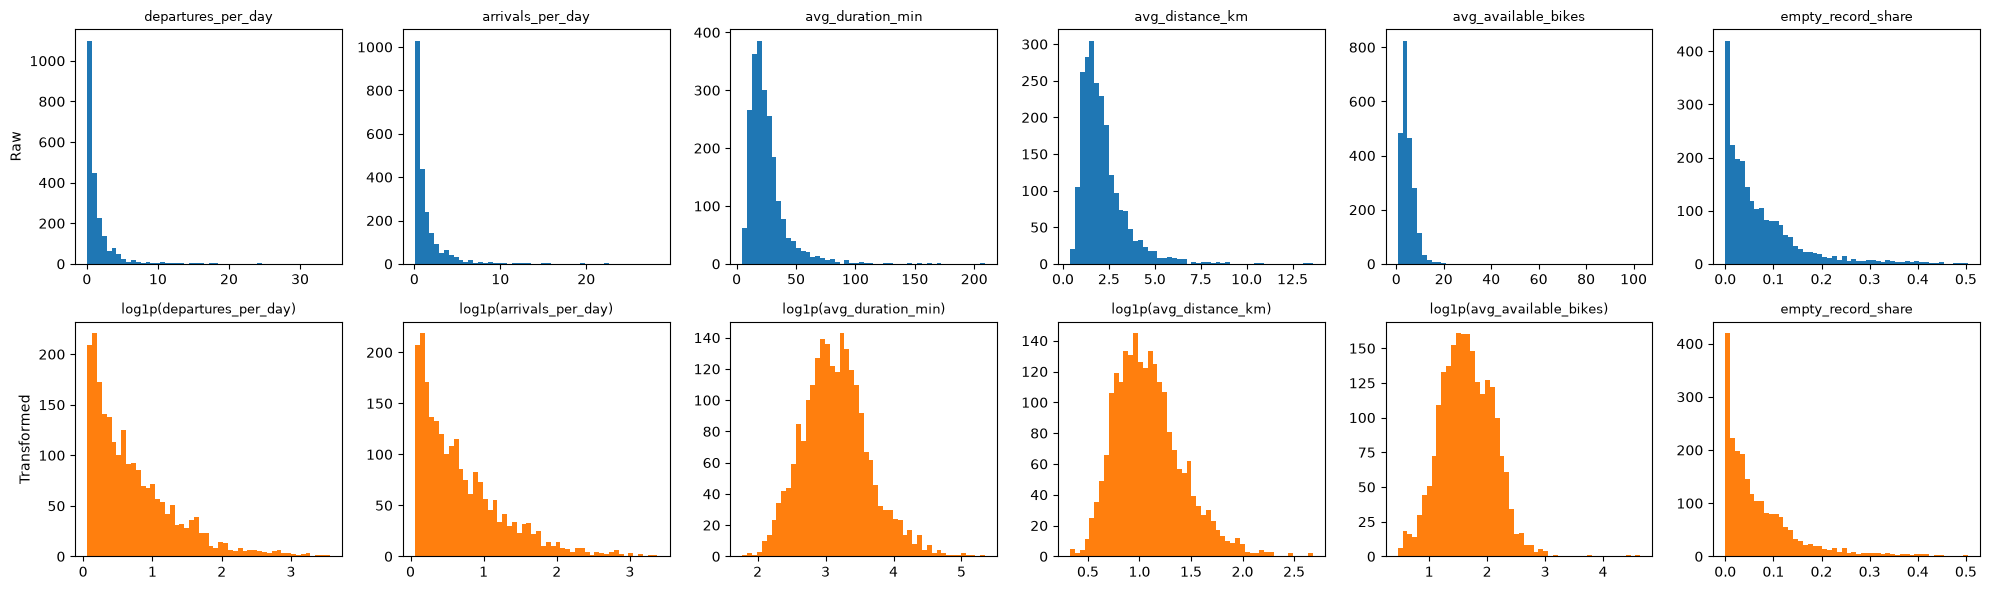

In [134]:
X_log = station_table[FEATURES].copy()
X_log[SKEWED_FEATURES] = np.log1p(X_log[SKEWED_FEATURES])

skew_check = pd.DataFrame({
    "skew_raw": station_table[FEATURES].skew(),
    "skew_after_transform": X_log.skew(),
})
display(skew_check.round(2))

fig, axes = plt.subplots(2, len(FEATURES), figsize=(20, 6))
for i, feature in enumerate(FEATURES):
    axes[0, i].hist(station_table[feature], bins=50)
    axes[0, i].set_title(feature, fontsize=9)
    axes[1, i].hist(X_log[feature], bins=50, color="tab:orange")
    axes[1, i].set_title(f"log1p({feature})" if feature in SKEWED_FEATURES else feature, fontsize=9)
axes[0, 0].set_ylabel("Raw")
axes[1, 0].set_ylabel("Transformed")
fig.tight_layout()
plt.show()

**Results.** Skewness falls from 2.5–11.7 to 0.3–1.4 for the five transformed features. `empty_record_share` keeps a skewness of 2.06, since most stations are rarely empty.

#### 13.2. PCA on Transformed Features

**Purpose.** Recompute the components on the transformed features.

The Section 8 components were fitted on untransformed values and cannot be reused. The same procedure is applied: standardization, then the smallest number of components reaching 90% cumulative explained variance.

,component,explained_share,cumulative_share
0,PC1,0.442,0.442
1,PC2,0.319,0.761
2,PC3,0.169,0.931


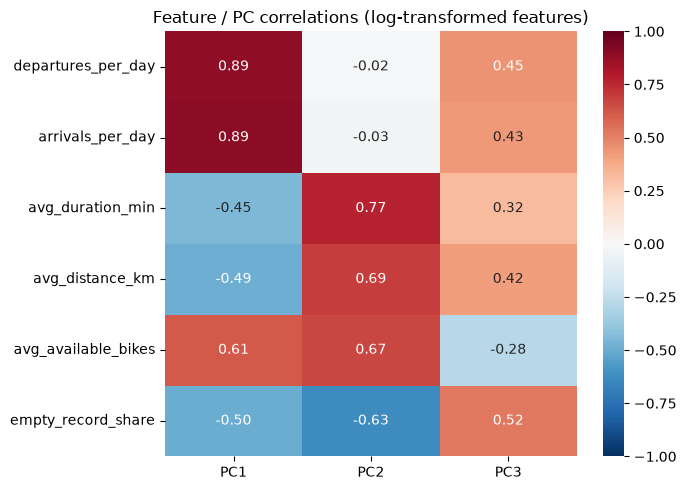

In [135]:
X_log_scaled = StandardScaler().fit_transform(X_log)
pca_log = PCA(n_components=0.90, svd_solver="full")
Z = pca_log.fit_transform(X_log_scaled)
log_pc_names = [f"PC{i + 1}" for i in range(pca_log.n_components_)]

display(pd.DataFrame({
    "component": log_pc_names,
    "explained_share": pca_log.explained_variance_ratio_,
    "cumulative_share": np.cumsum(pca_log.explained_variance_ratio_),
}).round(3))

feature_pc_corr = pd.DataFrame(
    {pc: [np.corrcoef(X_log_scaled[:, j], Z[:, i])[0, 1] for j in range(len(FEATURES))]
     for i, pc in enumerate(log_pc_names)},
    index=FEATURES,
)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(feature_pc_corr, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="RdBu_r", ax=ax)
ax.set_title("Feature / PC correlations (log-transformed features)")
fig.tight_layout()
plt.show()

**Results.** Three components explain 93.1% of the variance (44.2%, 31.9%, and 16.9%), compared with four components before the transformation.

| Component | Interpretation | Strongest correlations |
|---|---|---|
| PC1 | Station activity | departures/day (+0.89), arrivals/day (+0.89), available bikes (+0.61) |
| PC2 | Trip length and supply | duration (+0.77), distance (+0.69), available bikes (+0.67), empty records (−0.63) |
| PC3 | Shortage despite activity | empty records (+0.52), departures/day (+0.45), available bikes (−0.28) |

Departures and arrivals load almost identically on every component (r = 0.958 in Section 6.1). Activity therefore carries roughly double weight in the clustering input.

#### 13.3. Choosing the Number of Clusters

**Purpose.** Select k with several complementary criteria rather than a single score.

For k = 2 to 10, KMeans is evaluated with:
- **inertia** (within-cluster sum of squares; the elbow method),
- **silhouette** (higher means better separated clusters),
- **Davies-Bouldin index** (lower means better separated clusters),
- **stability**: KMeans is refitted on ten random 80% subsamples, and each solution is compared with the full-data solution using the Adjusted Rand Index (1 = identical partitions),
- **smallest cluster size**, to avoid groups of only a few stations.

,inertia,silhouette,davies_bouldin,stability_ari,smallest_cluster
k,,,,,
2,8723.564,0.287,1.295,0.978,847
3,6539.235,0.297,1.148,0.930,691
4,5252.103,0.298,1.052,0.938,230
5,4472.091,0.271,1.091,0.940,187
6,3970.328,0.259,1.063,0.798,174
7,3590.178,0.259,1.060,0.719,85
8,3239.169,0.268,1.019,0.703,86
9,2933.806,0.266,0.985,0.796,76
10,2702.530,0.261,1.026,0.895,65


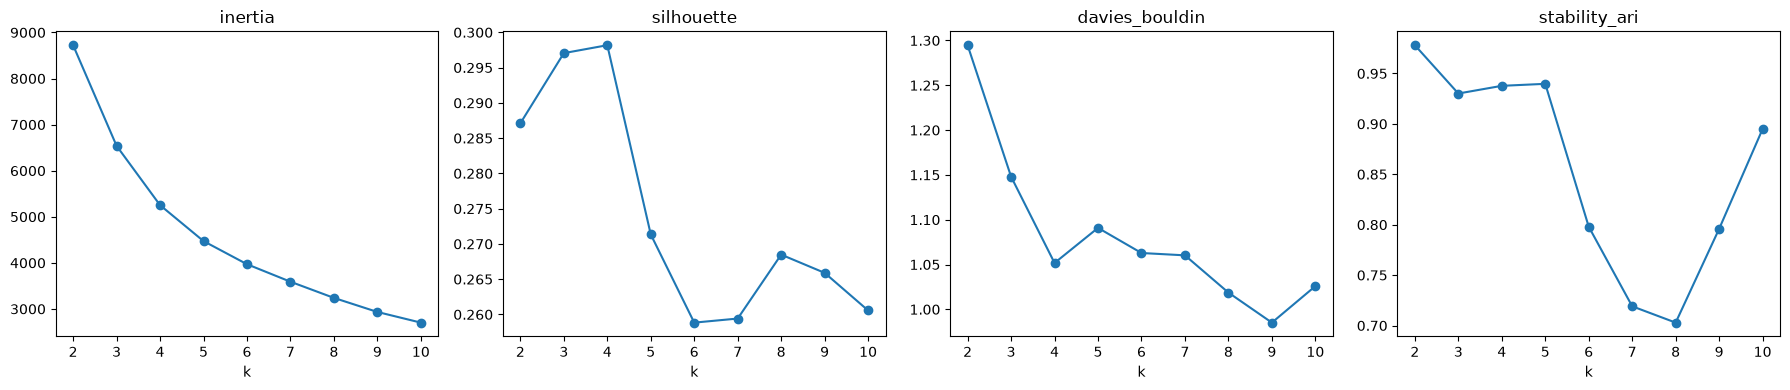

In [136]:
def kmeans_stability(data, k, n_runs=10, sample_frac=0.8):
    rng = np.random.default_rng(RANDOM_STATE)
    reference = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(data)
    scores = []
    for run in range(n_runs):
        sample = rng.choice(len(data), int(sample_frac * len(data)), replace=False)
        model = KMeans(n_clusters=k, n_init=10, random_state=run).fit(data[sample])
        scores.append(adjusted_rand_score(reference, model.predict(data)))
    return np.mean(scores)


k_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    k_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(Z, model.labels_),
        "davies_bouldin": davies_bouldin_score(Z, model.labels_),
        "stability_ari": kmeans_stability(Z, k),
        "smallest_cluster": np.bincount(model.labels_).min(),
    })
k_selection = pd.DataFrame(k_rows).set_index("k")
display(k_selection.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, ["inertia", "silhouette", "davies_bouldin", "stability_ari"]):
    ax.plot(k_selection.index, k_selection[metric], marker="o")
    ax.set_title(metric)
    ax.set_xlabel("k")
fig.tight_layout()
plt.show()

**Results.**
- Stability stays between 0.93 and 0.98 for k = 2 to 5, then falls to 0.70–0.80 for k = 6 to 9.
- Silhouette peaks at about 0.30 for k = 3 and 4 and decreases afterwards. This value indicates weak separation.
- The inertia curve has no sharp elbow.

k = 2 separates active from inactive stations only. **k = 4 is retained**: it is as stable as k = 3, has the best silhouette and a lower Davies-Bouldin index, and isolates a group of frequently empty stations that k = 3 merges with low-activity stations. Its smallest cluster still contains 230 stations.

#### 13.4. Ward Hierarchical Clustering

**Purpose.** Check the KMeans choice with an independent hierarchical method.

Ward linkage merges, at each step, the two groups whose union least increases within-cluster variance. Large jumps in merge distance suggest natural cut levels. The tree is truncated to the last 30 merges for readability.

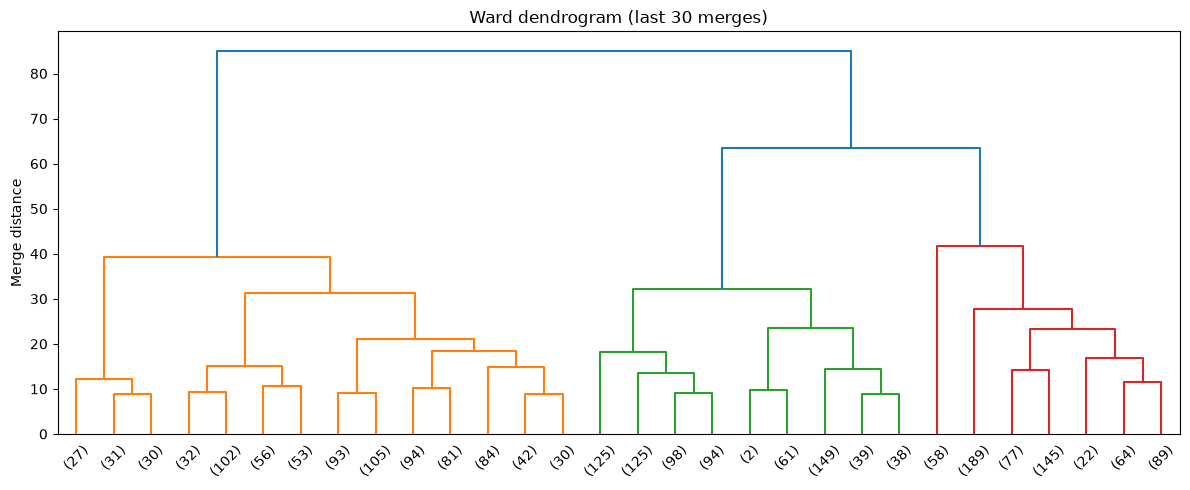

In [137]:
ward_tree = linkage(Z, method="ward")
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(ward_tree, truncate_mode="lastp", p=30, show_leaf_counts=True, ax=ax)
ax.set_title("Ward dendrogram (last 30 merges)")
ax.set_ylabel("Merge distance")
fig.tight_layout()
plt.show()

**Results.** The last merges occur at distances 85.1, 63.5, 41.6, 39.2, and 32.3. The largest gaps support two or three clusters. The 41.6 to 39.2 step is small, so the hierarchy gives no strong support for a fourth group. The choice of k = 4 rests on stability and interpretability rather than on the dendrogram.

#### 13.5. Comparison of Clustering Methods

**Purpose.** Test whether the k = 4 partition depends on the algorithm.

- **KMeans** assumes compact, roughly spherical clusters.
- **Ward** builds a hierarchy with the same variance criterion but without random initialization.
- **Gaussian Mixture Model (GMM)** allows elliptical clusters of different shapes and sizes.

Agreement between methods is measured with the ARI.

In [138]:
K = 4

kmeans_labels = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
ward_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z)
gmm_labels = GaussianMixture(n_components=K, n_init=5, random_state=RANDOM_STATE).fit_predict(Z)

method_labels = {"KMeans": kmeans_labels, "Ward": ward_labels, "GMM": gmm_labels}
display(pd.DataFrame({
    name: {
        "silhouette": silhouette_score(Z, labels),
        "davies_bouldin": davies_bouldin_score(Z, labels),
        "cluster_sizes": sorted(np.bincount(labels).tolist()),
    }
    for name, labels in method_labels.items()
}).T)
display(pd.DataFrame(
    [[adjusted_rand_score(a, b) for b in method_labels.values()] for a in method_labels.values()],
    index=method_labels.keys(), columns=method_labels.keys(),
).round(2))

,silhouette,davies_bouldin,cluster_sizes
KMeans,0.298178,1.051713,"[230, 515, 682, 808]"
Ward,0.27084,0.978682,"[58, 586, 731, 860]"
GMM,0.179055,1.561442,"[225, 461, 695, 854]"


,KMeans,Ward,GMM
KMeans,1.00,0.44,0.21
Ward,0.44,1.00,0.25
GMM,0.21,0.25,1.00


**Results.**

| Method | Silhouette | Davies-Bouldin | Cluster sizes |
|---|---|---|---|
| KMeans | 0.298 | 1.05 | 230, 515, 682, 808 |
| Ward | 0.271 | 0.98 | 58, 586, 731, 860 |
| GMM | 0.179 | 1.56 | 225, 461, 695, 854 |

Pairwise ARI is 0.44 between KMeans and Ward, 0.21 between KMeans and GMM, and 0.25 between Ward and GMM.

**Insights.** The methods agree only partly. Combined with silhouettes below 0.30, this indicates that stations do not form clearly separated natural types. They vary along continuous gradients of activity, trip length, and supply. The clusters are therefore a useful segmentation of this continuum, not distinct station categories. KMeans labels are retained for interpretation because they are the most stable and best separated.

#### 13.6. Cluster Profiles

**Purpose.** Describe each cluster in original units.

Profiles use the untransformed features. Medians and boxplots are reported instead of means because Section 10 showed that group means can be driven by a few extreme stations.

,stations,departures_per_day,arrivals_per_day,avg_duration_min,avg_distance_km,avg_available_bikes,empty_record_share
cluster,,,,,,,
0,808,0.762,0.740,16.356,1.360,3.355,0.068
1,515,3.478,3.219,19.881,1.646,6.405,0.023
2,230,0.238,0.230,24.456,2.367,1.556,0.239
3,682,0.378,0.364,33.170,2.809,4.668,0.028


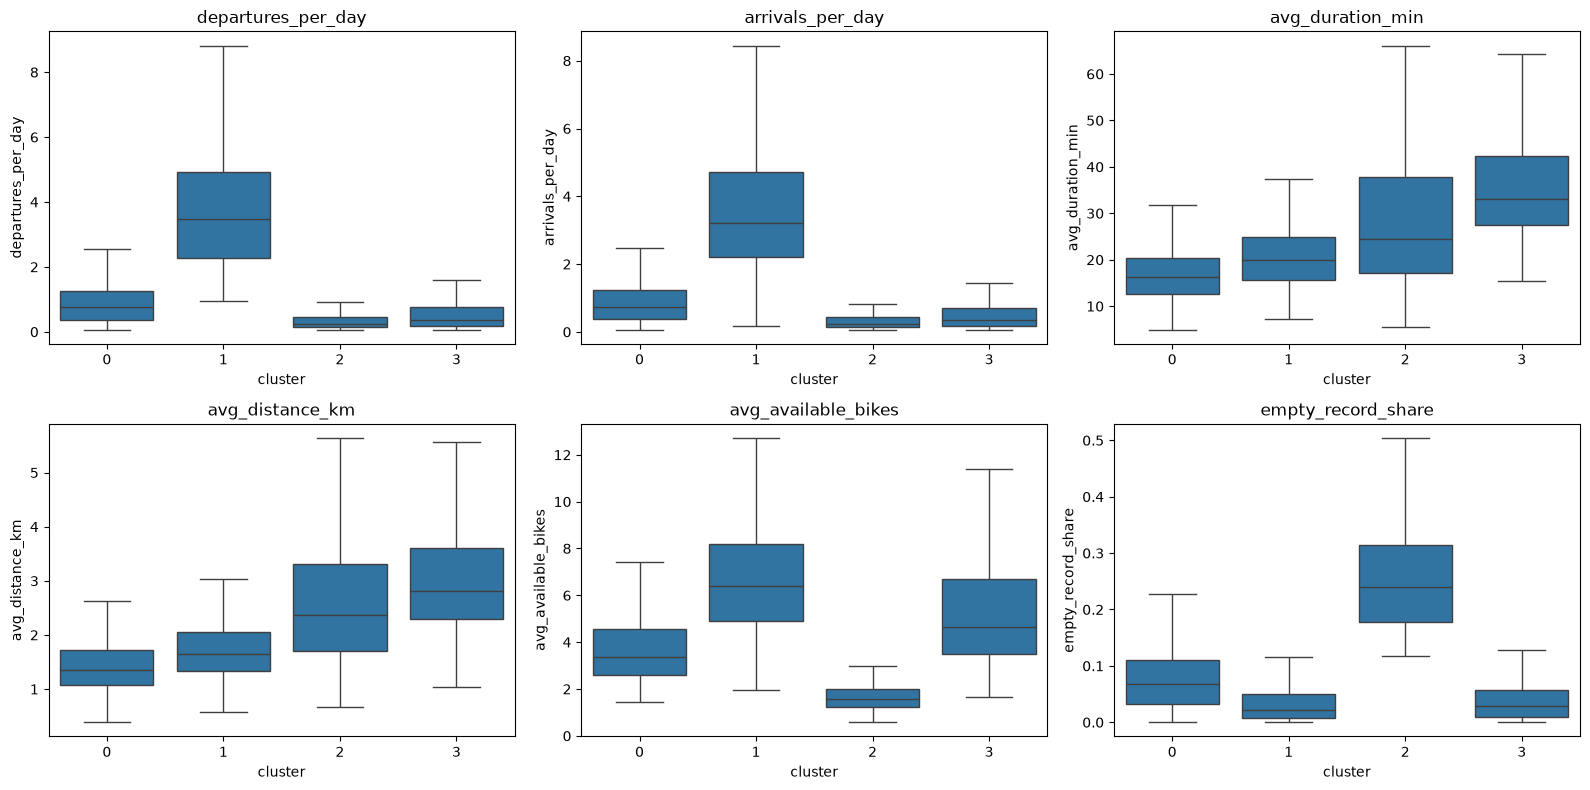

In [139]:
station_table["cluster"] = kmeans_labels

cluster_profiles = station_table.groupby("cluster")[FEATURES].median()
cluster_profiles.insert(0, "stations", station_table.groupby("cluster").size())
display(cluster_profiles.round(3))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.boxplot(data=station_table, x="cluster", y=feature, ax=ax, showfliers=False)
    ax.set_title(feature)
fig.tight_layout()
plt.show()

**Results.** Median feature values per cluster:

| Cluster | Stations | Departures/day | Duration (min) | Distance (km) | Available bikes | Empty records | Proposed profile |
|---|---|---|---|---|---|---|---|
| 1 | 515 | 3.48 | 19.9 | 1.65 | 6.40 | 2% | **Busy hubs** |
| 0 | 808 | 0.76 | 16.4 | 1.36 | 3.35 | 7% | **Short-hop local stations** |
| 3 | 682 | 0.38 | 33.2 | 2.81 | 4.67 | 3% | **Long-trip, low-use stations** |
| 2 | 230 | 0.24 | 24.5 | 2.37 | 1.56 | 24% | **Undersupplied stations** |

**Insights.**
- **Busy hubs** have about 4.6 times the median activity of the next cluster, yet are rarely empty. Their high supply suggests either larger capacity or active rebalancing.
- **Short-hop local stations** have the shortest trips (16 min, 1.4 km). This fits utilitarian, last-mile use.
- **Long-trip, low-use stations** have trips twice as long (33 min, 2.8 km) and are well stocked. This suggests leisure or peripheral locations where bikes are rarely taken.
- **Undersupplied stations** hold 1.6 bikes on median and are empty in about one record out of four, despite the lowest activity. Low use here may partly result from lack of bikes rather than lack of demand. These stations are the clearest targets for rebalancing.
- The arrival/departure ratio is between 0.93 and 0.97 in every cluster. Net flow does not distinguish the groups, partly because arrivals are undercounted (Section 4).

#### 13.7. Clusters in PCA and Geographic Space

**Purpose.** Visualise cluster separation and spatial distribution.

The left panel shows stations in the plane of the first two components, which hold 76% of the variance. The right panel shows station coordinates coloured by cluster.

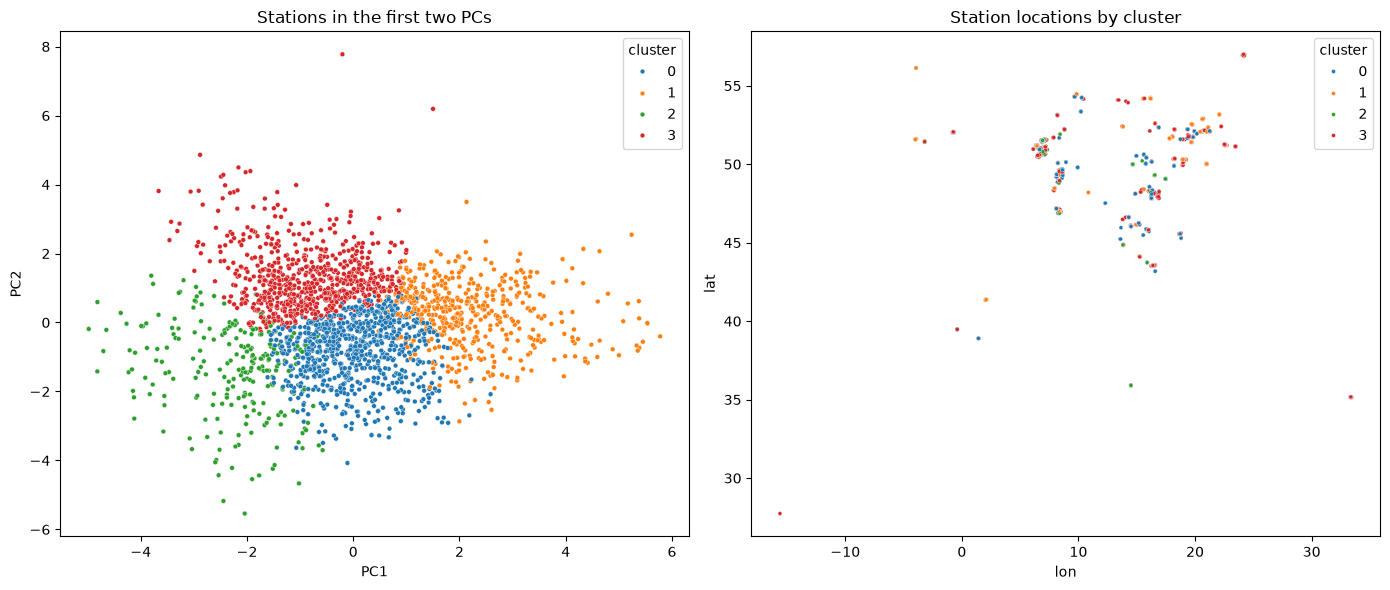

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=station_table["cluster"], palette="tab10", s=12, ax=axes[0])
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("Stations in the first two PCs")
sns.scatterplot(data=station_table, x="lon", y="lat", hue="cluster", palette="tab10", s=8, ax=axes[1])
axes[1].set_title("Station locations by cluster")
fig.tight_layout()
plt.show()

#### 13.8. Cluster Composition by Country and System

**Purpose.** Check whether clusters describe station roles or simply reflect the country or system a station belongs to.

The country table gives the share of each country's stations in each cluster. For systems with at least 10 selected stations, `dominant_share` is the proportion of stations falling in the system's most frequent cluster.

In [141]:
country_mix = pd.crosstab(station_table["country"], station_table["cluster"], normalize="index")
country_mix.insert(0, "stations", station_table["country"].value_counts())
display(country_mix.sort_values("stations", ascending=False).round(2))

system_mix = pd.crosstab(station_table["system_name"], station_table["cluster"])
system_mix["stations"] = system_mix.sum(axis=1)
system_mix["dominant_share"] = system_mix.drop(columns="stations").max(axis=1) / system_mix["stations"]
display(system_mix.loc[system_mix["stations"] >= 10].sort_values("stations", ascending=False).head(20).round(2))

cluster,stations,0,1,2,3
country,,,,,
DE,719,0.41,0.13,0.17,0.29
PL,590,0.19,0.48,0.01,0.33
CZ,210,0.71,0.07,0.18,0.04
AT,197,0.42,0.09,0.03,0.46
CH,170,0.49,0.08,0.08,0.35
HR,108,0.30,0.29,0.06,0.35
GB,67,0.21,0.33,0.16,0.30
ES,51,0.33,0.55,0.02,0.10
SI,48,0.27,0.29,0.17,0.27


cluster,0,1,2,3,stations,dominant_share
system_name,,,,,,
Lublin,12,80,0,27,119,0.67
Mobic,36,4,19,41,100,0.41
Pardubice,43,1,8,2,54,0.80
Milton Keynes,13,11,4,17,45,0.38
Klagenfurt,11,5,0,29,45,0.64
Chorzów,19,14,0,10,43,0.44
Mödling,26,1,3,12,42,0.62
Uherské Hradiště,30,2,8,1,41,0.73
Sursee Plus,22,6,1,11,40,0.55


**Results.**
- Busy hubs are over-represented in Poland (48% of Polish stations) and Spain (55%), against 23% overall. In Lublin, 80 of 119 stations are busy hubs.
- In Rīga (Latvia), 82% of stations are long-trip, low-use stations. In Czechia, 71% are short-hop local stations.
- Undersupplied stations concentrate in some e-bike systems: 25 of 36 stations in RVK e-Bike and 20 of 30 in Bergisches e-Bike.
- Several systems are mixed: Ljubljana, Mülheim, and Milton Keynes have no cluster above 40%.

**Insights.** Clusters partly reflect system-level factors such as fleet size, pricing, rebalancing policy, or bike type, and not only the role of each station. The concentration of undersupplied stations in e-bike systems may relate to charging constraints, which could be checked against `bike_types`.

#### 13.9. Export

**Purpose.** Save one cluster label per station so that station profiles can be compared with the trip clusters from Part A.

In [142]:
station_table[["station_id", "cluster"]].to_csv(PART_B_DIR / "station_clusters.csv", index=False)

### 14. Findings and Limitations

**Main findings.** After a log transformation, four stable station profiles emerge: busy hubs, short-hop local stations, long-trip low-use stations, and undersupplied stations. The undersupplied group (230 stations, empty in 24% of records) is the most directly useful for operations, because it identifies where bikes are missing rather than where demand is low. Country and system strongly shape cluster membership.

**Limitations.**
- Separation is weak (silhouette ≤ 0.30) and methods agree only partly (ARI 0.21–0.44). The profiles describe a continuum rather than distinct types.
- Departures and arrivals are almost redundant, giving activity double weight.
- Features are averaged over the whole period. They do not capture daily or weekly rhythms, which would better separate residential, commercial, and leisure stations.
- The selection in Section 6 excludes stations with little data, which removes part of the low-activity range.
- Station capacity is not used, so low supply cannot be distinguished from small stations.

**Further analysis.** Add hourly departure and arrival profiles (morning vs evening peaks), include capacity, and cross the station clusters with the Part A trip clusters.

In [143]:
# Start this part with a clean memory and the default plot style, as if it was its own notebook
%reset -f
import matplotlib.pyplot as plt
plt.rcdefaults()

# 3. Supervised Task: Predict Station Availability

The goal is predict a station's `bikes_available_to_rent` one hour into the future, so operators can plan bike transfers between stations.

**Structure:**

0. Data loading
1. Exploration
2. Target construction
3. Train / Test temporal split
4. Features (internal and external)
5. Baseline
6. Models: XGBoost and LightGBM
7. Evaluation on test
8. Evaluation - New dataset
9. Conclusions and limitations

### 0. Data loading

In [144]:
import os
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
import xgboost as xgb

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)

ROOT = os.getcwd()
if os.path.basename(ROOT) == "notebooks":  # works from the project root or from notebooks/
    ROOT = os.path.dirname(ROOT)

In [145]:
status = pd.read_csv(ROOT + "/data_cleaned/stations_status_clean.csv")
stations = pd.read_csv(ROOT + "/data_cleaned/cleaned_stations.csv")
cities = pd.read_csv(ROOT + "/data_cleaned/cities_clean.csv")

In [146]:
status["time"] = pd.to_datetime(status["time"], utc=True)
status["local_time"] = pd.to_datetime(status["local_time"])
status = status.sort_values(["station_id", "time"]).reset_index(drop=True)

In [147]:
print(f"status:   {status.shape}")
print(f"stations: {stations.shape}")
print(f"cities:   {cities.shape}")
status.head()

status:   (2925807, 13)
stations: (2900, 8)
cities:   (267, 7)


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,maint_change,timezone,local_time,hour,availability_mismatch
0,94,2022-08-29 13:12:01+00:00,5,0,5,0,0,False,NaN,Europe/Berlin,2022-08-29 15:12:01,15,False
1,94,2022-08-29 13:13:01+00:00,4,0,4,0,0,False,0.0,Europe/Berlin,2022-08-29 15:13:01,15,False
2,94,2022-08-30 13:30:01+00:00,5,0,5,0,0,False,0.0,Europe/Berlin,2022-08-30 15:30:01,15,False
3,94,2022-08-31 17:57:01+00:00,4,0,4,0,0,False,0.0,Europe/Berlin,2022-08-31 19:57:01,19,False
4,94,2022-08-31 18:05:01+00:00,5,0,5,0,0,False,0.0,Europe/Berlin,2022-08-31 20:05:01,20,False


---
### 1. Exploring `station_status`

Before building the problem, we need to understand how often a station's state is recorded. If it were a regular time series (one row every X minutes), it would be enough to look for the row closest to `t + 1h`.

In [148]:
# Time between two consecutive records of the same station
gap_min = status.groupby("station_id")["time"].diff().dt.total_seconds() / 60

print("Quantiles of the gap between events (minutes):")
print(gap_min.quantile([.10, .25, .50, .60, .75, .90, .99]).round(1))
print(f"\nGaps <= 5 min : {(gap_min <= 5).mean():.1%}")
print(f"Gaps <= 60 min: {(gap_min <= 60).mean():.1%}")

Quantiles of the gap between events (minutes):
0.10       1.0
0.25       4.0
0.50      28.0
0.60      54.0
0.75     158.0
0.90     722.0
0.99    4704.0
Name: time, dtype: float64

Gaps <= 5 min : 27.2%
Gaps <= 60 min: 61.6%


In [149]:
# Is every row a real state change? This represents how much that value changed vs the previous event of the same station
changes = status.groupby("station_id")[
    ["bikes_available_to_rent", "bikes", "booked_bikes", "free_racks", "free_special_racks"]
].diff().fillna(0)

In [150]:
changes.head()

,bikes_available_to_rent,bikes,booked_bikes,free_racks,free_special_racks
0,0.0,0.0,0.0,0.0,0.0
1,-1.0,-1.0,0.0,0.0,0.0
2,1.0,1.0,0.0,0.0,0.0
3,-1.0,-1.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.0,0.0


In [151]:
changes.describe()

,bikes_available_to_rent,bikes,booked_bikes,free_racks,free_special_racks
count,2.925807e+06,2.925807e+06,2.925807e+06,2.925807e+06,2.925807e+06
mean,-3.141014e-04,-3.328996e-04,-1.879823e-05,1.643991e-04,-1.124476e-04
std,1.257686e+00,1.245620e+00,2.636697e-01,9.650654e-01,6.402896e-01
min,-9.000000e+01,-9.000000e+01,-1.200000e+01,-2.900000e+01,-2.900000e+01
25%,-1.000000e+00,-1.000000e+00,0.000000e+00,-1.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
max,8.900000e+01,8.900000e+01,1.000000e+01,2.900000e+01,2.900000e+01


In [152]:
changes["bikes_available_to_rent"].value_counts(normalize=True)*100

bikes_available_to_rent
-1.0     41.523552
 1.0     40.760344
 0.0      7.562358
 2.0      3.988985
-2.0      3.861977
           ...    
 89.0     0.000034
-90.0     0.000034
-29.0     0.000034
 26.0     0.000034
-48.0     0.000034
Name: proportion, Length: 65, dtype: float64

- The mean of each column is ~0 (changes cancel out: it goes up and down equally), and there's an 89.84% chance that when an event is recorded, it's because 1 bike was added or removed at the station, or because it stayed the same (another parameter changed instead).
- There are extreme cases (min -90, max 89) that are almost certainly bulk rentals or bike rebalancing.

In [153]:
target_changed = changes["bikes_available_to_rent"] != 0
something_changed = (changes != 0).any(axis=1)

print(f"Rows that change bikes_available_to_rent    : {target_changed.mean():.1%}")
print(f"Of those that DON'T change it, something else changes: {something_changed[~target_changed].mean():.1%}")
print(f"Rows where only the time changes, nothing else: {(~something_changed).sum():,}")

Rows that change bikes_available_to_rent    : 92.4%
Of those that DON'T change it, something else changes: 98.5%
Rows where only the time changes, nothing else: 3,300


- `station_status`: It's an event log, not a regular series. We can see it because the time between two rows of the same station varies a lot (from 1 minute to several days), and almost every time a row appears it's because something changed (92.4% of the time `bikes_available_to_rent` changes).

#### 1.1 Gaps in the stations' status log

In [154]:
all_times = np.sort(status["time"].unique())
gaps = np.diff(all_times)

big_gaps = np.where(gaps > np.timedelta64(90, "m"))[0]
outages = pd.DataFrame({
    "start": all_times[big_gaps],
    "end": all_times[big_gaps + 1],
})
outages["hours"] = (outages["end"] - outages["start"]) / np.timedelta64(1, "h")
outages = outages.sort_values("hours", ascending=False).reset_index(drop=True)
outages

,start,end,hours
0,2023-05-05 09:59:01+00:00,2023-05-17 08:21:01+00:00,286.366667
1,2022-09-17 14:59:01+00:00,2022-09-19 12:00:01+00:00,45.016667
2,2022-10-17 12:59:01+00:00,2022-10-18 12:27:01+00:00,23.466667
3,2023-06-26 18:43:01+00:00,2023-06-27 07:41:00+00:00,12.966389
4,2023-03-09 05:15:01+00:00,2023-03-09 13:06:01+00:00,7.850000


The longest outage goes from 2023-05-05 09:59:01+00:00 to 2023-05-17 08:21:01+00:00 (286 hours)

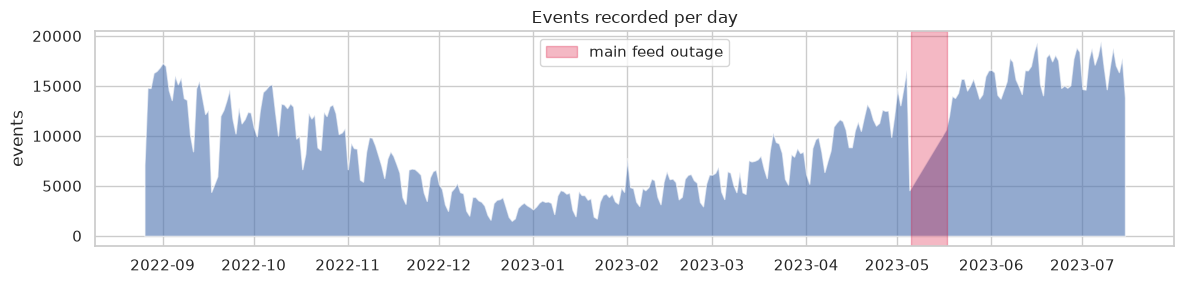

In [155]:
outage_start = outages.loc[0, "start"]
outage_end = outages.loc[0, "end"]

events_per_day = status.groupby(status["time"].dt.date).size()
fig, ax = plt.subplots(figsize=(12, 3))
ax.fill_between(pd.to_datetime(events_per_day.index), events_per_day.values, alpha=.6)
ax.axvspan(outage_start, outage_end, color="crimson", alpha=.3, label="main feed outage")
ax.set(title="Events recorded per day", xlabel="", ylabel="events")
ax.legend()
plt.tight_layout()

---
### 2. Target construction

The goal is to predict a station's `bikes_available_to_rent` one hour into the future, but we don't always have the 't + 1h' value for record 't' to train our model with.

However, from our analysis we saw that the system has a 92.4% chance that when a new record appears, it means `bikes_available_to_rent` changed, and a 98.5% chance that some other variable changed.

So, based on this, to build a dataset capable of predicting bike availability within 1h, we'll create a 't + 1h' record for each 't' record, based on the LOCF (*last observation carried forward*) method.

In [156]:
anchors = status[["station_id", "time", "bikes_available_to_rent"]].copy()
anchors = anchors.rename(columns={"bikes_available_to_rent": "y_now"})
anchors["target_time"] = anchors["time"] + pd.Timedelta(hours=1)

# "Future" table: same content as status, to look up the value at t+1h
future = status[["station_id", "time", "bikes_available_to_rent"]].rename(
    columns={"time": "obs_time", "bikes_available_to_rent": "y"}
).sort_values("obs_time")

anchors = anchors.sort_values("target_time")

# We compute the station's last real event at or right before the hour we want to predict
anchors = pd.merge_asof(
    anchors, future,
    left_on="target_time", right_on="obs_time",
    by="station_id", direction="backward",   # <- the last event BEFORE target_time
)
anchors["delta"] = anchors["y"] - anchors["y_now"]

print(f"target coverage: {anchors['y'].notna().mean():.2%}")
anchors.head()

target coverage: 100.00%


,station_id,time,y_now,target_time,obs_time,y,delta
0,286240,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,0,0
1,724351,2022-08-26 14:48:01+00:00,14,2022-08-26 15:48:01+00:00,2022-08-26 15:45:01+00:00,18,4
2,9799774,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 15:38:01+00:00,3,3
3,10213304,2022-08-26 14:48:01+00:00,4,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,4,0
4,33279179,2022-08-26 14:48:01+00:00,19,2022-08-26 15:48:01+00:00,2022-08-26 15:40:01+00:00,18,-1


In [157]:
100*anchors[anchors["y_now"]==anchors["y"]].shape[0]/anchors.shape[0]

53.04536491983237

In [158]:
# The target "y" was built with LOCF: if there's no event, we assume the station
# didn't change. How many of those labels rely on there being NO event at all during
# the next hour (pure silence), instead of being confirmed by a real event?
no_evidence = anchors["obs_time"] == anchors["time"]
print(f"anchors with no event at all in the following hour: {no_evidence.mean():.1%}")

anchors with no event at all in the following hour: 38.4%


In [159]:
# For those anchors, how long does it take for that station's NEXT real event to show up
# (even if it's after the hour we're predicting)? That tells us how long the silence
# actually is in practice.
status["next_event"] = status.groupby("station_id")["time"].shift(-1)
status["next_wait_min"] = (status["next_event"] - status["time"]).dt.total_seconds() / 60

wait = anchors.merge(
    status[["station_id", "time", "next_wait_min"]], on=["station_id", "time"], how="left"
).loc[no_evidence.to_numpy(), "next_wait_min"]

print("Of that 38%, the values aren't always filled in with something within the 1h \n" \
"look-back window; 38.4% get filled with a value from more than 1 hour ago:")
print((wait / 60).quantile([.25, .5, .75, .9, .99]).round(1))

Of that 38%, the values aren't always filled in with something within the 1h 
look-back window; 38.4% get filled with a value from more than 1 hour ago:
0.25      2.0
0.50      4.5
0.75     12.6
0.90     25.7
0.99    159.1
Name: next_wait_min, dtype: float64


We assume that if there's no event, the state didn't change — we can't verify this 100%, but it's reasonable because we already saw that the system records an event almost every time something changes (92.4%), so the absence of an event is the best clue we have that the station stayed the same.

#### 2.1 Cleaning

In [160]:
# Case 1: Remove the multi-day gap between the stations' logs
in_outage = (anchors["target_time"] > outage_start) & (anchors["time"] < outage_end)

In [161]:
# Case 2: The station's last record won't have a t+1h.
last_event = status.groupby("station_id")["time"].max()
anchors["station_last_event"] = anchors["station_id"].map(last_event)
past_end = anchors["target_time"] > anchors["station_last_event"]

In [162]:
anchors["is_valid"] = ~(in_outage | past_end)
print(f"valid anchors: {anchors['is_valid'].mean():.2%}")

anchors = anchors[anchors["is_valid"]].drop(columns=["station_last_event", "is_valid"]).reset_index(drop=True)

valid anchors: 99.81%


P(delta == 0) = 53.02%


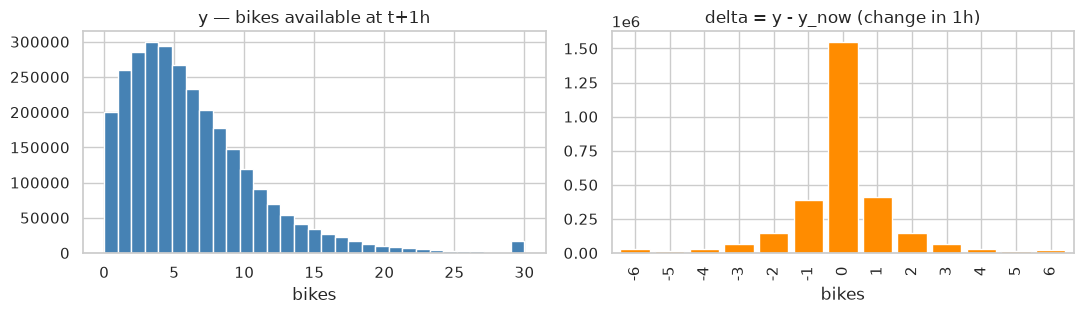

In [163]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
anchors["y"].clip(0, 30).hist(bins=31, ax=axes[0], color="steelblue")
axes[0].set(title="y — bikes available at t+1h", xlabel="bikes")

anchors["delta"].clip(-6, 6).value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange", width=.85)
axes[1].set(title="delta = y - y_now (change in 1h)", xlabel="bikes")
plt.tight_layout()

print(f"P(delta == 0) = {(anchors['delta'] == 0).mean():.2%}")

- The distribution of `delta` has almost half its mass at 0, which means that half the time nothing happens in an hour, so predicting no change at all is already right half the time. That's why we consider a persistence baseline model, i.e. one that doesn't change anything — bike availability stays the same as before.

- We'll use `delta` as the target instead of `y`, because that way the model focuses only on the change, instead of also having to rediscover the current value, which we already have (it's `y_now`). Also, if the model predicts delta=0 all the time, that's literally the same as persistence, so comparing against it is direct.

---
### 3. TRAIN/TEST Split

We split train (~75%) and test (~25%) respecting temporal order, and we also make sure to avoid data leaking into the future, leaving a 48h gap between train and test, since we have lag_24h variables that pull in past information.

In [164]:
TRAIN_END = pd.Timestamp("2023-06-01", tz="UTC")
TEST_START = pd.Timestamp("2023-06-03", tz="UTC")

conditions = [anchors["time"] < TRAIN_END, anchors["time"] >= TEST_START]
anchors["split"] = np.select(conditions, ["train", "test"], default="discarded")

anchors["split"].value_counts(normalize=True)*100

split
train        74.627292
test         24.243310
discarded     1.129397
Name: proportion, dtype: float64

---
### 4. Features

In [165]:
# 4.1 Current state of the row (already in status)
state_cols = ["bikes", "booked_bikes", "free_racks", "free_special_racks", "maintenance",
              "hour", "local_time"]
anchors = anchors.merge(status[["station_id", "time"] + state_cols], on=["station_id", "time"], how="left")

anchors["capacity"] = anchors["bikes"] + anchors["free_racks"]
anchors["fill_ratio"] = anchors["y_now"] / anchors["capacity"].replace(0, np.nan)
anchors["maintenance"] = anchors["maintenance"].astype(int)

anchors["dayofweek"] = anchors["local_time"].dt.dayofweek
anchors["is_weekend"] = (anchors["dayofweek"] >= 5).astype(int)

In [166]:
# 4.2 Minutes since the last event
# Strong signal: a station that just had activity is more likely to keep
# changing; one that's been quiet for hours is probably still the same.
status["minutes_since_last"] = status.groupby("station_id")["time"].diff().dt.total_seconds() / 60
anchors = anchors.merge(
    status[["station_id", "time", "minutes_since_last"]],
    on=["station_id", "time"], how="left",
)
anchors["minutes_since_last"] = anchors["minutes_since_last"].fillna(0)

In [167]:
# 4.3 Past values (lags)
# Same LOCF trick as for the target, but looking backward instead of forward: "what value did the station have X hours ago?"
def value_n_hours_ago(anchors, log, hours):
    probe = anchors[["station_id", "time"]].reset_index(drop=True).copy()
    probe["original_order"] = np.arange(len(probe))
    probe["query_time"] = probe["time"] - pd.Timedelta(hours=hours)
    probe = probe.sort_values("query_time")

    short_log = log[["station_id", "time", "bikes_available_to_rent"]].rename(columns={"time": "obs_time"}).sort_values("obs_time")
    merged = pd.merge_asof(
        probe, short_log,
        left_on="query_time", right_on="obs_time",
        by="station_id", direction="backward",
    )
    merged = merged.sort_values("original_order")
    return merged["bikes_available_to_rent"].to_numpy()


anchors["lag_1h"] = value_n_hours_ago(anchors, status, 1)
anchors["lag_3h"] = value_n_hours_ago(anchors, status, 3)
anchors["lag_24h"] = value_n_hours_ago(anchors, status, 24)

# If there isn't enough history (anchors too early on), we assume nothing had changed.
for c in ["lag_1h", "lag_3h", "lag_24h"]:
    anchors[c] = anchors[c].fillna(anchors["y_now"])

In [168]:
# 4.4 Station's own data
anchors = anchors.merge(
    stations[["id", "bike_racks", "special_racks"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)

#### 4.5 Cyclical variables

`hour` and `dayofweek` aren't normal numbers: after hour 23 comes 0 (they're not
"far apart"), and after day 6 (Sunday) comes 0 (Monday). If we leave them as they are, the
model sees hour 23 and hour 0 as opposite extremes, when in reality they're almost the same
(both late at night). Turning them into sine and cosine gives that closeness explicitly, without
inventing any new data — it's just another way of representing the same thing.

In [169]:
anchors["hour_sin"] = np.sin(2 * np.pi * anchors["hour"] / 24)
anchors["dayofweek_sin"] = np.sin(2 * np.pi * anchors["dayofweek"] / 7)

In [170]:
anchors.head()

,station_id,time,y_now,target_time,obs_time,y,delta,split,bikes,booked_bikes,...,dayofweek,is_weekend,minutes_since_last,lag_1h,lag_3h,lag_24h,bike_racks,special_racks,hour_sin,dayofweek_sin
0,286240,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,0,0,train,0,0,...,4,0,0.0,0.0,0.0,0.0,0.0,0.0,-0.866025,-0.433884
1,724351,2022-08-26 14:48:01+00:00,14,2022-08-26 15:48:01+00:00,2022-08-26 15:45:01+00:00,18,4,train,14,0,...,4,0,0.0,14.0,14.0,14.0,22.0,0.0,-0.707107,-0.433884
2,9799774,2022-08-26 14:48:01+00:00,0,2022-08-26 15:48:01+00:00,2022-08-26 15:38:01+00:00,3,3,train,0,0,...,4,0,0.0,0.0,0.0,0.0,15.0,0.0,-0.866025,-0.433884
3,10213304,2022-08-26 14:48:01+00:00,4,2022-08-26 15:48:01+00:00,2022-08-26 14:48:01+00:00,4,0,train,4,0,...,4,0,0.0,4.0,4.0,4.0,12.0,0.0,-0.866025,-0.433884
4,33279179,2022-08-26 14:48:01+00:00,19,2022-08-26 15:48:01+00:00,2022-08-26 15:40:01+00:00,18,-1,train,19,0,...,4,0,0.0,19.0,19.0,19.0,15.0,0.0,-0.866025,-0.433884


#### 4.6 Weather (Open-Meteo)

Open-Meteo offers two different APIs, and the difference matters so we don't fool ourselves with
data leakage:

- **Archive API** (the one we use): ERA5 historical reanalysis — the weather that **actually
  happened** at each hour and city. It's reliable observational data, not a forecast.
- **Forecast API**: real forecasts, but only from "today" onward. It can't
  retroactively reconstruct "what would have been forecast" for a past date in 2023.

Since this project is a *backtest* over historical data, **we only use the weather at the anchor's
instant `t`**, never at `t+1h`. Using the one at `t+1h` would have meant treating data that already
happened as if it were a forecast — an approximation that works reasonably well 1 hour ahead, but
that isn't honest to present as a genuine forecast. Avoiding it removes any ambiguity about data
leakage.

In [171]:
# The station carries city_id in stations.csv; we use that to join its city's weather.
anchors = anchors.merge(
    stations[["id", "city_id"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)

weather_path = ROOT + "/data_external/weather_city.csv"

if os.path.exists(weather_path):
    weather = pd.read_csv(weather_path, parse_dates=["weather_time"])
    print("weather loaded from local cache")
else:
    print("weather cache doesn't exist, downloading from Open-Meteo...")
    cities_with_station = cities[cities["id"].isin(stations["city_id"].unique())].drop_duplicates("id")

    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": ",".join(cities_with_station["lat"].astype(str)),
        "longitude": ",".join(cities_with_station["lon"].astype(str)),
        "start_date": "2022-08-20",
        "end_date": "2023-07-20",
        "hourly": "temperature_2m,precipitation",
        "timezone": "UTC",
    }

    # Open-Meteo sometimes responds with 429 (too many requests); we retry after a short wait.
    for attempt in range(5):
        resp = requests.get(url, params=params, timeout=60)
        if resp.status_code != 429:
            break
        print(f"429 received, waiting before retrying (attempt {attempt + 1}/5)...")
        time.sleep(30)
    resp.raise_for_status()
    data = resp.json()   # one entry per city, in the same order as cities_with_station

    parts = []
    for city_id, block in zip(cities_with_station["id"], data):
        parts.append(pd.DataFrame({
            "city_id": city_id,
            "weather_time": pd.to_datetime(block["hourly"]["time"], utc=True),
            "wx_temp": block["hourly"]["temperature_2m"],
            "wx_precip": block["hourly"]["precipitation"],
        }))
    weather = pd.concat(parts, ignore_index=True)

    os.makedirs(ROOT + "/data_external", exist_ok=True)
    weather.to_csv(weather_path, index=False)
    print(f"weather downloaded and saved to {weather_path} so we don't repeat the download")

# Weather is at hourly resolution; we round the anchor's instant down to the exact
# hour (both in UTC) so we can join by (city_id, hour).
anchors["hour_utc"] = anchors["time"].dt.floor("h")
anchors = anchors.merge(
    weather[["city_id", "weather_time", "wx_temp", "wx_precip"]].rename(columns={"weather_time": "hour_utc"}),
    on=["city_id", "hour_utc"], how="left",
)

print(f"anchors without weather (no city or out of range): {anchors['wx_temp'].isna().mean():.2%}")
anchors[["station_id", "time", "city_id", "wx_temp", "wx_precip"]].head()

weather loaded from local cache


anchors without weather (no city or out of range): 0.76%


,station_id,time,city_id,wx_temp,wx_precip
0,286240,2022-08-26 14:48:01+00:00,88.0,23.1,0.6
1,724351,2022-08-26 14:48:01+00:00,320.0,22.0,0.0
2,9799774,2022-08-26 14:48:01+00:00,551.0,30.7,0.0
3,10213304,2022-08-26 14:48:01+00:00,570.0,29.6,0.0
4,33279179,2022-08-26 14:48:01+00:00,639.0,29.3,0.0


These correspond to the ones without a city_id, which we'll remove later on

In [172]:
anchors.isna().sum().sort_values(ascending=False)

fill_ratio            51130
bike_racks            22129
special_racks         22129
wx_precip             22129
city_id               22129
wx_temp               22129
station_id                0
split                     0
bikes                     0
time                      0
y_now                     0
target_time               0
obs_time                  0
y                         0
delta                     0
local_time                0
hour                      0
maintenance               0
free_special_racks        0
free_racks                0
booked_bikes              0
dayofweek                 0
capacity                  0
lag_24h                   0
lag_3h                    0
lag_1h                    0
minutes_since_last        0
is_weekend                0
hour_sin                  0
dayofweek_sin             0
hour_utc                  0
dtype: int64

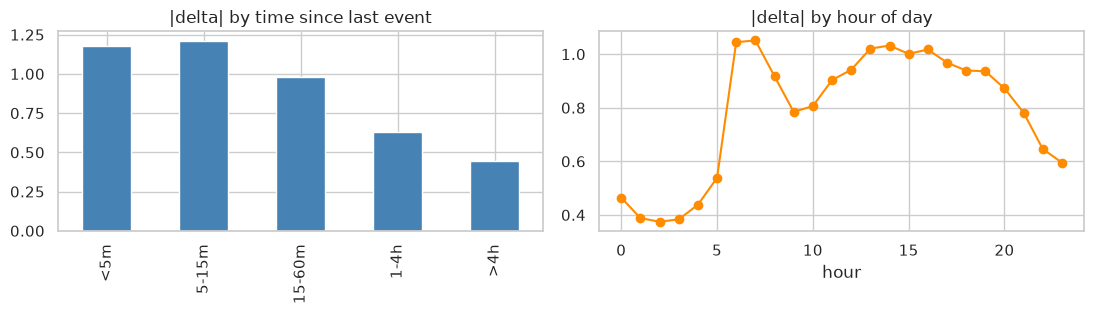

In [173]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))

b = pd.cut(anchors["minutes_since_last"], [-1, 5, 15, 60, 240, 1e9],
          labels=["<5m", "5-15m", "15-60m", "1-4h", ">4h"])
anchors.groupby(b, observed=True)["delta"].apply(lambda s: s.abs().mean()).plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="|delta| by time since last event", xlabel="")

anchors.groupby("hour")["delta"].apply(lambda s: s.abs().mean()).plot(ax=axes[1], marker="o", color="darkorange")
axes[1].set(title="|delta| by hour of day", xlabel="hour")
plt.tight_layout()

- In the `minutes_since_last` chart, you can see that the less time a station has gone without changing, the more likely it is to change soon.
- The station's own lags (1h/3h/24h) and the time since the last event capture recent behavior fairly well without needing to look at neighboring stations.

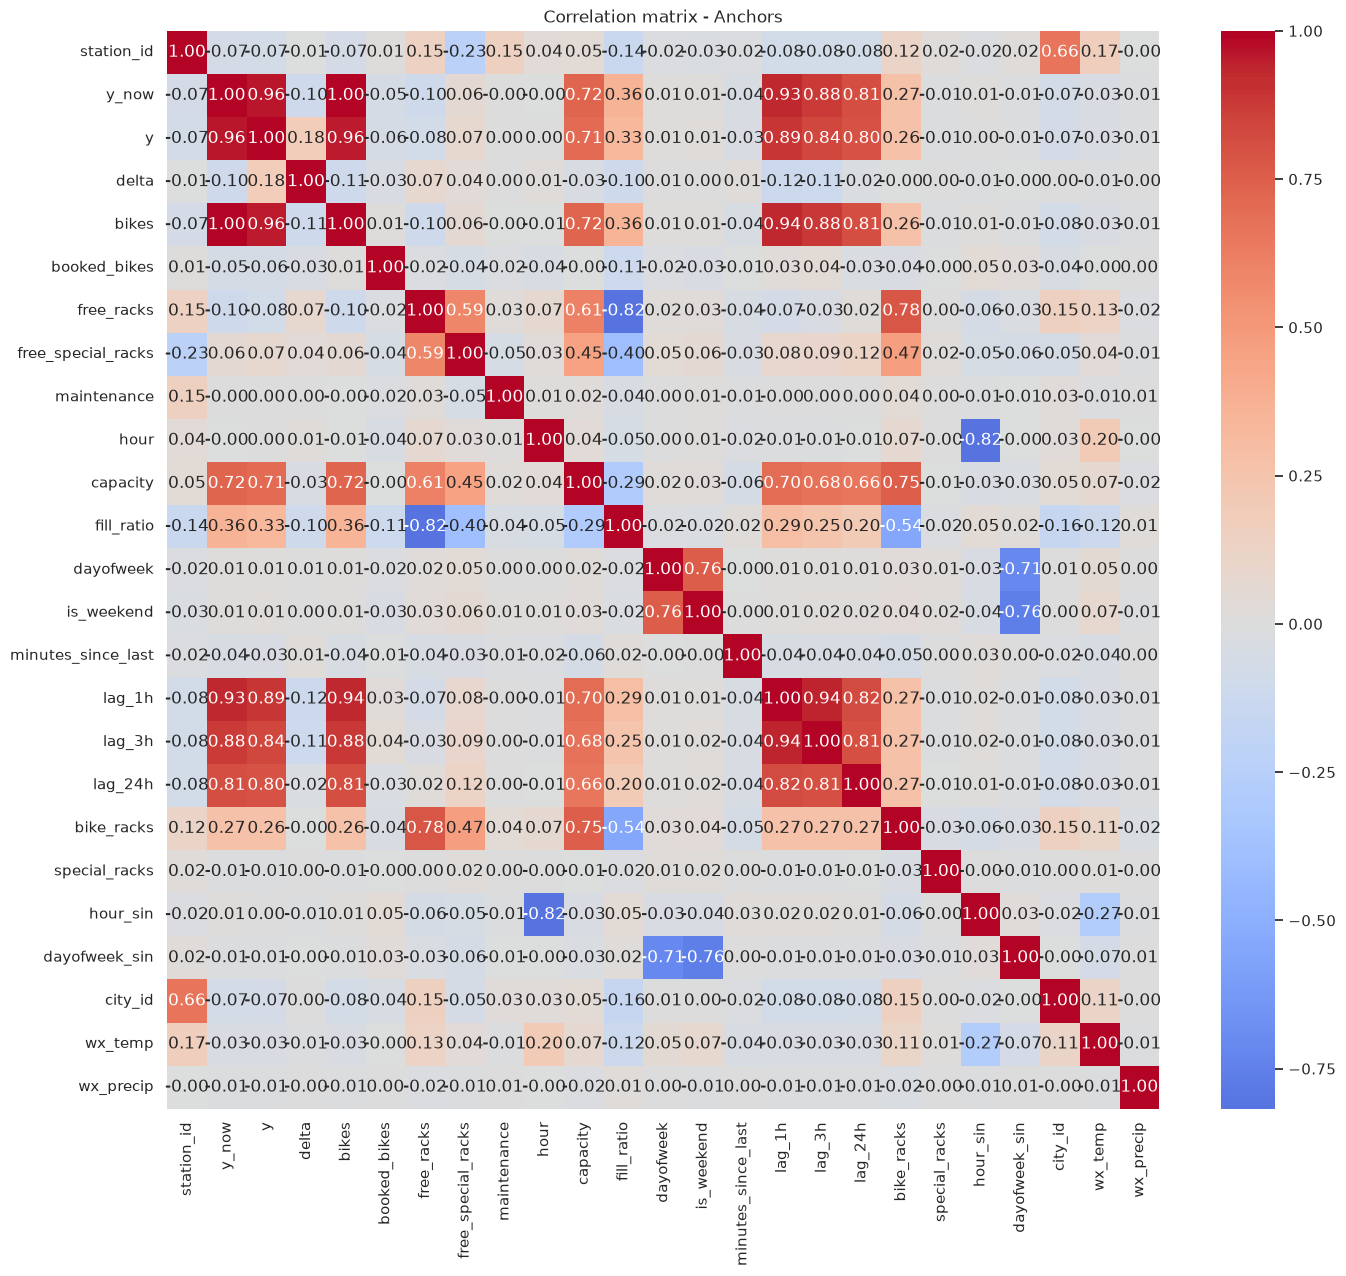

In [174]:
corr = anchors.select_dtypes(include="number").corr()
plt.figure(figsize=(16, 14))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation matrix - Anchors")
plt.show()

In [175]:
low_value_features = ["booked_bikes", "free_special_racks", "hour", "special_racks"]
# Variables that would be better as categorical:
categorical_features = ["maintenance", "dayofweek", "is_weekend"]

In [176]:
# Variables that would be better as categorical:
for c in categorical_features:
    anchors[c] = anchors[c].astype("category")

---
### 5. Baseline

In [177]:
print(stations.columns.tolist())
print(anchors.columns.tolist())

['id', 'city_id', 'terminal_type', 'place_type', 'bike_racks', 'special_racks', 'lon', 'lat']
['station_id', 'time', 'y_now', 'target_time', 'obs_time', 'y', 'delta', 'split', 'bikes', 'booked_bikes', 'free_racks', 'free_special_racks', 'maintenance', 'hour', 'local_time', 'capacity', 'fill_ratio', 'dayofweek', 'is_weekend', 'minutes_since_last', 'lag_1h', 'lag_3h', 'lag_24h', 'bike_racks', 'special_racks', 'hour_sin', 'dayofweek_sin', 'city_id', 'hour_utc', 'wx_temp', 'wx_precip']


In [178]:
features_num = [
    "y_now", "bikes", "free_racks",
    "capacity", "fill_ratio",
    "lag_1h", "lag_3h", "lag_24h",
    "minutes_since_last",
    "hour_sin", "bike_racks",
    "wx_temp",
]
features_cat = ["maintenance", "dayofweek", "is_weekend"]
feature_cols = features_num + features_cat

data = anchors.dropna(subset=feature_cols).reset_index(drop=True)

train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

print(f"train: {len(train):,}   test: {len(test):,}")
print(f"features: {len(feature_cols)} ({len(features_num)} numeric + {len(features_cat)} categorical)")

train: 2,125,249   test: 689,748
features: 15 (12 numeric + 3 categorical)


In [179]:
def metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return mae, rmse

# Persistence: "in an hour there will be the same as now"
persistence_pred = test["y_now"].to_numpy()
mae_p, rmse_p = metrics(test["y"], persistence_pred)

baselines = pd.DataFrame(
    {"MAE": [mae_p], "RMSE": [rmse_p]},
    index=["Persistence"],
)
baselines.round(4)

,MAE,RMSE
Persistence,1.0252,1.8322


We use persistence as a baseline to compare against the final model, because it's the choice of assuming that in an hour there will be the same as now. We already saw that it's right half the time, so it's a demanding comparison point — any model that doesn't beat this isn't adding anything real.

---
### 6. Models

Both learn to predict `delta` (the change), not `y` directly — that way, "predicting no
change" is exactly equivalent to persistence, and any improvement from the model is interpreted
directly as "how much better than doing nothing."

XGBoost and LightGBM are two *gradient boosting* implementations with the same principle (adding
small trees that correct the error of the previous ones) but with design differences: XGBoost
grows trees level by level, LightGBM grows whichever leaf reduces the error the most first
(*leaf-wise*), which usually makes it faster on large datasets like this one.

In [180]:
X_train, y_train = train[feature_cols], train["delta"]
X_test = test[feature_cols]

xgboost_model = xgb.XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1,
    enable_categorical=True,   # needed because maintenance/dayofweek/is_weekend are "category" dtype
)
xgboost_model.fit(X_train, y_train)
xgb_delta = xgboost_model.predict(X_test)

In [181]:
lgbm = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    min_child_samples=100, random_state=42,
)
lgbm.fit(X_train, y_train)
lgbm_delta = lgbm.predict(X_test)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.048743 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1537
[LightGBM] [Info] Number of data points in the train set: 2125249, number of used features: 15
[LightGBM] [Info] Start training from score 0.001021


In [182]:
# The predicted change is added to the current value, and clipped to a physically possible
# range: there can't be fewer than 0 bikes nor more than the station's capacity. Since it's
# a count, it's rounded to the nearest integer.
def to_level(y_now, delta_pred, capacity):
    pred = y_now + delta_pred
    pred = np.clip(pred, 0, capacity)
    return np.round(pred)


xgb_pred = to_level(test["y_now"].to_numpy(), xgb_delta, test["capacity"].to_numpy())
lgbm_pred = to_level(test["y_now"].to_numpy(), lgbm_delta, test["capacity"].to_numpy())

#### 6.1 Testing with `y` as a target

The two models above learn `delta` (the change). But several features (especially
`y_now`) have better direct correlation with `y` than with `delta` — which makes sense, because `y`
is almost always very similar to `y_now`, while `delta` is a much smaller and
noisier number. We try a third model, with the same hyperparameters as the LightGBM above,
but trained to predict `y` directly, to compare.

In [183]:
lgbm_y = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    min_child_samples=100, random_state=42,
)
lgbm_y.fit(X_train, train["y"])

y_pred_direct = lgbm_y.predict(X_test)
# No need to add y_now here (the model already predicts the final level), just clip it
# to a physically possible range and round it, same as with to_level().
y_pred_direct = np.clip(y_pred_direct, 0, test["capacity"].to_numpy())
y_pred_direct = np.round(y_pred_direct)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.055858 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1537
[LightGBM] [Info] Number of data points in the train set: 2125249, number of used features: 15
[LightGBM] [Info] Start training from score 6.379608


---
### 7. Evaluation on test (data never seen during training)

In [184]:
mae_xgb, rmse_xgb = metrics(test["y"], xgb_pred)
mae_lgbm, rmse_lgbm = metrics(test["y"], lgbm_pred)
mae_direct, rmse_direct = metrics(test["y"], y_pred_direct)

results = pd.concat([
    baselines,
    pd.DataFrame(
        {"MAE": [mae_xgb, mae_lgbm, mae_direct], "RMSE": [rmse_xgb, rmse_lgbm, rmse_direct]},
        index=["XGBoost", "LightGBM", "LightGBM (target y)"],
    ),
])
results.round(4)

,MAE,RMSE
Persistence,1.0252,1.8322
XGBoost,1.0355,1.7599
LightGBM,1.0329,1.7586
LightGBM (target y),1.0341,1.7595


- We have a real but small improvement over persistence in RMSE, but not in MAE.
- Between LightGBM and XGBoost, we'll stick with LightGBM on the delta target — despite the similar results, LightGBM usually trains faster on large datasets like this one. There isn't much difference in interpretability between the two, so I'd go with the faster one.

#### 7.1 Feature importance

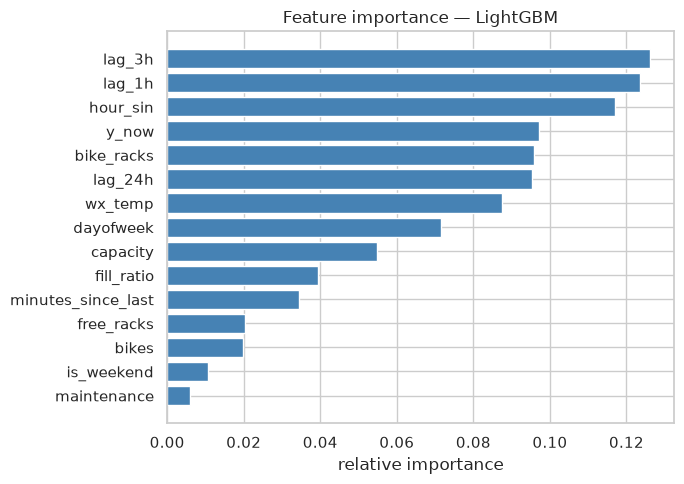

In [185]:
importances = pd.DataFrame({
    "feature": feature_cols,
    "xgboost": xgboost_model.feature_importances_,
    "lightgbm": lgbm.feature_importances_ / lgbm.feature_importances_.sum(),
    "lightgbm_y": lgbm_y.feature_importances_ / lgbm_y.feature_importances_.sum(),
}).sort_values("lightgbm", ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
order = importances.sort_values("lightgbm")
ax.barh(order["feature"], order["lightgbm"], color="steelblue")
ax.set(title="Feature importance — LightGBM", xlabel="relative importance")
plt.tight_layout()

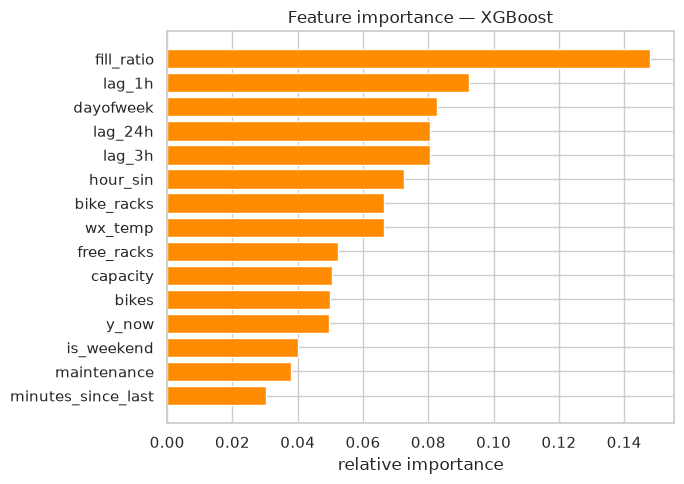

In [186]:
fig, ax = plt.subplots(figsize=(7, 5))
order = importances.sort_values("xgboost")
ax.barh(order["feature"], order["xgboost"], color="darkorange")
ax.set(title="Feature importance — XGBoost", xlabel="relative importance")
plt.tight_layout()

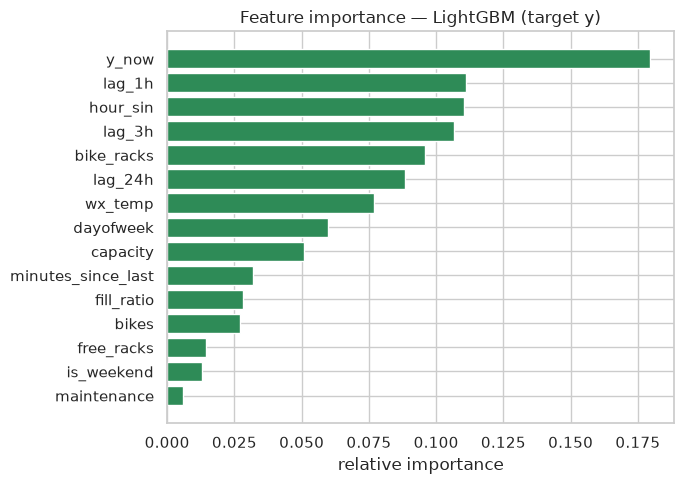

In [187]:
fig, ax = plt.subplots(figsize=(7, 5))
order = importances.sort_values("lightgbm_y")
ax.barh(order["feature"], order["lightgbm_y"], color="seagreen")
ax.set(title="Feature importance — LightGBM (target y)", xlabel="relative importance")
plt.tight_layout()

- It depends on the model: for LightGBM the lags dominate (`lag_3h`, `lag_1h`), followed by hour_sin and y_now.
- The temperature variable (`wx_temp`) didn't contribute as much as expected — I thought it would matter more.

#### 7.2 Removing low-importance variables

We observed that free_racks, bikes, is_weekend, capacity and maintenance don't contribute much, so we'll remove them and retrain the models to compare.

In [188]:
drop_num = ["bikes", "free_racks", "capacity"]
drop_cat = ["maintenance", "is_weekend"]

features_num_reduced = [c for c in features_num if c not in drop_num]
features_cat_reduced = [c for c in features_cat if c not in drop_cat]
feature_cols_reduced = features_num_reduced + features_cat_reduced

X_train_r = train[feature_cols_reduced]
X_test_r = test[feature_cols_reduced]

print(f"features before: {len(feature_cols)}  ->  features after: {len(feature_cols_reduced)}")

features before: 15  ->  features after: 10


In [189]:
lgbm_r = lgb.LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    min_child_samples=100, random_state=42,
)
lgbm_r.fit(X_train_r, y_train)
lgbm_delta_r = lgbm_r.predict(X_test_r)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017270 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1233
[LightGBM] [Info] Number of data points in the train set: 2125249, number of used features: 10
[LightGBM] [Info] Start training from score 0.001021


In [190]:
lgbm_pred_r = to_level(test["y_now"].to_numpy(), lgbm_delta_r, test["capacity"].to_numpy())
mae_lgbm_r, rmse_lgbm_r = metrics(test["y"], lgbm_pred_r)

comparison = pd.DataFrame(
    {
        "MAE": [mae_p, mae_xgb, mae_lgbm, mae_direct, mae_lgbm_r],
        "RMSE": [rmse_p, rmse_xgb, rmse_lgbm, rmse_direct, rmse_lgbm_r],
    },
    index=[
        "Persistence",
        "XGBoost (all)", "LightGBM (all)", "LightGBM target y (all)",
        "LightGBM (reduced)",
    ],
)
comparison.round(4)

,MAE,RMSE
Persistence,1.0252,1.8322
XGBoost (all),1.0355,1.7599
LightGBM (all),1.0329,1.7586
LightGBM target y (all),1.0341,1.7595
LightGBM (reduced),1.0339,1.7631


- Removing those 5 variables (`free_racks`, `bikes`, `is_weekend`, `capacity`, `maintenance`) makes the model a little worse.
- But, with 10 variables instead of 15 the model is easier to explain and justify in the presentation, and the performance difference is minimal.

#### 7.3 Error Analysis

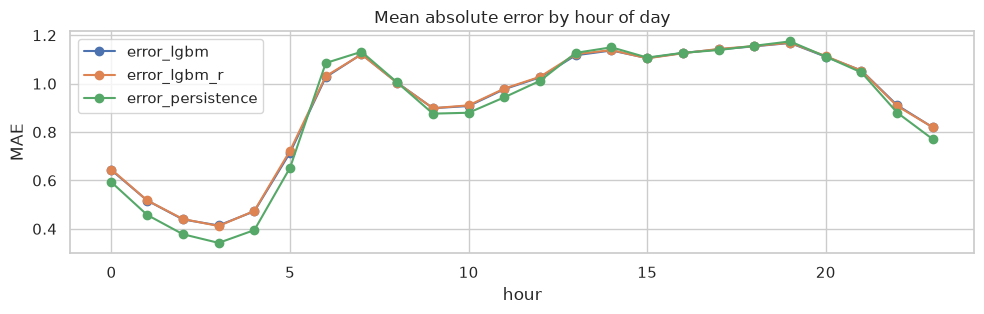

In [191]:
test = test.copy()
test["pred_lgbm"] = lgbm_pred
test["pred_lgbm_r"] = lgbm_pred_r
test["error_lgbm"] = (test["pred_lgbm"] - test["y"]).abs()
test["error_lgbm_r"] = (test["pred_lgbm_r"] - test["y"]).abs()
test["error_persistence"] = (test["y_now"] - test["y"]).abs()

by_hour = test.groupby("hour")[["error_lgbm", "error_lgbm_r", "error_persistence"]].mean()

fig, ax = plt.subplots(figsize=(10, 3.3))
by_hour.plot(ax=ax, marker="o")
ax.set(title="Mean absolute error by hour of day", xlabel="hour", ylabel="MAE")
plt.tight_layout()

- Both LightGBMs (all and reduced) win in almost the same hours: 6-8h (people starting to move in the morning) and 13-20h (afternoon/evening). In those windows there are more real changes to anticipate than in a quiet hour.
- In the early morning (0-5h), mid-morning (9-12h) and at night (21-23h) persistence is better for both models — these are hours where almost nothing happens, so "not changing anything" is already close to optimal. Overall, LightGBM (all) beats persistence in 10 of the 24 hours, and LightGBM (reduced) in 9 of the 24 — a minimal difference, consistent with the reduced model being just slightly weaker.

---
### 8. Evaluation

In [192]:
# 8.1 Load data
EVAL_DIR = ROOT + "/bike_sharing_challenge_2026_eval"
stations_eval = pd.read_csv(EVAL_DIR + "/stations_eval.csv")
status_eval = pd.read_csv(EVAL_DIR + "/stations_status_eval.csv")

In [193]:
print(stations_eval.shape)
stations_eval.head()

(213, 11)


,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,139041176,773,KLARA Sparchen,32524,sign,23,1,0,NaN,12.178860,47.590185
1,60956597,266,Parkinsel - Festival des deutschen Films,25064,smart_sign,0,0,0,NaN,8.460106,49.472942
2,66096128,709,Písek - Jaromíra Malého (potraviny),48393,sign,27,0,0,NaN,14.163941,49.311351
3,66097105,709,Písek - V.Kršky/O.Jeremiáše,48398,sign,27,0,0,NaN,14.163458,49.305846
4,66097683,709,Písek - Budějovická (u zastávky),48401,sign,0,0,0,NaN,14.159811,49.301859


In [194]:
print(status_eval.shape)
status_eval.head()

(517787, 8)


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,5445382,1.661531e+09,9,0,9,7,7,False
1,50401562,1.661531e+09,5,0,5,7,7,False
2,344835,1.661531e+09,9,0,9,3,0,False
3,5445387,1.661531e+09,4,0,4,12,12,False
4,5445396,1.661531e+09,11,0,11,5,5,False


In [195]:
# 8.2. Formatting the data
# unit="s" because the time comes in epoch (seconds since 1970); it's cast to nanoseconds
# so it combines well with the rest of the notebook in the merge_asof calls below.
status_eval["time"] = pd.to_datetime(status_eval["time"], unit="s", utc=True).astype("datetime64[ns, UTC]")
status_eval["maintenance"] = status_eval["maintenance"].astype(int)

# They don't come with local_time/hour: we need to compute them from each
# station's city timezone (same as was done in the 3.1 cleaning).
status_eval = status_eval.merge(
    stations_eval[["id", "city_id"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)
status_eval = status_eval.merge(
    cities[["id", "timezone"]].rename(columns={"id": "city_id"}),
    on="city_id", how="left",
)

status_eval["local_time"] = pd.NaT
for tz, idx in status_eval.groupby("timezone").groups.items():
    status_eval.loc[idx, "local_time"] = status_eval.loc[idx, "time"].dt.tz_convert(tz).dt.tz_localize(None)
status_eval["hour"] = status_eval["local_time"].dt.hour

print(f"date range: {status_eval['time'].min()} -> {status_eval['time'].max()}")
print(f"stations also seen in training: {stations_eval['id'].isin(stations['id']).sum()}")

date range: 2022-08-26 14:48:01+00:00 -> 2023-07-15 21:59:01+00:00
stations also seen in training: 0


In [196]:
# The cache from section 4.6 only has the training cities; the evaluation ones are new, so we need to check if any are missing and download them
missing_cities = stations_eval[~stations_eval["city_id"].isin(weather["city_id"])]["city_id"].unique()

missing_cities.shape

(0,)

No missing cities without weather variables

In [197]:
# 8.3. Target
anchors_eval = status_eval[["station_id", "time", "bikes_available_to_rent"]].copy()
anchors_eval = anchors_eval.rename(columns={"bikes_available_to_rent": "y_now"})
anchors_eval["target_time"] = anchors_eval["time"] + pd.Timedelta(hours=1)

future_eval = status_eval[["station_id", "time", "bikes_available_to_rent"]].rename(
    columns={"time": "obs_time", "bikes_available_to_rent": "y"}
).sort_values("obs_time")
anchors_eval = anchors_eval.sort_values("target_time")
anchors_eval = pd.merge_asof(
    anchors_eval, future_eval,
    left_on="target_time", right_on="obs_time",
    by="station_id", direction="backward",
)
anchors_eval["delta"] = anchors_eval["y"] - anchors_eval["y_now"]

In [198]:
# 8.4. Features (only the ones LightGBM reduced uses)
state_cols = ["bikes", "free_racks", "hour", "local_time"]
anchors_eval = anchors_eval.merge(status_eval[["station_id", "time"] + state_cols], on=["station_id", "time"], how="left")

anchors_eval["capacity"] = anchors_eval["bikes"] + anchors_eval["free_racks"]
anchors_eval["fill_ratio"] = anchors_eval["y_now"] / anchors_eval["capacity"].replace(0, np.nan)
anchors_eval["dayofweek"] = anchors_eval["local_time"].dt.dayofweek
anchors_eval["hour_sin"] = np.sin(2 * np.pi * anchors_eval["hour"] / 24)

status_eval["minutes_since_last"] = status_eval.groupby("station_id")["time"].diff().dt.total_seconds() / 60
anchors_eval = anchors_eval.merge(
    status_eval[["station_id", "time", "minutes_since_last"]], on=["station_id", "time"], how="left",
)
anchors_eval["minutes_since_last"] = anchors_eval["minutes_since_last"].fillna(0)

anchors_eval["lag_1h"] = value_n_hours_ago(anchors_eval, status_eval, 1)
anchors_eval["lag_3h"] = value_n_hours_ago(anchors_eval, status_eval, 3)
anchors_eval["lag_24h"] = value_n_hours_ago(anchors_eval, status_eval, 24)
for c in ["lag_1h", "lag_3h", "lag_24h"]:
    anchors_eval[c] = anchors_eval[c].fillna(anchors_eval["y_now"])

anchors_eval = anchors_eval.merge(
    stations_eval[["id", "bike_racks", "city_id"]].rename(columns={"id": "station_id"}),
    on="station_id", how="left",
)

# Weather
anchors_eval["hour_utc"] = anchors_eval["time"].dt.floor("h")
anchors_eval = anchors_eval.merge(
    weather[["city_id", "weather_time", "wx_temp"]].rename(columns={"weather_time": "hour_utc"}),
    on=["city_id", "hour_utc"], how="left",
)

In [199]:
# 8.5. Prediction with reduced LightGBM
data_eval = anchors_eval.dropna(subset=feature_cols_reduced + ["capacity"]).reset_index(drop=True)

data_eval["dayofweek"] = pd.Categorical(data_eval["dayofweek"], categories=range(7))
X_eval = data_eval[feature_cols_reduced]

lgbm_delta_eval = lgbm_r.predict(X_eval)
data_eval["lgbm_pred"] = to_level(data_eval["y_now"].to_numpy(), lgbm_delta_eval, data_eval["capacity"].to_numpy())

persistence_pred_eval = data_eval["y_now"].to_numpy()
mae_p_eval, rmse_p_eval = metrics(data_eval["y"], persistence_pred_eval)
mae_lgbm_eval, rmse_lgbm_eval = metrics(data_eval["y"], data_eval["lgbm_pred"])

results_eval = pd.DataFrame(
    {"MAE": [mae_p_eval, mae_lgbm_eval], "RMSE": [rmse_p_eval, rmse_lgbm_eval]},
    index=["Persistence", "LightGBM (reduced)"],
)
print(f"rows evaluated: {len(data_eval):,}  (out of {len(stations_eval)} stations never seen in training)")
results_eval.round(4)

rows evaluated: 505,299  (out of 213 stations never seen in training)


,MAE,RMSE
Persistence,1.4471,2.9696
LightGBM (reduced),1.4456,2.8873


- On the 213 new, never-seen stations we get MAE 1.4456 / RMSE 2.8873, beating the persistence baseline.

#### 8.6 Export predictions

We save the predictions for the new stations, like the clustering part does with `station_clusters.csv`.

In [200]:
OUT_DIR = ROOT + "/output/prediction"
os.makedirs(OUT_DIR, exist_ok=True)

export = data_eval[["station_id", "city_id", "time", "target_time", "y_now", "lgbm_pred", "y"]].rename(columns={
    "time": "time_utc",
    "target_time": "target_time_utc",
    "lgbm_pred": "pred_bikes_available_1h",
    "y": "observed_bikes_available_1h",
})
export.to_csv(OUT_DIR + "/eval_predictions.csv", index=False)
print(f"saved {len(export):,} rows to output/prediction/eval_predictions.csv")
export.head()

saved 505,299 rows to output/prediction/eval_predictions.csv


,station_id,city_id,time_utc,target_time_utc,y_now,pred_bikes_available_1h,observed_bikes_available_1h
0,5445375,450,2022-08-26 14:48:01+00:00,2022-08-26 15:48:01+00:00,5,5.0,5
1,5445476,450,2022-08-26 14:49:01+00:00,2022-08-26 15:49:01+00:00,8,8.0,10
2,41480646,266,2022-08-26 14:49:01+00:00,2022-08-26 15:49:01+00:00,12,12.0,12
3,5445375,450,2022-08-26 14:49:01+00:00,2022-08-26 15:49:01+00:00,4,4.0,5
4,4648333,439,2022-08-26 14:50:01+00:00,2022-08-26 15:50:01+00:00,13,13.0,13


---
### 9. Conclusions and limitations

**Conclusions**

- Station_status is an irregular event record, so the "t+1h" record does not always exist for "t" hour. Therefore, the target variable was constructed by applying LOCF (Last Observation Carried Forward) at t+1h. In 53% of the hours, no change occurs, making persistence a challenging baseline
- LightGBM improves RMSE (1.759 vs 1.832) but not MAE, so it helps more with the big changes, which are the ones that matter to move bikes between stations.
- It wins in the busy hours (6-8h and 13-20h); in the quiet hours persistence is already good enough.
- On the 213 new stations it still beats persistence (RMSE 2.887 vs 2.970), so the model also works on stations it never saw.

**Limitations**
- The target is built with LOCF, and 38.4% of the anchors have no event in the next hour, so we assume nothing changed but we can't be 100% sure.
- We used the real weather (API open-meteo), not a forecast, so in real life the weather variable would be a bit less reliable.
- Each station is predicted alone: no neighbouring stations, events or rebalancing done by the operator.